IT3091 Machine Learning Group Assignment

Group: 2026-AI-40


## Notebook Roadmap

1. Business problem framing
2. Project initialization and reproducibility
3. Data loading and data dictionary
4. Data understanding and raw-data quality audit
5. Exploratory data analysis (EDA)
6. EDA insight log and preprocessing handover
7. Customer-level feature engineering
8. Unsupervised clustering models and comparison
9. Cluster evaluation and interpretation
10. Segment-specific market-basket analysis
11. Business recommendations, limitations, and conclusion

## 1. Business Problem Framing and Exploratory Data Analysis - IT24100802 -Ranawansha P.G.D.D

### Business Context
The dataset contains transaction-level records from a UK-based online gift retailer. The retailer aims to improve sales, customer retention, and product strategy using historical transaction data.

### Stakeholder
The primary stakeholder is the retailer's marketing and customer relationship management (CRM) team. Secondary stakeholders include merchandising and inventory teams.

### Primary Decision Lens: Customer Segmentation
The primary objective is to identify meaningful and actionable customer groups based on purchasing behaviour. Since the dataset does not contain a predefined customer-level target label, customer segmentation is a suitable unsupervised learning task.

### Secondary Lens: Product Association and Bundling
The secondary objective is to discover product associations within the customer segments identified by the primary analysis. Instead of producing generic rules for every customer, segment-specific market-basket analysis can produce more targeted bundle and cross-selling recommendations.

### Unit of Analysis
- Raw-data stage: One row represents one item within an invoice (invoice-line transaction).
- Customer-segmentation stage: One row will represent one customer after transaction-level data are aggregated.
- Association-rule stage: One transaction will represent one completed invoice/basket.

### Proposed Output
1. Interpretable customer segments using RFM and augmented behavioural features.
2. Comparison of multiple clustering methods.
3. Segment-specific product-association rules using Apriori.
4. Evidence-based marketing, retention, cross-selling, and bundling recommendations.

In [1]:
# 2. Project Initialization and Reproducibility

import os
import sys
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Plot styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Random seed:", RANDOM_STATE)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.1.3
Random seed: 42


3. Mount Google Drive and Load Data
Code cell

In [2]:
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/ML Project/Online Retail.xlsx"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_PATH}\n\n"
        "Please verify that the folder is named 'ML Project' and "
        "the file is named 'Online Retail.xlsx'."
    )

print("Dataset found successfully:")
print(DATA_PATH)

Mounted at /content/drive
Dataset found successfully:
/content/drive/MyDrive/ML Project/Online Retail.xlsx


In [3]:
# Load the Online Retail Excel dataset
df_raw = pd.read_excel(DATA_PATH, engine="openpyxl")

print("Raw dataset loaded successfully.")
print("Raw shape (rows, columns):", df_raw.shape)

display(df_raw.head())

Raw dataset loaded successfully.
Raw shape (rows, columns): (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Create a copy of dataframe

In [4]:
# Keep df_raw unchanged for auditing and reproducibility.
df = df_raw.copy()

print("Working dataframe created.")

Working dataframe created.


4. Dataset Source and Fingerprint

**Dataset:** UCI Machine Learning Repository – Online Retail  
**Source:** https://archive.ics.uci.edu/dataset/352/online+retail  
**File used:** `Online Retail.xlsx`  
**Raw file location:** Google Drive → `MyDrive/ML Project/Online Retail.xlsx`  
**Dataset period:** December 2010 to December 2011  
**Raw unit of analysis:** An invoice-line transaction, where each row records one product in an invoice.

In [5]:
import hashlib

def get_file_hash(file_path, algorithm="sha256"):
    hash_object = hashlib.new(algorithm)
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_object.update(chunk)
    return hash_object.hexdigest()

file_size_mb = os.path.getsize(DATA_PATH) / (1024 * 1024)
file_hash = get_file_hash(DATA_PATH)

print("Dataset file name:", Path(DATA_PATH).name)
print(f"Dataset file size: {file_size_mb:.2f} MB")
print("SHA-256 fingerprint:", file_hash)
print("Load timestamp:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

Dataset file name: Online Retail.xlsx
Dataset file size: 22.62 MB
SHA-256 fingerprint: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Load timestamp: 2026-10-11 06:40:46


5. Data Dictionary

The following table describes the variables in the raw Online Retail dataset and how each will be used in the project.

In [6]:
data_dictionary = pd.DataFrame({
    "Variable": [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ],
    "Expected Type": [
        "Object / String",
        "Object / String",
        "Object / String",
        "Integer / Numeric",
        "Datetime",
        "Float / Numeric",
        "Float / Identifier",
        "Object / Categorical"
    ],
    "Row-Level Meaning": [
        "Invoice identifier; invoices beginning with 'C' usually indicate cancellations.",
        "Product or item identifier.",
        "Product description.",
        "Number of units purchased or returned.",
        "Date and time of invoice creation.",
        "Price per product unit.",
        "Unique customer identifier.",
        "Country where the customer is located."
    ],
    "Planned Use": [
        "Detect cancellations; aggregate baskets and transactions.",
        "Identify products for item diversity and association rules.",
        "Readable product labels for EDA and association-rule interpretation.",
        "Calculate purchase quantity, returns, and basket statistics.",
        "Calculate recency and temporal purchasing patterns.",
        "Calculate line-level revenue and monetary value.",
        "Aggregate transactions into customer-level segmentation features.",
        "Geographical EDA and potential customer-profile interpretation."
    ]
})

display(data_dictionary)

,Variable,Expected Type,Row-Level Meaning,Planned Use
0,InvoiceNo,Object / String,Invoice identifier; invoices beginning with 'C...,Detect cancellations; aggregate baskets and tr...
1,StockCode,Object / String,Product or item identifier.,Identify products for item diversity and assoc...
2,Description,Object / String,Product description.,Readable product labels for EDA and associatio...
3,Quantity,Integer / Numeric,Number of units purchased or returned.,"Calculate purchase quantity, returns, and bask..."
4,InvoiceDate,Datetime,Date and time of invoice creation.,Calculate recency and temporal purchasing patt...
5,UnitPrice,Float / Numeric,Price per product unit.,Calculate line-level revenue and monetary value.
6,CustomerID,Float / Identifier,Unique customer identifier.,Aggregate transactions into customer-level seg...
7,Country,Object / Categorical,Country where the customer is located.,Geographical EDA and potential customer-profil...


In [7]:
# Compare observed columns against expected project columns
expected_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

actual_columns = df_raw.columns.tolist()

print("Actual columns:", actual_columns)
print("\nMissing expected columns:", sorted(set(expected_columns) - set(actual_columns)))
print("Unexpected columns:", sorted(set(actual_columns) - set(expected_columns)))

Actual columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing expected columns: []
Unexpected columns: []


6. Basic Data Understanding

In [8]:
print("Dataset shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame(name="Data Type"))

print("\nFirst five rows:")
display(df_raw.head())

print("\nLast five rows:")
display(df_raw.tail())

print("\nDataset information:")
df_raw.info()

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:


,Data Type
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object



First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
print("Numerical summary:")
display(df_raw.describe().T)

print("Categorical summary:")
display(df_raw.describe(include="object").T)

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


Categorical summary:


,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478


The raw dataset is stored at invoice line level rather than customer level. Therefore, direct clustering of raw rows would be inappropriate because multiple rows can belong to the same customer and the same invoice.

For customer segmentation, the data must later be aggregated into a customer-level analytical dataset.

7. Missing-Value Audit

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing Percentage (%)": (df_raw.isna().mean() * 100).round(2),
    "Non-Missing Count": df_raw.notna().sum(),
    "Data Type": df_raw.dtypes.astype(str)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage (%),Non-Missing Count,Data Type
CustomerID,135080,24.93,406829,float64
Description,1454,0.27,540455,object
StockCode,0,0.00,541909,object
InvoiceNo,0,0.00,541909,object
Quantity,0,0.00,541909,int64
InvoiceDate,0,0.00,541909,datetime64[ns]
UnitPrice,0,0.00,541909,float64
Country,0,0.00,541909,object


In [11]:

# Original Dataset: Variable Types, Missingness, and Cardinality

original_feature_summary = pd.DataFrame({
    "Column": df_raw.columns,
    "Data Type": df_raw.dtypes.astype(str).values,
    "Missing Count": df_raw.isna().sum().values,
    "Missing (%)": (df_raw.isna().mean() * 100).round(2).values,
    "Unique Values": df_raw.nunique(dropna=True).values,
    "Unique (%)": (df_raw.nunique(dropna=True) / len(df_raw) * 100).round(2).values
})

display(original_feature_summary)

,Column,Data Type,Missing Count,Missing (%),Unique Values,Unique (%)
0,InvoiceNo,object,0,0.00,25900,4.78
1,StockCode,object,0,0.00,4070,0.75
2,Description,object,1454,0.27,4223,0.78
3,Quantity,int64,0,0.00,722,0.13
4,InvoiceDate,datetime64[ns],0,0.00,23260,4.29
5,UnitPrice,float64,0,0.00,1630,0.30
6,CustomerID,float64,135080,24.93,4372,0.81
7,Country,object,0,0.00,38,0.01


Numerical Features: Quantity and UnitPrice

In [12]:
numerical_original_features = ["Quantity", "UnitPrice"]

for column in numerical_original_features:
    print(f"\n{'='*70}")
    print(f"Summary statistics for: {column}")
    print(f"{'='*70}")

    display(
        df_raw[column].describe(
            percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        ).to_frame(name=column)
    )

    print(f"Skewness: {df_raw[column].skew():.2f}")
    print(f"Values <= 0: {(df_raw[column] <= 0).sum():,}")
    print(f"Values > 0: {(df_raw[column] > 0).sum():,}")


Summary statistics for: Quantity


,Quantity
count,541909.000000
mean,9.552250
std,218.081158
min,-80995.000000
1%,-2.000000
5%,1.000000
10%,1.000000
25%,1.000000
50%,3.000000
75%,10.000000


Skewness: -0.26
Values <= 0: 10,624
Values > 0: 531,285

Summary statistics for: UnitPrice


,UnitPrice
count,541909.000000
mean,4.611114
std,96.759853
min,-11062.060000
1%,0.190000
5%,0.420000
10%,0.630000
25%,1.250000
50%,2.080000
75%,4.130000


Skewness: 186.51
Values <= 0: 2,517
Values > 0: 539,392


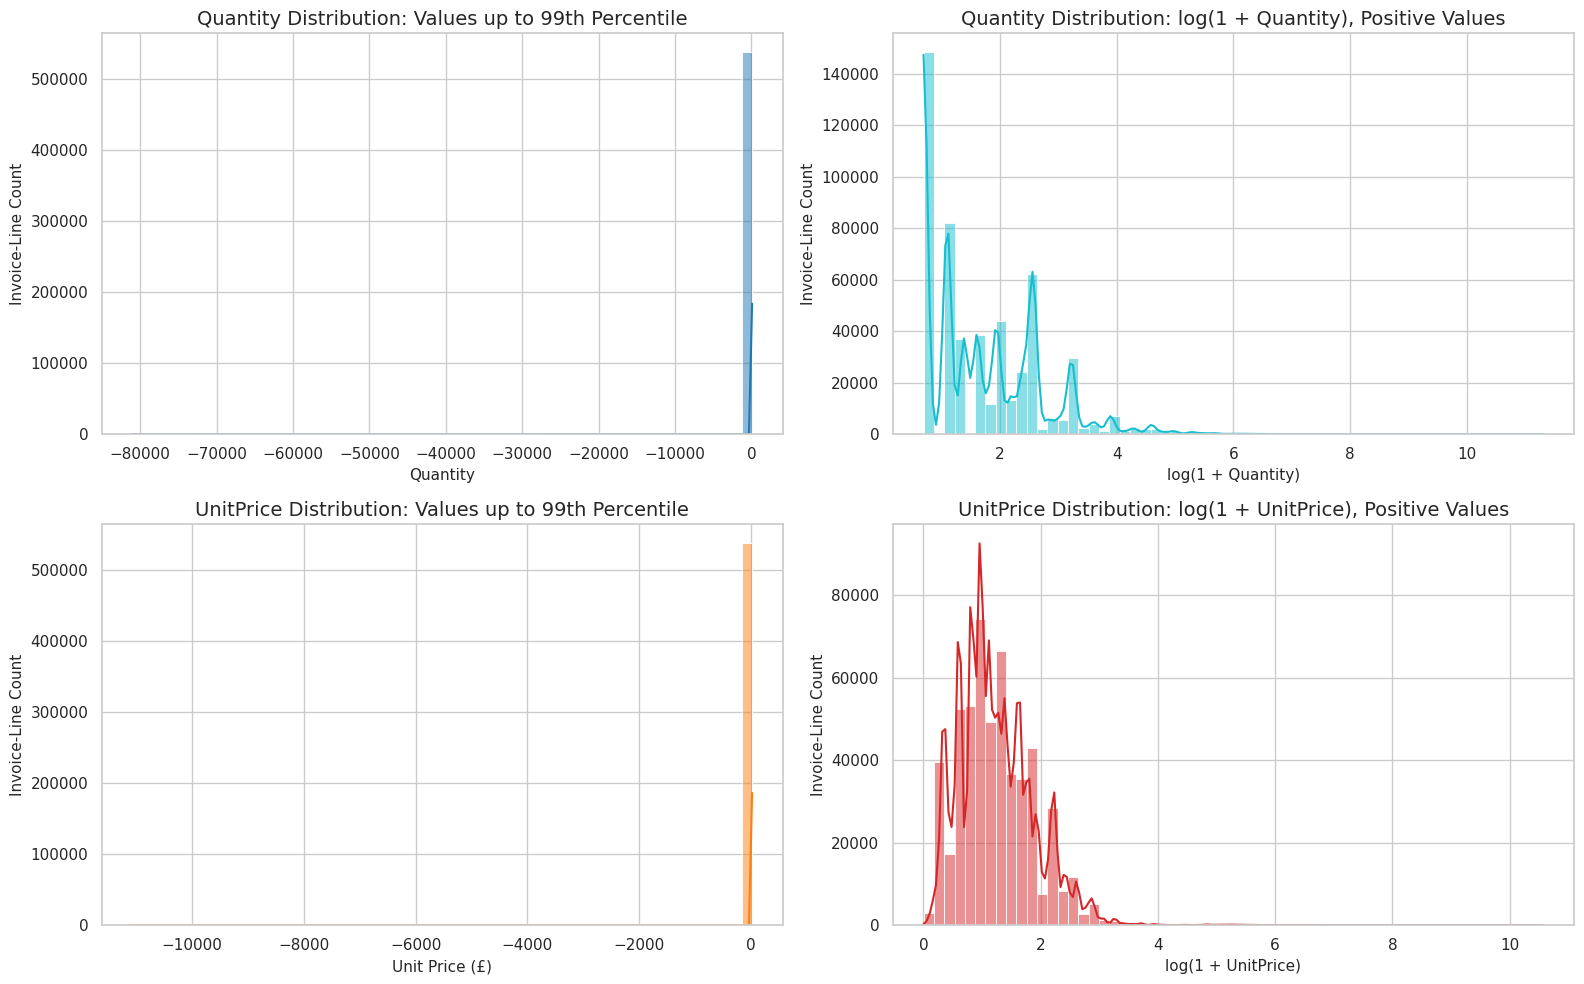

In [13]:
# Histograms and boxplots for original numeric variables
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Quantity: raw histogram restricted to central 99% for visibility
quantity_99 = df_raw["Quantity"].quantile(0.99)

sns.histplot(
    data=df_raw[df_raw["Quantity"] <= quantity_99],
    x="Quantity",
    bins=60,
    kde=True,
    ax=axes[0, 0],
    color="#1f77b4"
)
axes[0, 0].set_title("Quantity Distribution: Values up to 99th Percentile")
axes[0, 0].set_xlabel("Quantity")
axes[0, 0].set_ylabel("Invoice-Line Count")

# Quantity: log scale, only positive values
sns.histplot(
    np.log1p(df_raw.loc[df_raw["Quantity"] > 0, "Quantity"]),
    bins=60,
    kde=True,
    ax=axes[0, 1],
    color="#17becf"
)
axes[0, 1].set_title("Quantity Distribution: log(1 + Quantity), Positive Values")
axes[0, 1].set_xlabel("log(1 + Quantity)")
axes[0, 1].set_ylabel("Invoice-Line Count")

# UnitPrice: raw histogram restricted to central 99% for visibility
unitprice_99 = df_raw["UnitPrice"].quantile(0.99)

sns.histplot(
    data=df_raw[df_raw["UnitPrice"] <= unitprice_99],
    x="UnitPrice",
    bins=60,
    kde=True,
    ax=axes[1, 0],
    color="#ff7f0e"
)
axes[1, 0].set_title("UnitPrice Distribution: Values up to 99th Percentile")
axes[1, 0].set_xlabel("Unit Price (£)")
axes[1, 0].set_ylabel("Invoice-Line Count")

# UnitPrice: log scale, only positive values
sns.histplot(
    np.log1p(df_raw.loc[df_raw["UnitPrice"] > 0, "UnitPrice"]),
    bins=60,
    kde=True,
    ax=axes[1, 1],
    color="#d62728"
)
axes[1, 1].set_title("UnitPrice Distribution: log(1 + UnitPrice), Positive Values")
axes[1, 1].set_xlabel("log(1 + UnitPrice)")
axes[1, 1].set_ylabel("Invoice-Line Count")

plt.tight_layout()
plt.show()

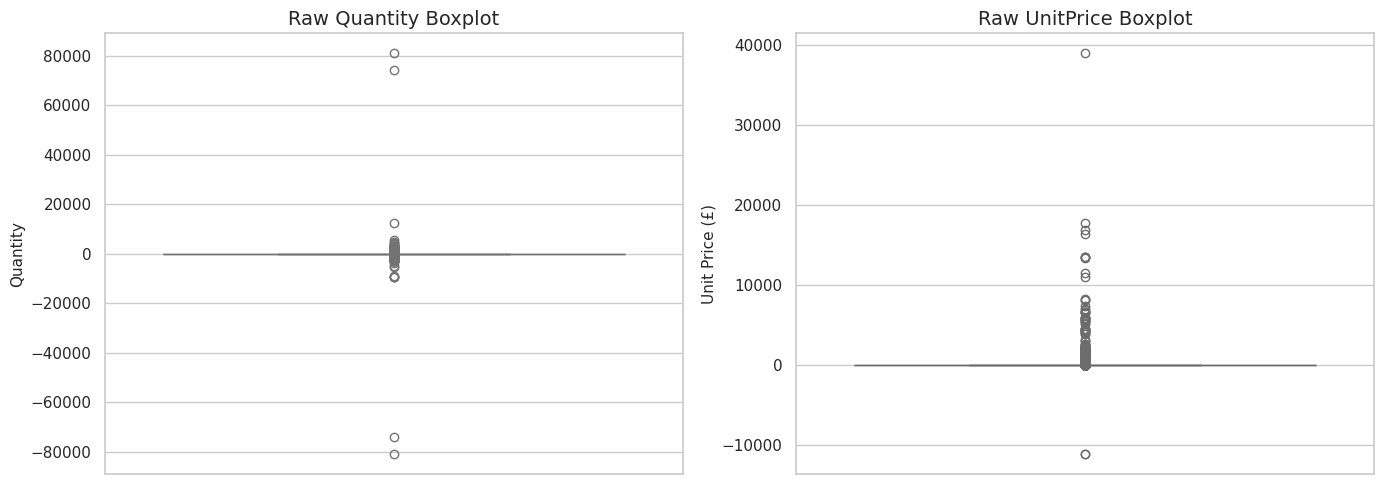

In [14]:
# Raw numeric boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df_raw["Quantity"], ax=axes[0], color="#9ecae1")
axes[0].set_title("Raw Quantity Boxplot")
axes[0].set_ylabel("Quantity")

sns.boxplot(y=df_raw["UnitPrice"], ax=axes[1], color="#fdae6b")
axes[1].set_title("Raw UnitPrice Boxplot")
axes[1].set_ylabel("Unit Price (£)")

plt.tight_layout()
plt.show()

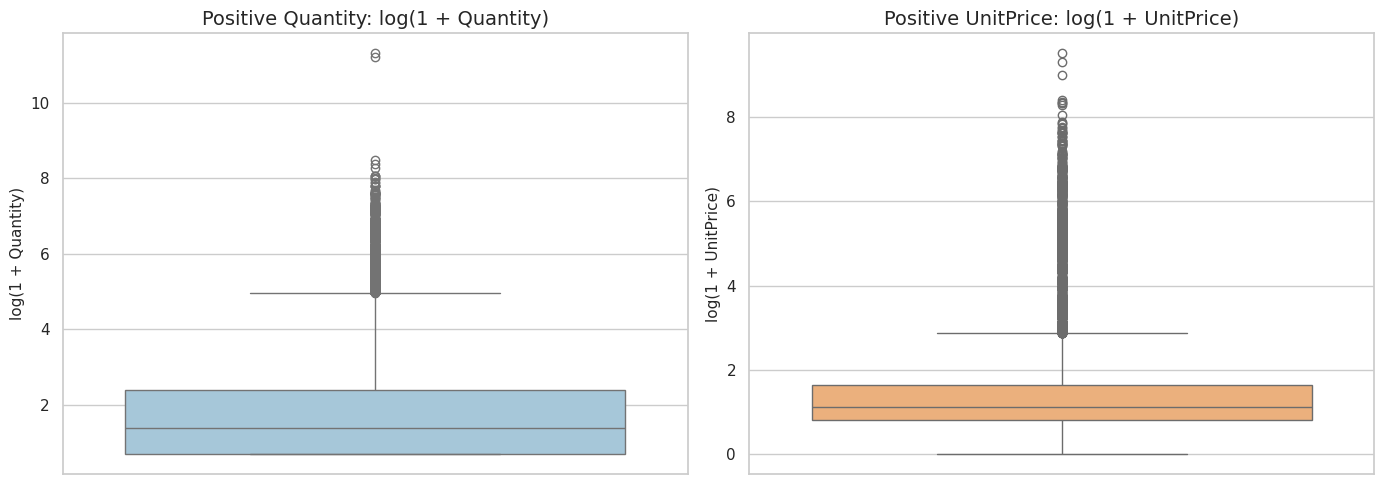

In [15]:
# Log-transformed boxplots for readable outlier/skewness inspection
positive_numeric = df_raw.loc[
    (df_raw["Quantity"] > 0) & (df_raw["UnitPrice"] > 0),
    ["Quantity", "UnitPrice"]
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=np.log1p(positive_numeric["Quantity"]), ax=axes[0], color="#9ecae1")
axes[0].set_title("Positive Quantity: log(1 + Quantity)")
axes[0].set_ylabel("log(1 + Quantity)")

sns.boxplot(y=np.log1p(positive_numeric["UnitPrice"]), ax=axes[1], color="#fdae6b")
axes[1].set_title("Positive UnitPrice: log(1 + UnitPrice)")
axes[1].set_ylabel("log(1 + UnitPrice)")

plt.tight_layout()
plt.show()

 InvoiceNo Distribution

In [16]:

# InvoiceNo Distribution: Invoice-Line Counts and Cancellations

invoice_raw_eda = df_raw.copy()

invoice_raw_eda["InvoiceNo_str"] = (
    invoice_raw_eda["InvoiceNo"]
    .astype(str)
    .str.strip()
)

invoice_raw_eda["IsCancellation"] = invoice_raw_eda["InvoiceNo_str"].str.startswith("C")

invoice_line_counts = (
    invoice_raw_eda
    .groupby(["InvoiceNo_str", "IsCancellation"], as_index=False)
    .size()
    .rename(columns={"size": "ItemsPerInvoice"})
)

display(invoice_line_counts.head())

,InvoiceNo_str,IsCancellation,ItemsPerInvoice
0,536365,False,7
1,536366,False,2
2,536367,False,12
3,536368,False,4
4,536369,False,1


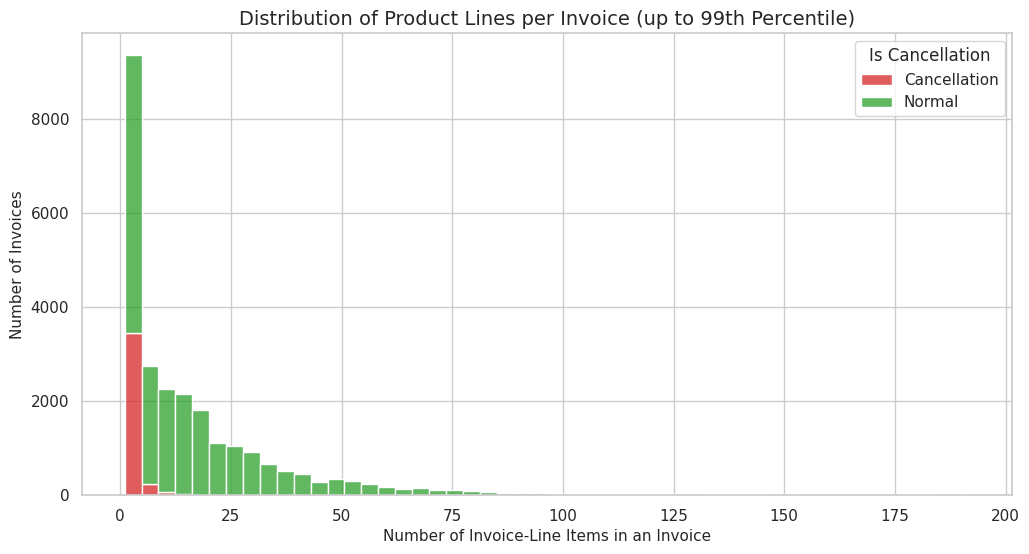

In [17]:
# Distribution of number of invoice-line items per invoice
invoice_items_99 = invoice_line_counts["ItemsPerInvoice"].quantile(0.99)

plt.figure(figsize=(12, 6))
sns.histplot(
    data=invoice_line_counts[
        invoice_line_counts["ItemsPerInvoice"] <= invoice_items_99
    ],
    x="ItemsPerInvoice",
    hue="IsCancellation",
    bins=50,
    multiple="stack",
    palette={False: "#2ca02c", True: "#d62728"}
)

plt.title("Distribution of Product Lines per Invoice (up to 99th Percentile)")
plt.xlabel("Number of Invoice-Line Items in an Invoice")
plt.ylabel("Number of Invoices")
plt.legend(title="Is Cancellation", labels=["Cancellation", "Normal"])
plt.show()

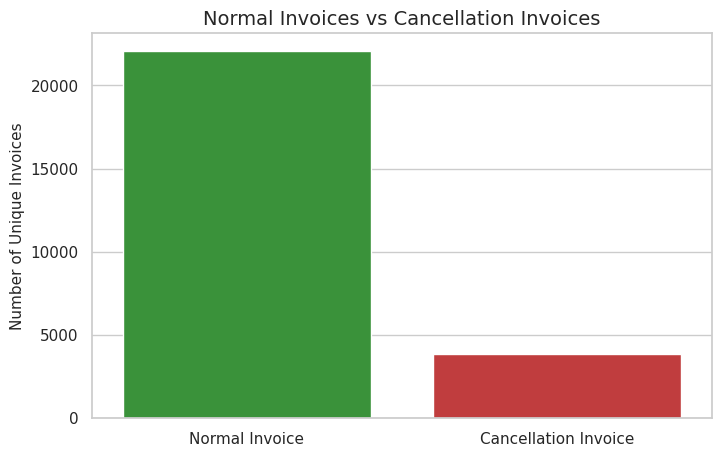

In [18]:
# Normal vs cancellation invoice distribution
invoice_type_summary = (
    invoice_line_counts["IsCancellation"]
    .map({False: "Normal Invoice", True: "Cancellation Invoice"})
    .value_counts()
    .reset_index()
)

invoice_type_summary.columns = ["Invoice Type", "Number of Invoices"]

plt.figure(figsize=(8, 5))
sns.barplot(
    data=invoice_type_summary,
    x="Invoice Type",
    y="Number of Invoices",
    palette=["#2ca02c", "#d62728"]
)

plt.title("Normal Invoices vs Cancellation Invoices")
plt.xlabel("")
plt.ylabel("Number of Unique Invoices")
plt.show()

 StockCode Distribution

In [19]:
stockcode_frequency = (
    df_raw["StockCode"]
    .astype(str)
    .str.strip()
    .value_counts()
    .reset_index()
)

stockcode_frequency.columns = ["StockCode", "InvoiceLineCount"]

display(stockcode_frequency.head(20))

,StockCode,InvoiceLineCount
0,85123A,2313
1,22423,2203
2,85099B,2159
3,47566,1727
4,20725,1639
5,84879,1502
6,22720,1477
7,22197,1476
8,21212,1385
9,20727,1350


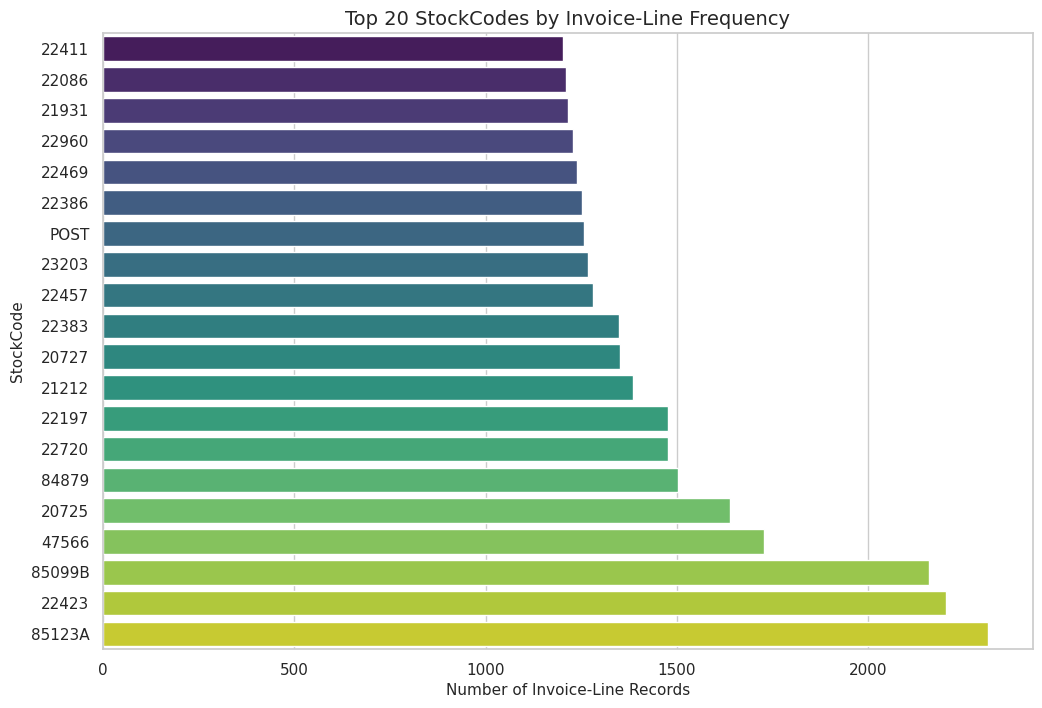

In [20]:
# Top 20 StockCodes by number of invoice-line appearances
top_stockcodes = stockcode_frequency.head(20)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_stockcodes.sort_values("InvoiceLineCount"),
    x="InvoiceLineCount",
    y="StockCode",
    palette="viridis"
)

plt.title("Top 20 StockCodes by Invoice-Line Frequency")
plt.xlabel("Number of Invoice-Line Records")
plt.ylabel("StockCode")
plt.show()

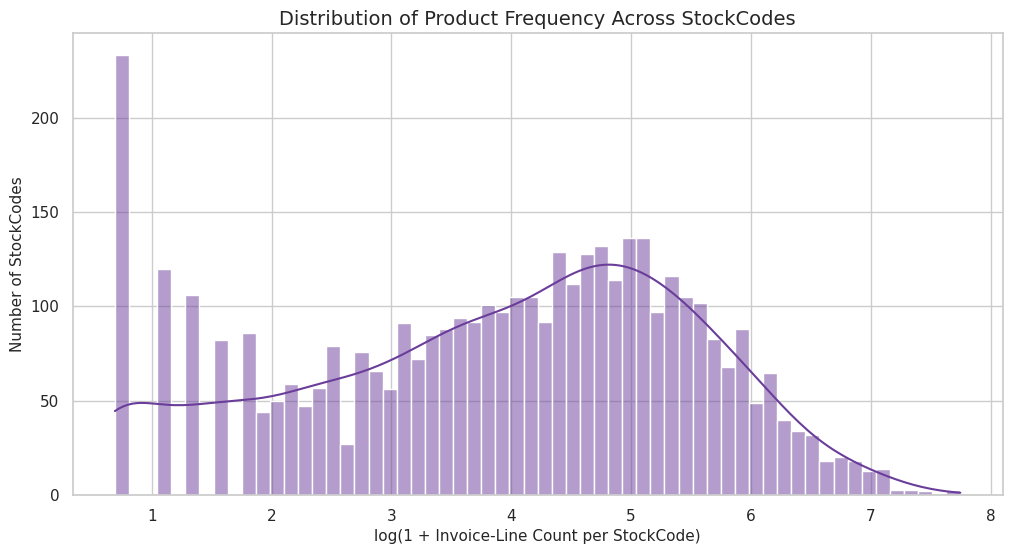

In [21]:
# Product frequency long-tail distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    np.log1p(stockcode_frequency["InvoiceLineCount"]),
    bins=60,
    kde=True,
    color="#6a3d9a"
)

plt.title("Distribution of Product Frequency Across StockCodes")
plt.xlabel("log(1 + Invoice-Line Count per StockCode)")
plt.ylabel("Number of StockCodes")
plt.show()

InvoiceDate Distribution

In [22]:
date_eda = df_raw.copy()
date_eda["InvoiceDate"] = pd.to_datetime(date_eda["InvoiceDate"], errors="coerce")

date_eda["InvoiceMonth"] = date_eda["InvoiceDate"].dt.to_period("M").astype(str)
date_eda["DayOfWeek"] = date_eda["InvoiceDate"].dt.day_name()
date_eda["Hour"] = date_eda["InvoiceDate"].dt.hour

monthly_raw_counts = (
    date_eda
    .groupby("InvoiceMonth", as_index=False)
    .size()
    .rename(columns={"size": "InvoiceLineCount"})
)

display(monthly_raw_counts)

,InvoiceMonth,InvoiceLineCount
0,2010-12,42481
1,2011-01,35147
2,2011-02,27707
3,2011-03,36748
4,2011-04,29916
5,2011-05,37030
6,2011-06,36874
7,2011-07,39518
8,2011-08,35284
9,2011-09,50226


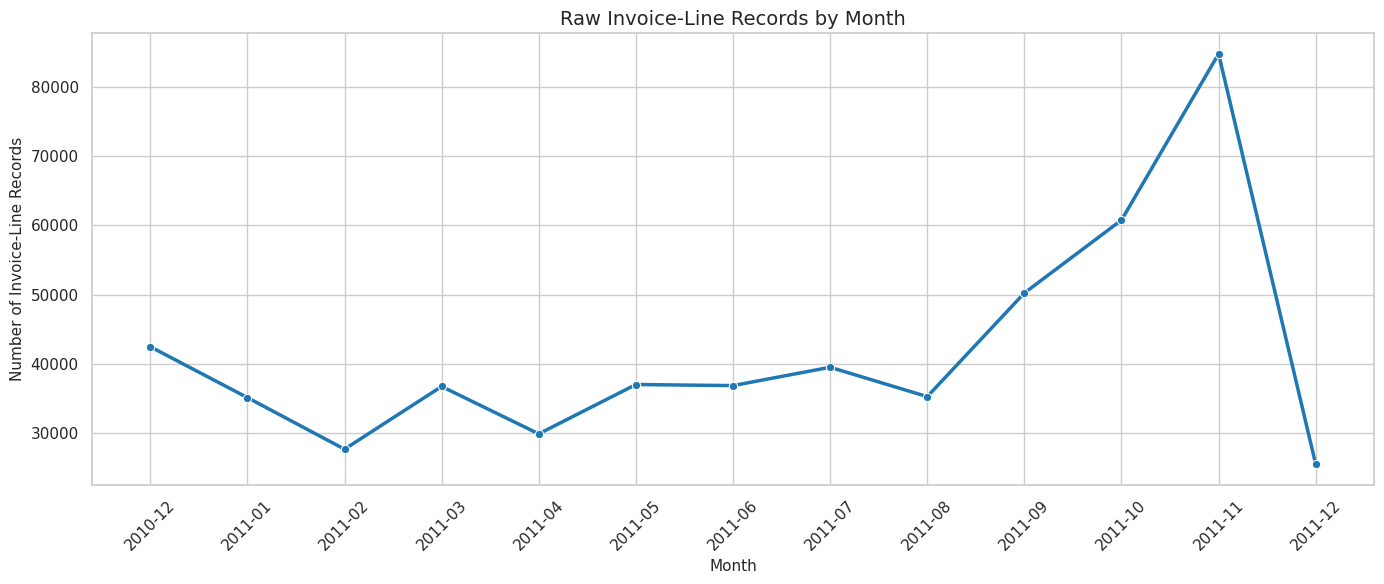

In [23]:
# Monthly raw invoice-line distribution
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_raw_counts,
    x="InvoiceMonth",
    y="InvoiceLineCount",
    marker="o",
    linewidth=2.5,
    color="#1f77b4"
)

plt.title("Raw Invoice-Line Records by Month")
plt.xlabel("Month")
plt.ylabel("Number of Invoice-Line Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

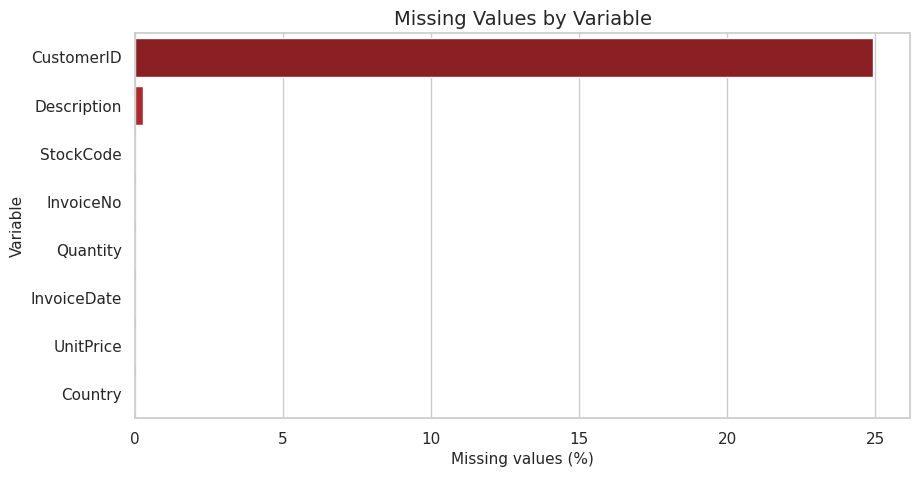

In [24]:
# Visualize missingness by variable
missing_plot = missing_summary.reset_index().rename(columns={"index": "Column"})

plt.figure(figsize=(10, 5))
sns.barplot(
    data=missing_plot,
    x="Missing Percentage (%)",
    y="Column",
    palette="Reds_r"
)
plt.title("Missing Values by Variable")
plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.show()

In [25]:
# Examine rows with missing CustomerID
missing_customer_rows = df_raw[df_raw["CustomerID"].isna()].copy()

print("Rows with missing CustomerID:", len(missing_customer_rows))
print("Percentage of all raw rows:",
      round(len(missing_customer_rows) / len(df_raw) * 100, 2), "%")

display(missing_customer_rows.head(10))

Rows with missing CustomerID: 135080
Percentage of all raw rows: 24.93 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


In [26]:
# Revenue proxy for rows that have enough information to calculate it
df_missing_revenue = df_raw.copy()
df_missing_revenue["LineRevenue"] = (
    df_missing_revenue["Quantity"] * df_missing_revenue["UnitPrice"]
)

total_observed_revenue = df_missing_revenue.loc[
    df_missing_revenue["LineRevenue"] > 0, "LineRevenue"
].sum()

missing_id_positive_revenue = df_missing_revenue.loc[
    (df_missing_revenue["CustomerID"].isna()) &
    (df_missing_revenue["LineRevenue"] > 0),
    "LineRevenue"
].sum()

print(f"Total positive observed revenue: £{total_observed_revenue:,.2f}")
print(f"Positive revenue linked to missing CustomerID: £{missing_id_positive_revenue:,.2f}")
print(
    "Revenue share affected by missing CustomerID:",
    f"{(missing_id_positive_revenue / total_observed_revenue * 100):.2f}%"
)

Total positive observed revenue: £10,666,684.54
Positive revenue linked to missing CustomerID: £1,755,276.64
Revenue share affected by missing CustomerID: 16.46%


CustomerID is essential for customer-level segmentation because it links multiple transactions to the same customer. Transactions with a missing CustomerID cannot be assigned to a customer segment and cannot be used to calculate customer level Recency, Frequency, Monetary value, return rate, or item diversity.

Therefore, the preprocessing stage should quantify the row and revenue impact of missing CustomerIDs and remove those records from the customer-segmentation dataset. This removal should be documented as an analytical necessity, rather than treating CustomerID as a value that can be imputed.


8.Duplicate audit

In [27]:
exact_duplicate_count = df_raw.duplicated().sum()
exact_duplicate_percentage = exact_duplicate_count / len(df_raw) * 100

print("Exact duplicate rows:", exact_duplicate_count)
print(f"Exact duplicate percentage: {exact_duplicate_percentage:.4f}%")

if exact_duplicate_count > 0:
    print("\nExample duplicate rows:")
    display(df_raw[df_raw.duplicated(keep=False)].sort_values(df_raw.columns.tolist()).head(20))

Exact duplicate rows: 5268
Exact duplicate percentage: 0.9721%

Example duplicate rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [28]:
# Potential duplicate invoice-line records
invoice_line_columns = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

potential_duplicate_count = df_raw.duplicated(subset=invoice_line_columns).sum()

print("Potential duplicate invoice-line records:", potential_duplicate_count)

Potential duplicate invoice-line records: 5268


Exact duplicate rows may represent accidental duplicate data records, but they should not be removed automatically without checking their business meaning. In retail transaction data, repeated products in the same invoice can be valid when the same product appears as separate invoice lines.

9. Invoice and Cancellation Audit

In [29]:
# Preserve InvoiceNo as string to safely detect cancellation invoices.
invoice_as_string = df_raw["InvoiceNo"].astype(str).str.strip()

df_invoice_audit = df_raw.copy()
df_invoice_audit["InvoiceNo_str"] = invoice_as_string
df_invoice_audit["IsCancellation"] = df_invoice_audit["InvoiceNo_str"].str.startswith("C", na=False)

cancellation_summary = pd.DataFrame({
    "Metric": [
        "Total invoice-line rows",
        "Cancellation invoice-line rows",
        "Non-cancellation invoice-line rows",
        "Cancellation row percentage",
        "Unique cancellation invoices",
        "Unique non-cancellation invoices"
    ],
    "Value": [
        len(df_invoice_audit),
        df_invoice_audit["IsCancellation"].sum(),
        (~df_invoice_audit["IsCancellation"]).sum(),
        round(df_invoice_audit["IsCancellation"].mean() * 100, 2),
        df_invoice_audit.loc[df_invoice_audit["IsCancellation"], "InvoiceNo"].nunique(),
        df_invoice_audit.loc[~df_invoice_audit["IsCancellation"], "InvoiceNo"].nunique()
    ]
})

display(cancellation_summary)

,Metric,Value
0,Total invoice-line rows,541909.00
1,Cancellation invoice-line rows,9288.00
2,Non-cancellation invoice-line rows,532621.00
3,Cancellation row percentage,1.71
4,Unique cancellation invoices,3836.00
5,Unique non-cancellation invoices,22064.00


In [30]:
# Compare quantity and line revenue patterns for cancellation vs non-cancellation records
df_invoice_audit["LineRevenue"] = (
    df_invoice_audit["Quantity"] * df_invoice_audit["UnitPrice"]
)

cancellation_comparison = df_invoice_audit.groupby("IsCancellation").agg(
    Rows=("InvoiceNo", "size"),
    UniqueInvoices=("InvoiceNo", "nunique"),
    MeanQuantity=("Quantity", "mean"),
    MedianQuantity=("Quantity", "median"),
    NegativeQuantityRate=("Quantity", lambda x: (x < 0).mean() * 100),
    MeanLineRevenue=("LineRevenue", "mean"),
    TotalLineRevenue=("LineRevenue", "sum")
).round(2)

cancellation_comparison.index = cancellation_comparison.index.map({
    False: "Normal / Non-cancellation",
    True: "Cancellation"
})

display(cancellation_comparison)

,Rows,UniqueInvoices,MeanQuantity,MedianQuantity,NegativeQuantityRate,MeanLineRevenue,TotalLineRevenue
IsCancellation,,,,,,,
Normal / Non-cancellation,532621,22064,10.24,3.0,0.25,19.99,10644560.42
Cancellation,9288,3836,-29.89,-2.0,100.00,-96.56,-896812.49


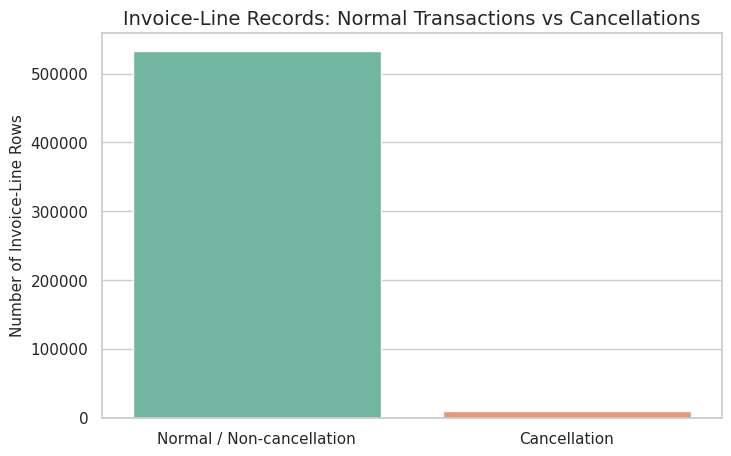

In [31]:
# Visualize cancellation vs non-cancellation row count
plot_data = (
    df_invoice_audit["IsCancellation"]
    .map({False: "Normal / Non-cancellation", True: "Cancellation"})
    .value_counts()
    .reset_index()
)

plot_data.columns = ["Transaction Type", "Row Count"]

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_data, x="Transaction Type", y="Row Count", palette="Set2")
plt.title("Invoice-Line Records: Normal Transactions vs Cancellations")
plt.xlabel("")
plt.ylabel("Number of Invoice-Line Rows")
plt.show()

Invoices starting with `C` indicate cancelled transactions. These records commonly have negative quantities and negative line revenue, which represent returned or reversed purchases rather than completed customer demand.

For the primary customer-segmentation and market-basket objectives, the preprocessing pipeline should create a completed-purchase dataset by excluding cancellation invoices and retaining only valid positive purchases. However, cancellation behaviour should not simply be ignored: it will first be analysed and can later support a return-related feature such as return rate.

10. Invalid Quantity and Price Audit

In [32]:
quantity_price_audit = pd.DataFrame({
    "Condition": [
        "Quantity <= 0",
        "Quantity = 0",
        "Quantity < 0",
        "UnitPrice <= 0",
        "UnitPrice = 0",
        "UnitPrice < 0",
        "Positive Quantity and Positive UnitPrice"
    ],
    "Row Count": [
        (df_raw["Quantity"] <= 0).sum(),
        (df_raw["Quantity"] == 0).sum(),
        (df_raw["Quantity"] < 0).sum(),
        (df_raw["UnitPrice"] <= 0).sum(),
        (df_raw["UnitPrice"] == 0).sum(),
        (df_raw["UnitPrice"] < 0).sum(),
        ((df_raw["Quantity"] > 0) & (df_raw["UnitPrice"] > 0)).sum()
    ]
})

quantity_price_audit["Percentage of Rows (%)"] = (
    quantity_price_audit["Row Count"] / len(df_raw) * 100
).round(2)

display(quantity_price_audit)

,Condition,Row Count,Percentage of Rows (%)
0,Quantity <= 0,10624,1.96
1,Quantity = 0,0,0.00
2,Quantity < 0,10624,1.96
3,UnitPrice <= 0,2517,0.46
4,UnitPrice = 0,2515,0.46
5,UnitPrice < 0,2,0.00
6,Positive Quantity and Positive UnitPrice,530104,97.82


In [33]:
# Summary of quantity and price
numeric_raw_summary = df_raw[["Quantity", "UnitPrice"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(numeric_raw_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


In [34]:
print("Highest Quantity rows:")
display(
    df_raw.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "CustomerID", "Country"]
    ]
)

print("Highest UnitPrice rows:")
display(
    df_raw.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "CustomerID", "Country"]
    ]
)

Highest Quantity rows:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,United Kingdom
74614,542504,37413,NaN,5568,0.00,NaN,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0,United Kingdom
220843,556231,85123A,?,4000,0.00,NaN,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom


Highest UnitPrice rows:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
222681,C556445,M,Manual,-1,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,NaN,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,NaN,United Kingdom


Quantity and UnitPrice values are required to calculate transaction revenue


LineRevenue = Quantity x UnitPrice


Rows with non-positive quantity or non-positive unit price do not represent normal completed sales. The preprocessing stage should define a completed-purchase subset by retaining rows where Quantity > 0 and UnitPrice > 0, after separately identifying cancellation-related rows.

Extreme but valid positive values should be investigated instead of automatically removed. In a wholesale retail setting, large orders may represent genuine high-value customers rather than data-entry errors.

11. Create EDA Only Derived Variables

In [35]:
df_eda = df_raw.copy()

df_eda["InvoiceNo_str"] = df_eda["InvoiceNo"].astype(str).str.strip()
df_eda["IsCancellation"] = df_eda["InvoiceNo_str"].str.startswith("C", na=False)

df_eda["LineRevenue"] = df_eda["Quantity"] * df_eda["UnitPrice"]


df_eda["InvoiceDate"] = pd.to_datetime(df_eda["InvoiceDate"], errors="coerce")

df_eda["InvoiceYear"] = df_eda["InvoiceDate"].dt.year
df_eda["InvoiceMonth"] = df_eda["InvoiceDate"].dt.to_period("M").astype(str)
df_eda["DayOfWeek"] = df_eda["InvoiceDate"].dt.day_name()
df_eda["Hour"] = df_eda["InvoiceDate"].dt.hour


df_completed_eda = df_eda[
    (~df_eda["IsCancellation"]) &
    (df_eda["Quantity"] > 0) &
    (df_eda["UnitPrice"] > 0)
].copy()

print("Raw EDA dataset shape:", df_eda.shape)
print("Completed-purchase EDA subset shape:", df_completed_eda.shape)

Raw EDA dataset shape: (541909, 15)
Completed-purchase EDA subset shape: (530104, 15)


12. Revenue and Transaction Overview

In [36]:
overview_metrics = pd.DataFrame({
    "Metric": [
        "Raw invoice-line rows",
        "Completed-purchase invoice-line rows",
        "Unique invoices in completed purchases",
        "Unique customers in completed purchases",
        "Unique products in completed purchases",
        "Countries in completed purchases",
        "Total completed-purchase revenue",
        "Date range start",
        "Date range end"
    ],
    "Value": [
        len(df_raw),
        len(df_completed_eda),
        df_completed_eda["InvoiceNo"].nunique(),
        df_completed_eda["CustomerID"].nunique(),
        df_completed_eda["StockCode"].nunique(),
        df_completed_eda["Country"].nunique(),
        f"£{df_completed_eda['LineRevenue'].sum():,.2f}",
        df_completed_eda["InvoiceDate"].min(),
        df_completed_eda["InvoiceDate"].max()
    ]
})

display(overview_metrics)

,Metric,Value
0,Raw invoice-line rows,541909
1,Completed-purchase invoice-line rows,530104
2,Unique invoices in completed purchases,19960
3,Unique customers in completed purchases,4338
4,Unique products in completed purchases,3922
5,Countries in completed purchases,38
6,Total completed-purchase revenue,"£10,666,684.54"
7,Date range start,2010-12-01 08:26:00
8,Date range end,2011-12-09 12:50:00


In [37]:
# Revenue contribution of rows with missing CustomerID
customer_id_revenue_audit = (
    df_completed_eda.assign(
        CustomerIDStatus=np.where(
            df_completed_eda["CustomerID"].isna(),
            "Missing CustomerID",
            "Known CustomerID"
        )
    )
    .groupby("CustomerIDStatus")
    .agg(
        Rows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        Revenue=("LineRevenue", "sum")
    )
)

customer_id_revenue_audit["Revenue Share (%)"] = (
    customer_id_revenue_audit["Revenue"] /
    customer_id_revenue_audit["Revenue"].sum() * 100
).round(2)

display(customer_id_revenue_audit)

,Rows,UniqueInvoices,Revenue,Revenue Share (%)
CustomerIDStatus,,,,
Known CustomerID,397884,18532,8911407.904,83.54
Missing CustomerID,132220,1428,1755276.640,16.46


13. Time-Based EDA

In [38]:
monthly_sales = (
    df_completed_eda
    .groupby("InvoiceMonth", as_index=False)
    .agg(
        Revenue=("LineRevenue", "sum"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        UniqueCustomers=("CustomerID", "nunique"),
        LineItems=("InvoiceNo", "size")
    )
)

display(monthly_sales)

,InvoiceMonth,Revenue,UniqueInvoices,UniqueCustomers,LineItems
0,2010-12,823746.140,1559,885,41480
1,2011-01,691364.560,1086,741,34306
2,2011-02,523631.890,1100,758,27105
3,2011-03,717639.360,1454,974,35803
4,2011-04,537808.621,1246,856,29096
5,2011-05,770536.020,1681,1056,36164
6,2011-06,761739.900,1533,991,35977
7,2011-07,719221.191,1475,949,38645
8,2011-08,759138.380,1361,935,34483
9,2011-09,1058590.172,1837,1266,49261


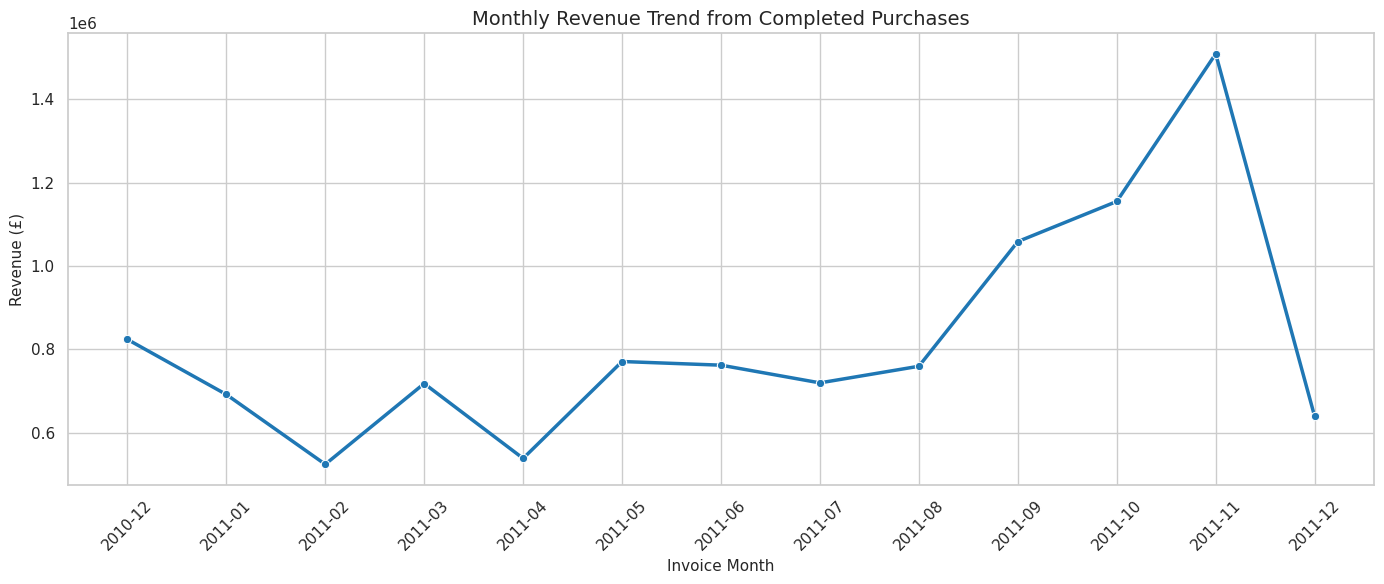

In [39]:
# Monthly revenue
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_sales,
    x="InvoiceMonth",
    y="Revenue",
    marker="o",
    linewidth=2.5,
    color="#1f77b4"
)
plt.title("Monthly Revenue Trend from Completed Purchases")
plt.xlabel("Invoice Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

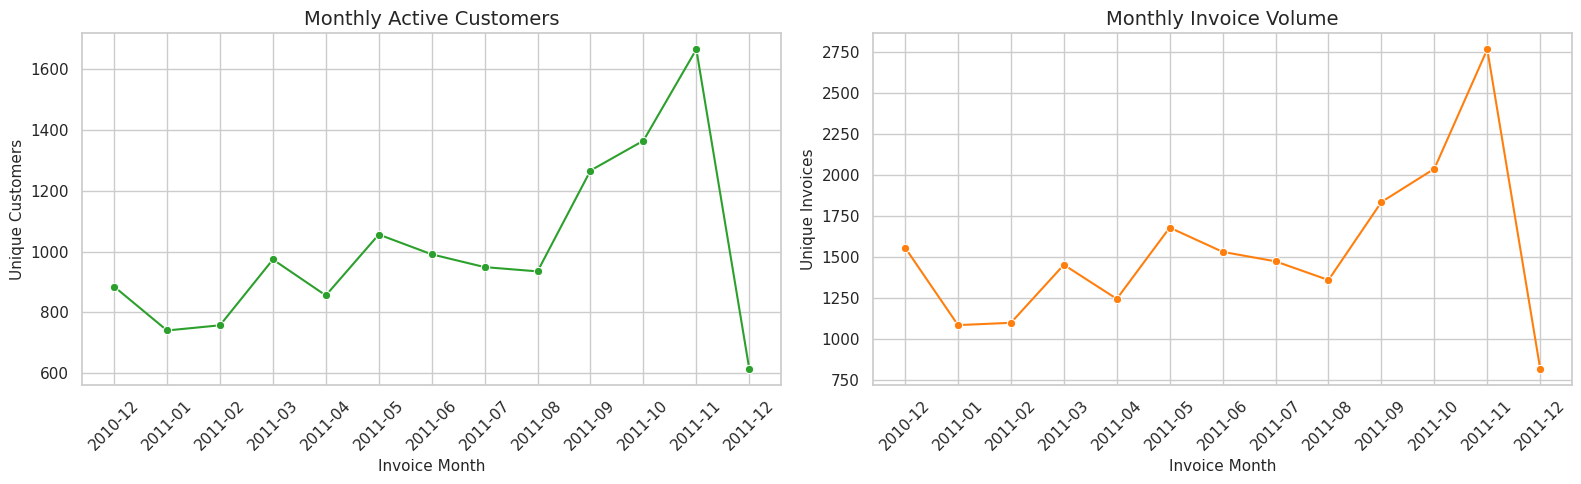

In [40]:
# Monthly unique customers and invoices
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(
    data=monthly_sales,
    x="InvoiceMonth",
    y="UniqueCustomers",
    marker="o",
    ax=axes[0],
    color="#2ca02c"
)
axes[0].set_title("Monthly Active Customers")
axes[0].set_xlabel("Invoice Month")
axes[0].set_ylabel("Unique Customers")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=monthly_sales,
    x="InvoiceMonth",
    y="UniqueInvoices",
    marker="o",
    ax=axes[1],
    color="#ff7f0e"
)
axes[1].set_title("Monthly Invoice Volume")
axes[1].set_xlabel("Invoice Month")
axes[1].set_ylabel("Unique Invoices")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

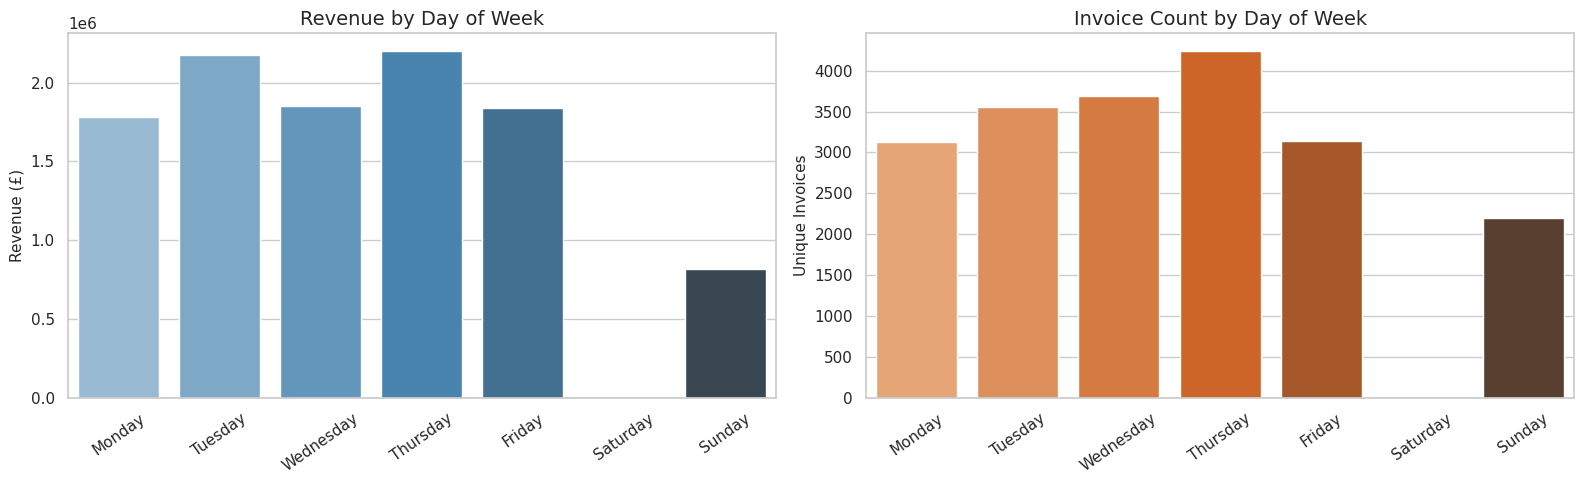

In [41]:
# Sales by day of week
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_sales = (
    df_completed_eda
    .groupby("DayOfWeek", as_index=False)
    .agg(
        Revenue=("LineRevenue", "sum"),
        UniqueInvoices=("InvoiceNo", "nunique")
    )
)

daily_sales["DayOfWeek"] = pd.Categorical(
    daily_sales["DayOfWeek"],
    categories=day_order,
    ordered=True
)

daily_sales = daily_sales.sort_values("DayOfWeek")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=daily_sales,
    x="DayOfWeek",
    y="Revenue",
    ax=axes[0],
    palette="Blues_d"
)
axes[0].set_title("Revenue by Day of Week")
axes[0].set_xlabel("")
axes[0].set_ylabel("Revenue (£)")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=daily_sales,
    x="DayOfWeek",
    y="UniqueInvoices",
    ax=axes[1],
    palette="Oranges_d"
)
axes[1].set_title("Invoice Count by Day of Week")
axes[1].set_xlabel("")
axes[1].set_ylabel("Unique Invoices")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

14. Country level EDA

In [42]:


country_summary = (
    df_completed_eda
    .groupby("Country", as_index=False)
    .agg(
        Revenue=("LineRevenue", "sum"),
        UniqueCustomers=("CustomerID", "nunique"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        LineItems=("InvoiceNo", "size")
    )
    .sort_values("Revenue", ascending=False)
)

country_summary["Revenue Share (%)"] = (
    country_summary["Revenue"] / country_summary["Revenue"].sum() * 100
).round(2)

display(country_summary.head(15))

,Country,Revenue,UniqueCustomers,UniqueInvoices,LineItems,Revenue Share (%)
36,United Kingdom,9025222.084,3920,18019,485123,84.61
24,Netherlands,285446.340,9,94,2359,2.68
10,EIRE,283453.960,3,288,7890,2.66
14,Germany,228867.140,94,457,9040,2.15
13,France,209715.110,87,392,8407,1.97
0,Australia,138521.310,9,57,1182,1.30
31,Spain,61577.110,30,90,2484,0.58
33,Switzerland,57089.900,21,54,1966,0.54
3,Belgium,41196.340,25,98,2031,0.39
32,Sweden,38378.330,8,36,451,0.36


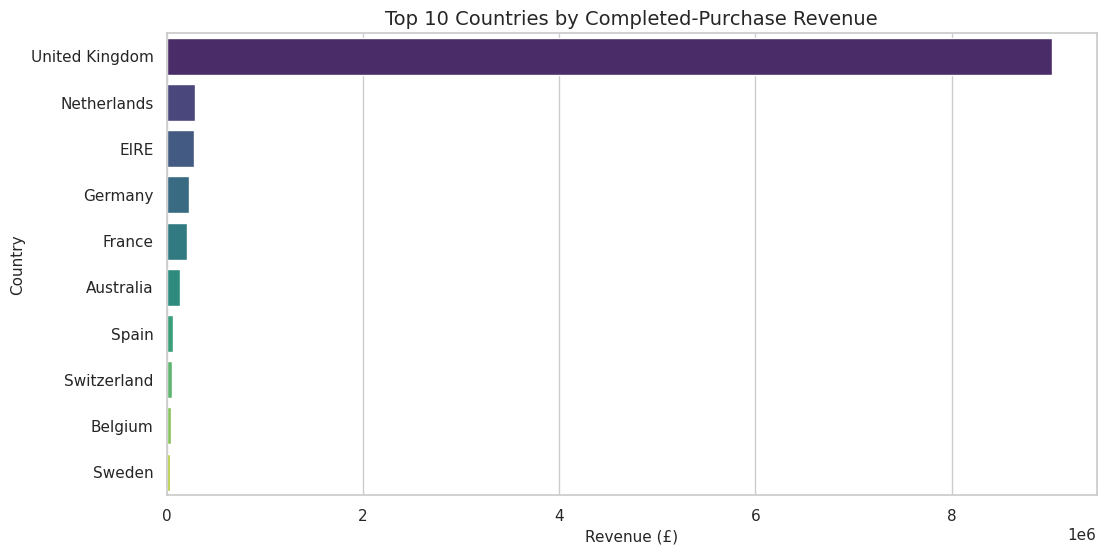

In [43]:
# Top 10 countries by revenue
top_n_countries = 10
top_countries = country_summary.head(top_n_countries)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_countries,
    y="Country",
    x="Revenue",
    palette="viridis"
)
plt.title(f"Top {top_n_countries} Countries by Completed-Purchase Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.show()

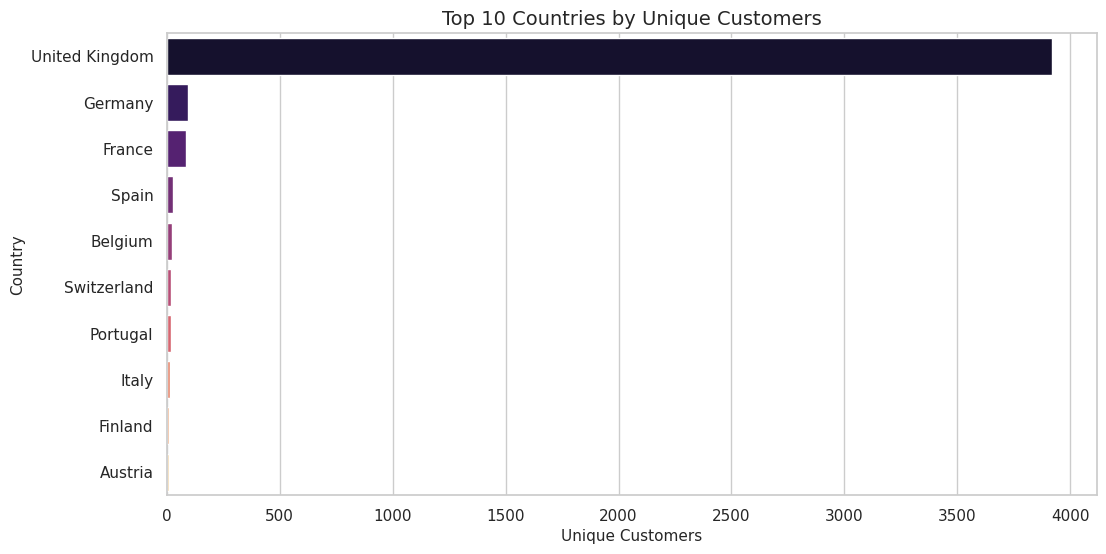

In [44]:
# Top 10 countries by unique customers
top_customer_countries = country_summary.nlargest(10, "UniqueCustomers")

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_customer_countries,
    y="Country",
    x="UniqueCustomers",
    palette="magma"
)
plt.title("Top 10 Countries by Unique Customers")
plt.xlabel("Unique Customers")
plt.ylabel("Country")
plt.show()

### Country-Level Interpretation

Country is useful for describing where sales and customers are concentrated. However, country should not automatically be included as a numerical feature in distance-based clustering because one-hot encoding can create high-dimensional sparse features and may cause geographical differences to dominate behavioural segmentation.

15. Product-Level EDA

In [45]:
product_summary = (
    df_completed_eda
    .groupby(["StockCode", "Description"], dropna=False, as_index=False)
    .agg(
        QuantitySold=("Quantity", "sum"),
        Revenue=("LineRevenue", "sum"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        UniqueCustomers=("CustomerID", "nunique")
    )
)

top_products_revenue = product_summary.nlargest(15, "Revenue")
top_products_quantity = product_summary.nlargest(15, "QuantitySold")

print("Top products by revenue:")
display(top_products_revenue)

print("Top products by quantity sold:")
display(top_products_quantity)

Top products by revenue:


,StockCode,Description,QuantitySold,Revenue,UniqueInvoices,UniqueCustomers
4150,DOT,DOTCOM POSTAGE,706,206248.77,706,1
1262,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988,881
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,1
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189,856
2669,47566,PARTY BUNTING,18295,99504.33,1685,708
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089,635
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247,138
4151,M,Manual,7224,78110.27,289,197
4153,POST,POSTAGE,3150,78101.88,1126,331
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994,450


Top products by quantity sold:


,StockCode,Description,QuantitySold,Revenue,UniqueInvoices,UniqueCustomers
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247,138
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85,535,307
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089,635
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189,856
1051,22197,POPCORN HOLDER,36761,34298.87,803,295
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455,678
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320,635
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994,450
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82,380,213


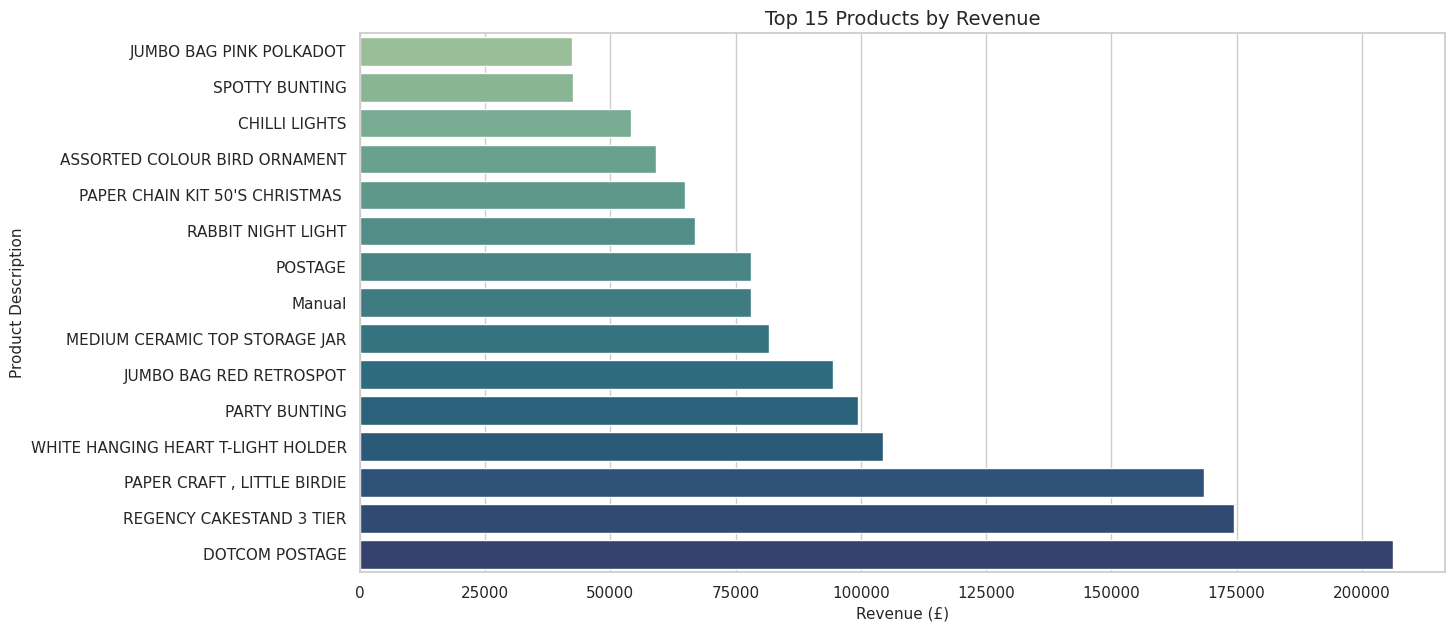

In [46]:
# Top products by revenue
plt.figure(figsize=(14, 7))
sns.barplot(
    data=top_products_revenue.sort_values("Revenue"),
    x="Revenue",
    y="Description",
    palette="crest"
)
plt.title("Top 15 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product Description")
plt.show()

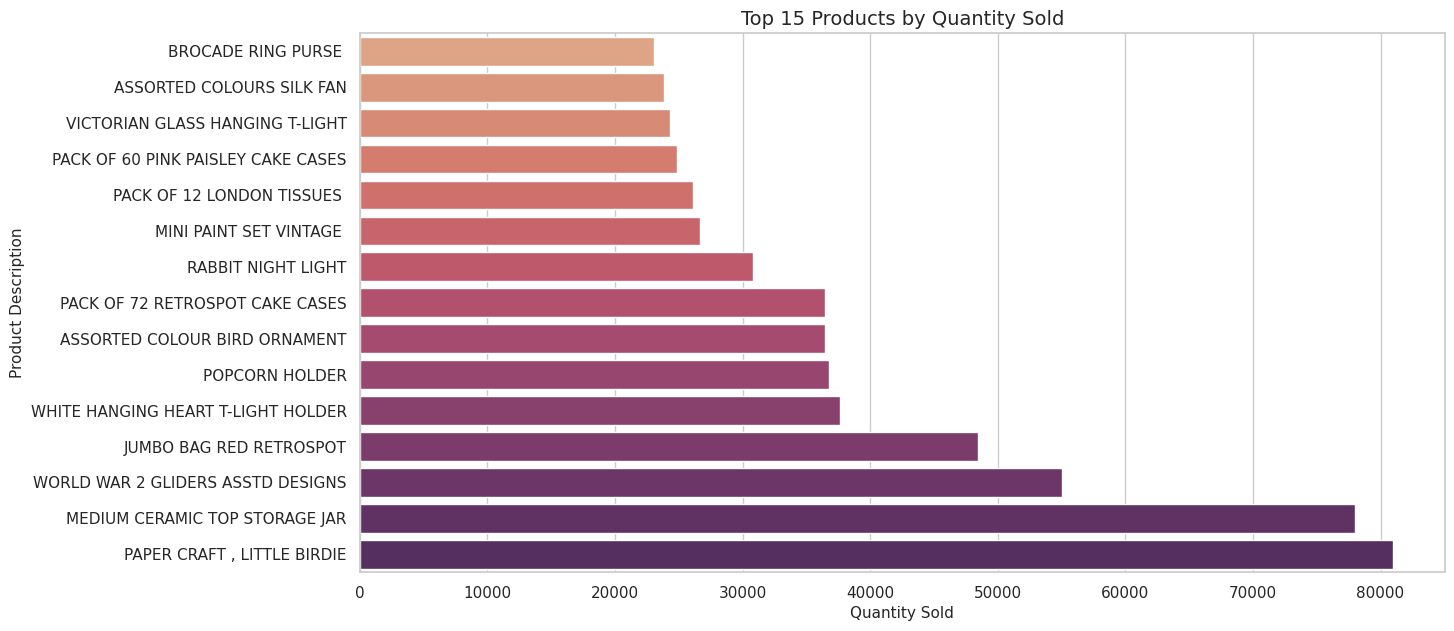

In [47]:
# Top products by quantity sold
plt.figure(figsize=(14, 7))
sns.barplot(
    data=top_products_quantity.sort_values("QuantitySold"),
    x="QuantitySold",
    y="Description",
    palette="flare"
)
plt.title("Top 15 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Description")
plt.show()

In [48]:
# Long-tail product concentration
product_revenue_sorted = product_summary.sort_values("Revenue", ascending=False).reset_index(drop=True)
product_revenue_sorted["Cumulative Revenue Share (%)"] = (
    product_revenue_sorted["Revenue"].cumsum()
    / product_revenue_sorted["Revenue"].sum() * 100
)

top_10_product_share = product_revenue_sorted.head(10)["Revenue"].sum() / product_revenue_sorted["Revenue"].sum() * 100
top_50_product_share = product_revenue_sorted.head(50)["Revenue"].sum() / product_revenue_sorted["Revenue"].sum() * 100
top_100_product_share = product_revenue_sorted.head(100)["Revenue"].sum() / product_revenue_sorted["Revenue"].sum() * 100

print(f"Revenue share from top 10 products: {top_10_product_share:.2f}%")
print(f"Revenue share from top 50 products: {top_50_product_share:.2f}%")
print(f"Revenue share from top 100 products: {top_100_product_share:.2f}%")

Revenue share from top 10 products: 10.80%
Revenue share from top 50 products: 23.46%
Revenue share from top 100 products: 33.79%


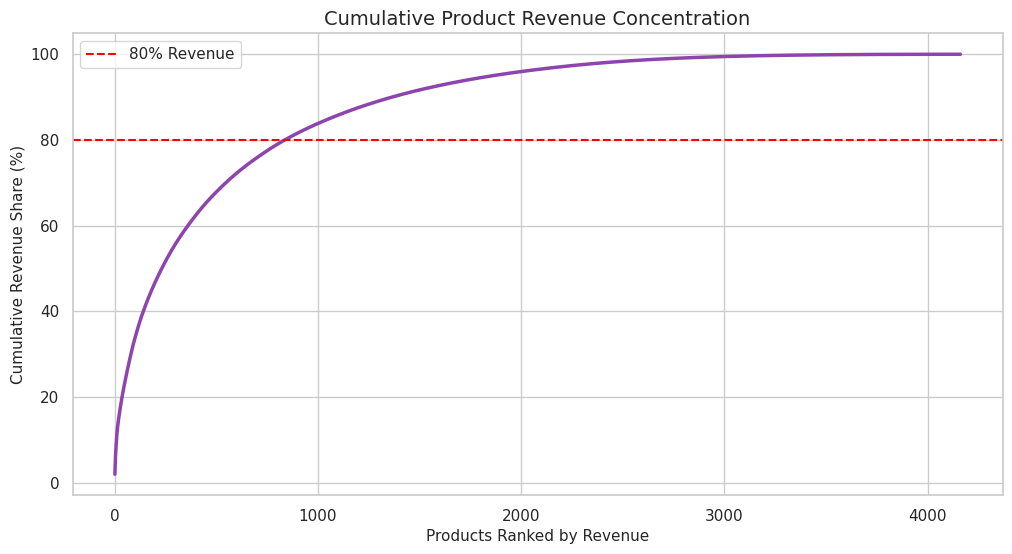

In [49]:
# Product revenue concentration curve
plt.figure(figsize=(12, 6))
plt.plot(
    range(1, len(product_revenue_sorted) + 1),
    product_revenue_sorted["Cumulative Revenue Share (%)"],
    color="#8e44ad",
    linewidth=2.5
)

plt.axhline(80, color="red", linestyle="--", label="80% Revenue")
plt.title("Cumulative Product Revenue Concentration")
plt.xlabel("Products Ranked by Revenue")
plt.ylabel("Cumulative Revenue Share (%)")
plt.legend()
plt.show()

### Product-Level Interpretation

Retail product demand is expected to be highly skewed: a small number of products can contribute a large share of revenue or transactions, while many products occur rarely.

This pattern matters for the association-rule stage. Very rare products may generate unreliable or overly specific rules, so the association-rule member should consider minimum-support thresholds and may need to remove non-product codes or extremely rare items before Apriori analysis.

16. Quantity, Price, and Revenue Distributions

In [50]:
distribution_data = df_completed_eda[
    ["Quantity", "UnitPrice", "LineRevenue"]
].replace([np.inf, -np.inf], np.nan).dropna()

print("Skewness:")
display(distribution_data.skew().to_frame(name="Skewness"))

print("Selected percentiles:")
display(
    distribution_data.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

Skewness:


,Skewness
Quantity,471.727716
UnitPrice,206.087555
LineRevenue,506.706012


Selected percentiles:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,530104.0,10.542037,155.524124,1.000,1.00,1.00,1.00,3.00,10.00,30.00,100.00,80995.00
UnitPrice,530104.0,3.907625,35.915681,0.001,0.29,0.42,1.25,2.08,4.13,9.95,16.98,13541.33
LineRevenue,530104.0,20.121871,270.356743,0.001,0.55,1.25,3.75,9.90,17.70,59.70,183.60,168469.60


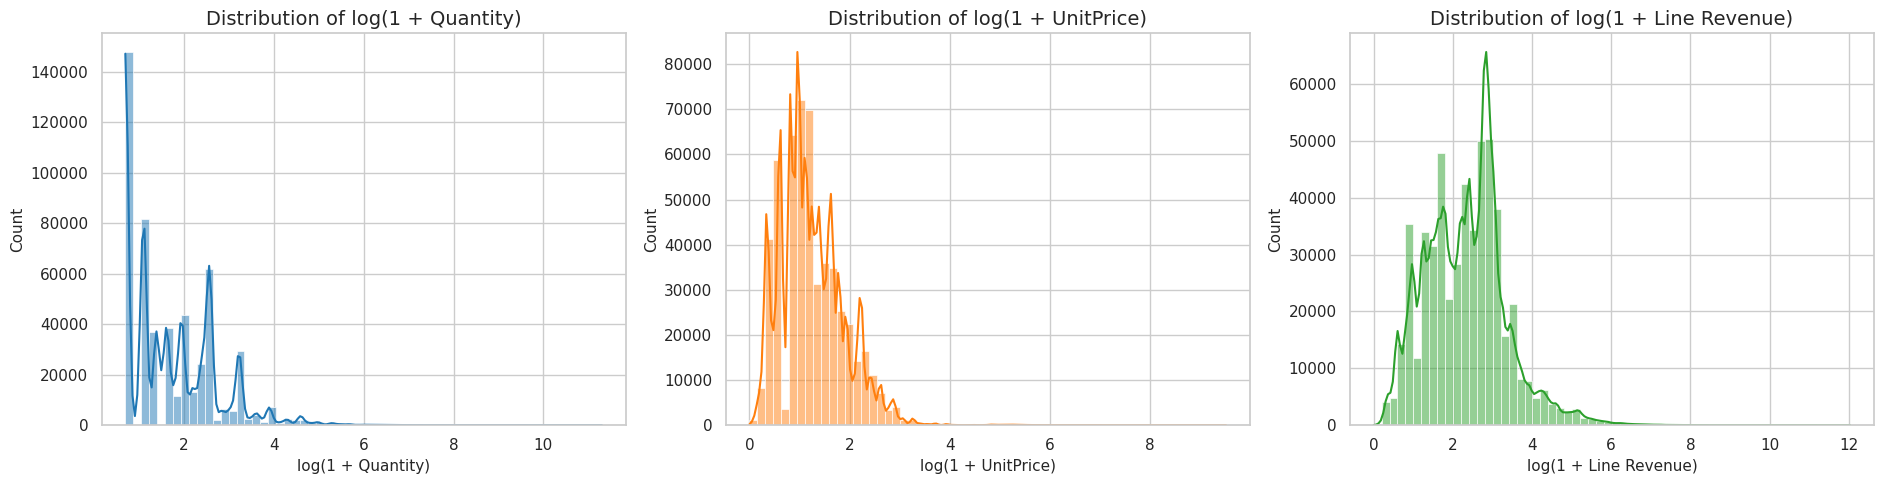

In [51]:
# Histograms using log-scale / log1p views to make heavy-tailed distributions visible
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.histplot(
    np.log1p(df_completed_eda["Quantity"]),
    bins=60,
    kde=True,
    ax=axes[0],
    color="#1f77b4"
)
axes[0].set_title("Distribution of log(1 + Quantity)")
axes[0].set_xlabel("log(1 + Quantity)")

sns.histplot(
    np.log1p(df_completed_eda["UnitPrice"]),
    bins=60,
    kde=True,
    ax=axes[1],
    color="#ff7f0e"
)
axes[1].set_title("Distribution of log(1 + UnitPrice)")
axes[1].set_xlabel("log(1 + UnitPrice)")

sns.histplot(
    np.log1p(df_completed_eda["LineRevenue"]),
    bins=60,
    kde=True,
    ax=axes[2],
    color="#2ca02c"
)
axes[2].set_title("Distribution of log(1 + Line Revenue)")
axes[2].set_xlabel("log(1 + Line Revenue)")

plt.tight_layout()
plt.show()

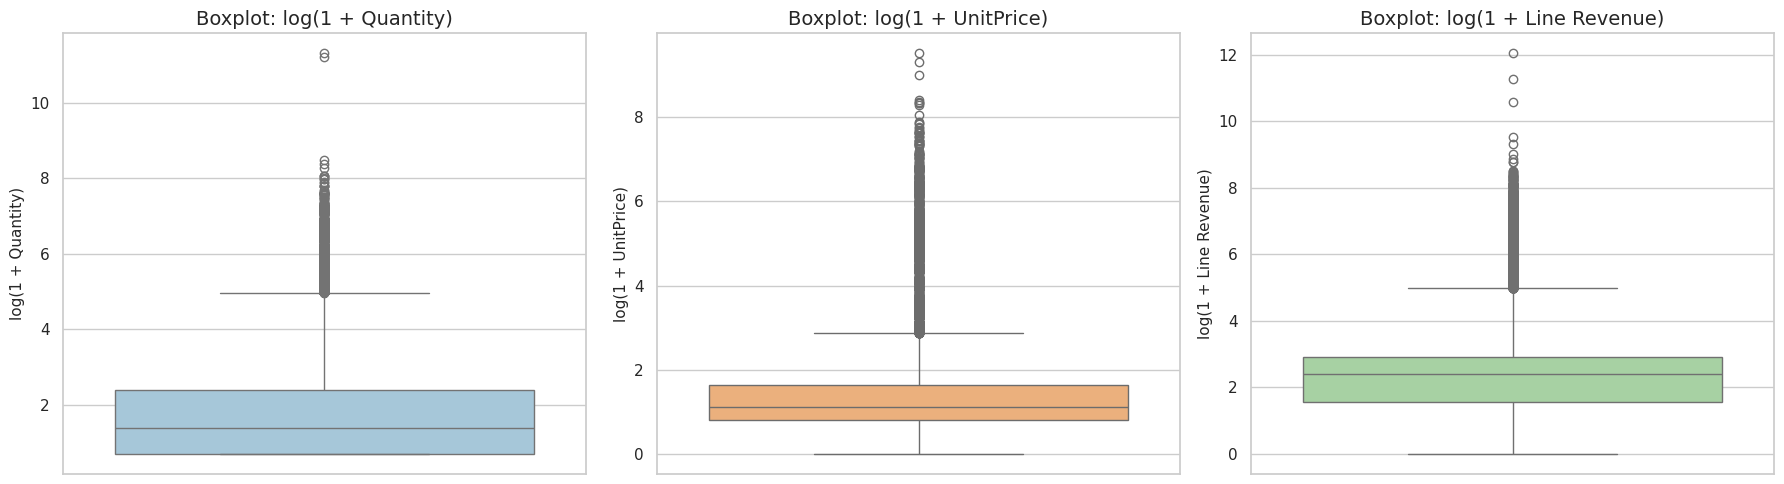

In [52]:
# Boxplots on log-transformed values
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=np.log1p(df_completed_eda["Quantity"]), ax=axes[0], color="#9ecae1")
axes[0].set_title("Boxplot: log(1 + Quantity)")
axes[0].set_ylabel("log(1 + Quantity)")

sns.boxplot(y=np.log1p(df_completed_eda["UnitPrice"]), ax=axes[1], color="#fdae6b")
axes[1].set_title("Boxplot: log(1 + UnitPrice)")
axes[1].set_ylabel("log(1 + UnitPrice)")

sns.boxplot(y=np.log1p(df_completed_eda["LineRevenue"]), ax=axes[2], color="#a1d99b")
axes[2].set_title("Boxplot: log(1 + Line Revenue)")
axes[2].set_ylabel("log(1 + Line Revenue)")

plt.tight_layout()
plt.show()

Quantity, UnitPrice, and LineRevenue are expected to be strongly right-skewed because most retail purchases are small while a minority of transactions are unusually large.

This is important for later customer-level features such as Frequency, Monetary value, average basket value, and return-related measures. The preprocessing member should evaluate log transformations for highly skewed non-negative features and use RobustScaler because it is less influenced by extreme values than standard scaling.

17. Outlier Screening

In [53]:
def iqr_outlier_summary(series):
    series = series.dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (series < lower_bound) | (series > upper_bound)

    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_mask.sum(),
        "Potential Outlier %": round(outlier_mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame({
    "Quantity": iqr_outlier_summary(df_completed_eda["Quantity"]),
    "UnitPrice": iqr_outlier_summary(df_completed_eda["UnitPrice"]),
    "LineRevenue": iqr_outlier_summary(df_completed_eda["LineRevenue"])
}).T

display(outlier_summary)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Potential Outlier %
Quantity,1.00,10.00,9.00,-12.500,23.500,56363.0,10.63
UnitPrice,1.25,4.13,2.88,-3.070,8.450,37999.0,7.17
LineRevenue,3.75,17.70,13.95,-17.175,38.625,42651.0,8.05


In [54]:
# Inspect highest value completed purchase lines
high_value_lines = df_completed_eda.nlargest(
    20, "LineRevenue"
)[
    [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "LineRevenue",
        "CustomerID", "Country", "InvoiceDate"
    ]
]

display(high_value_lines)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineRevenue,CustomerID,Country,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom,2011-01-18 10:01:00
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,United Kingdom,2011-06-10 15:28:00
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,NaN,United Kingdom,2010-12-07 15:08:00
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,NaN,United Kingdom,2011-08-12 14:50:00
173382,551697,POST,POSTAGE,1,8142.75,8142.75,16029.0,United Kingdom,2011-05-03 13:46:00
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0,United Kingdom,2011-09-20 11:05:00
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom,2011-01-11 12:55:00
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom,2011-04-18 13:20:00
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,14646.0,Netherlands,2011-10-27 12:11:00


In [55]:
# Inspect highest-value completed purchase lines
high_value_lines = df_completed_eda.nlargest(
    20, "LineRevenue"
)[
    [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "LineRevenue",
        "CustomerID", "Country", "InvoiceDate"
    ]
]

display(high_value_lines)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineRevenue,CustomerID,Country,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom,2011-01-18 10:01:00
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,United Kingdom,2011-06-10 15:28:00
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,NaN,United Kingdom,2010-12-07 15:08:00
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,NaN,United Kingdom,2011-08-12 14:50:00
173382,551697,POST,POSTAGE,1,8142.75,8142.75,16029.0,United Kingdom,2011-05-03 13:46:00
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0,United Kingdom,2011-09-20 11:05:00
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom,2011-01-11 12:55:00
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom,2011-04-18 13:20:00
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,14646.0,Netherlands,2011-10-27 12:11:00


IQR-based outlier flags are screening indicators, not proof that a transaction is invalid. A high-value customer or large order may be commercially important, especially in a wholesale retailer.

Therefore:
- Remove only records confirmed to be errors or invalid transactions.
- Retain valid high-value purchases because they contain meaningful customer value information.
- Reduce their modelling influence later using log transformation and RobustScaler.
- Consider reporting highly unusual customers separately during final segmentation interpretation.

18. Customer Purchase Behaviour EDA

In [56]:
customer_eda = (
    df_completed_eda
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID", as_index=False)
    .agg(
        FirstPurchaseDate=("InvoiceDate", "min"),
        LastPurchaseDate=("InvoiceDate", "max"),
        InvoiceFrequency=("InvoiceNo", "nunique"),
        TotalRevenue=("LineRevenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        UniqueDescriptions=("Description", "nunique"),
        CountriesPurchasedFrom=("Country", "nunique")
    )
)

customer_eda["AnalysisDate"] = df_completed_eda["InvoiceDate"].max() + pd.Timedelta(days=1)
customer_eda["RecencyDays"] = (
    customer_eda["AnalysisDate"] - customer_eda["LastPurchaseDate"]
).dt.days

customer_eda["AvgRevenuePerInvoice"] = (
    customer_eda["TotalRevenue"] / customer_eda["InvoiceFrequency"]
)

customer_eda["AvgQuantityPerInvoice"] = (
    customer_eda["TotalQuantity"] / customer_eda["InvoiceFrequency"]
)

print("Customer-level EDA dataset shape:", customer_eda.shape)
display(customer_eda.head())

Customer-level EDA dataset shape: (4338, 13)


,CustomerID,FirstPurchaseDate,LastPurchaseDate,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,UniqueDescriptions,CountriesPurchasedFrom,AnalysisDate,RecencyDays,AvgRevenuePerInvoice,AvgQuantityPerInvoice
0,12346.0,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,1,1,2011-12-10 12:50:00,326,77183.600000,74215.000000
1,12347.0,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,2458,103,103,1,2011-12-10 12:50:00,2,615.714286,351.142857
2,12348.0,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,2341,22,22,1,2011-12-10 12:50:00,75,449.310000,585.250000
3,12349.0,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,631,73,73,1,2011-12-10 12:50:00,19,1757.550000,631.000000
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,17,1,2011-12-10 12:50:00,310,334.400000,197.000000


In [57]:
# Customer-level descriptive statistics
customer_eda_summary = customer_eda[
    [
        "RecencyDays",
        "InvoiceFrequency",
        "TotalRevenue",
        "TotalQuantity",
        "UniqueProducts",
        "AvgRevenuePerInvoice",
        "AvgQuantityPerInvoice"
    ]
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

customer_eda_summary["Skewness"] = customer_eda[
    [
        "RecencyDays",
        "InvoiceFrequency",
        "TotalRevenue",
        "TotalQuantity",
        "UniqueProducts",
        "AvgRevenuePerInvoice",
        "AvgQuantityPerInvoice"
    ]
].skew()

display(customer_eda_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Skewness
RecencyDays,4338.0,92.536422,100.014169,1.00,1.000,3.0000,18.000,51.000,142.00000,312.000000,369.0000,374.00,1.246048
InvoiceFrequency,4338.0,4.272015,7.697998,1.00,1.000,1.0000,1.000,2.000,5.00000,13.000000,30.0000,209.00,12.067031
TotalRevenue,4338.0,2054.266460,8989.230441,3.75,52.200,112.3095,307.415,674.485,1661.74000,5841.843000,19880.9957,280206.02,19.324953
TotalQuantity,4338.0,1191.289073,5046.081546,1.00,12.000,46.0000,160.000,379.000,992.75000,3570.900000,11046.5800,196915.00,20.359611
UniqueProducts,4338.0,61.501153,85.366768,1.00,1.000,4.0000,16.000,35.000,77.00000,205.000000,354.0000,1787.00,6.919445
AvgRevenuePerInvoice,4338.0,419.166289,1796.537944,3.45,43.311,90.5820,178.625,293.900,430.11375,937.211833,2031.1612,84236.25,41.688126
AvgQuantityPerInvoice,4338.0,253.478280,1312.905974,1.00,11.000,35.0000,93.000,161.750,272.00000,600.000000,1377.7200,74215.00,47.991247


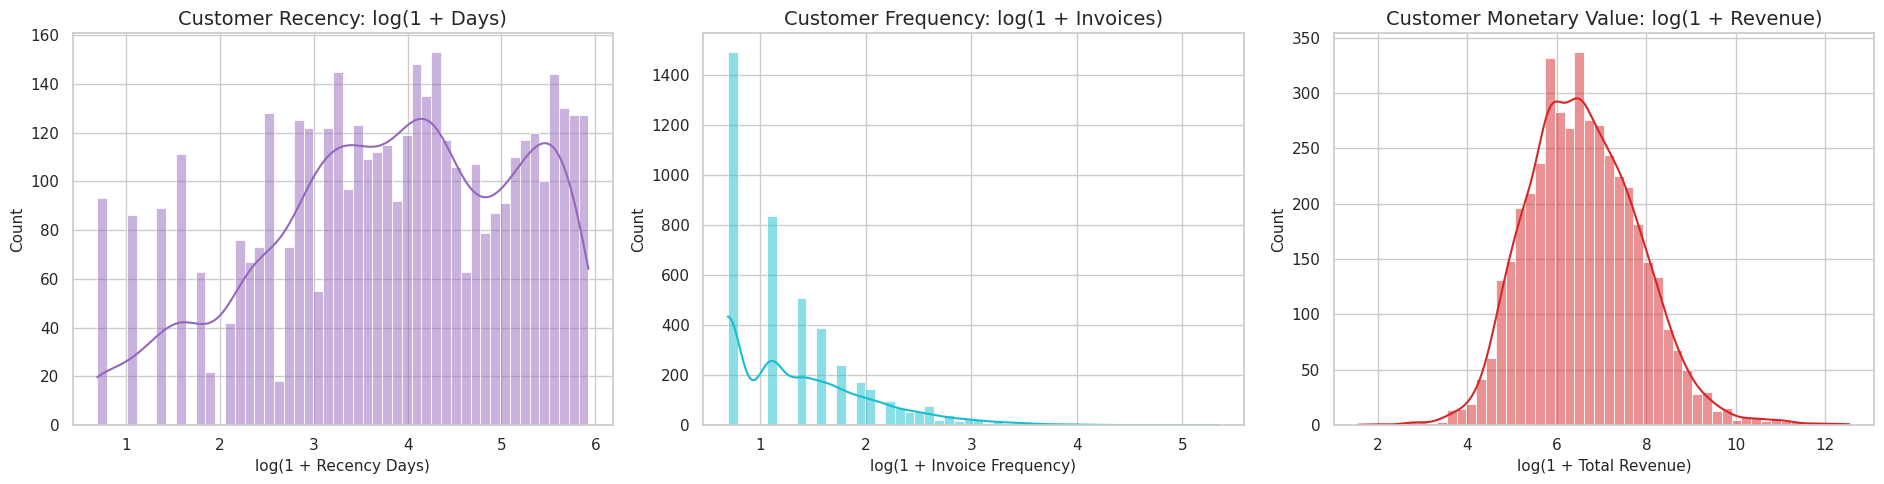

In [58]:
# RFM-style customer distributions
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.histplot(
    np.log1p(customer_eda["RecencyDays"]),
    bins=50,
    kde=True,
    ax=axes[0],
    color="#9467bd"
)
axes[0].set_title("Customer Recency: log(1 + Days)")
axes[0].set_xlabel("log(1 + Recency Days)")

sns.histplot(
    np.log1p(customer_eda["InvoiceFrequency"]),
    bins=50,
    kde=True,
    ax=axes[1],
    color="#17becf"
)
axes[1].set_title("Customer Frequency: log(1 + Invoices)")
axes[1].set_xlabel("log(1 + Invoice Frequency)")

sns.histplot(
    np.log1p(customer_eda["TotalRevenue"]),
    bins=50,
    kde=True,
    ax=axes[2],
    color="#d62728"
)
axes[2].set_title("Customer Monetary Value: log(1 + Revenue)")
axes[2].set_xlabel("log(1 + Total Revenue)")

plt.tight_layout()
plt.show()

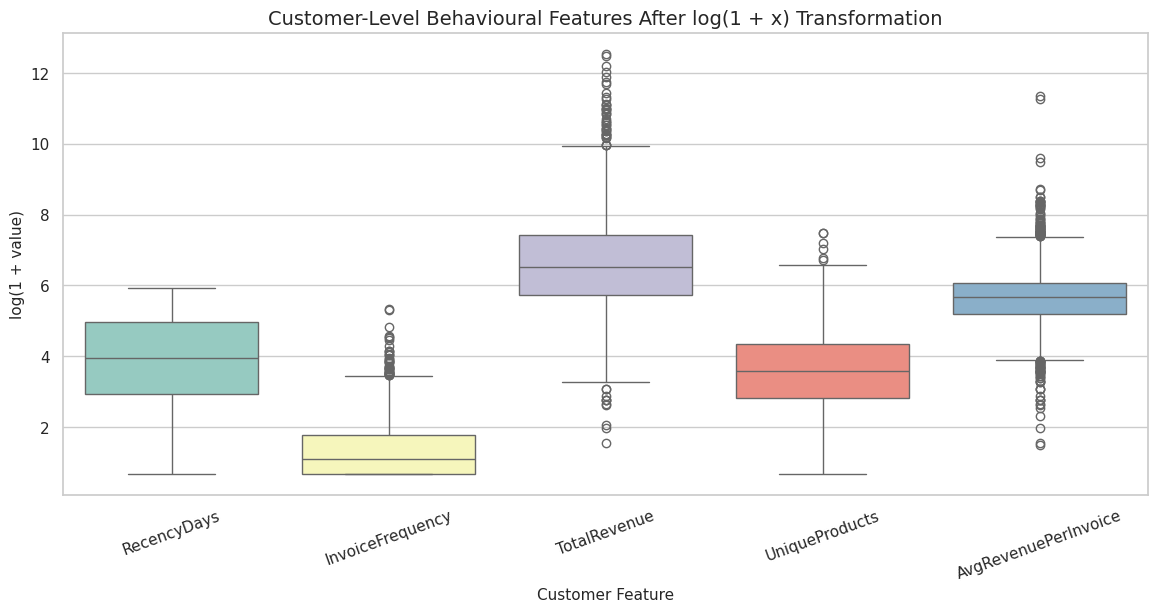

In [59]:
# Customer-level boxplots on log-transformed behavioural measures
customer_features_for_plot = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "AvgRevenuePerInvoice"
]

customer_log_plot = customer_eda[customer_features_for_plot].copy()

for column in customer_log_plot.columns:
    customer_log_plot[column] = np.log1p(customer_log_plot[column])

plt.figure(figsize=(14, 6))
sns.boxplot(data=customer_log_plot, palette="Set3")
plt.title("Customer-Level Behavioural Features After log(1 + x) Transformation")
plt.xlabel("Customer Feature")
plt.ylabel("log(1 + value)")
plt.xticks(rotation=20)
plt.show()

The customer-level EDA confirms whether RFM and behavioural features are highly skewed before modelling. RFM segmentation is a transparent baseline for this dataset, while additional features such as item diversity, return rate, and average basket value can create a richer behavioural representation.





19. Customer Feature Correlation

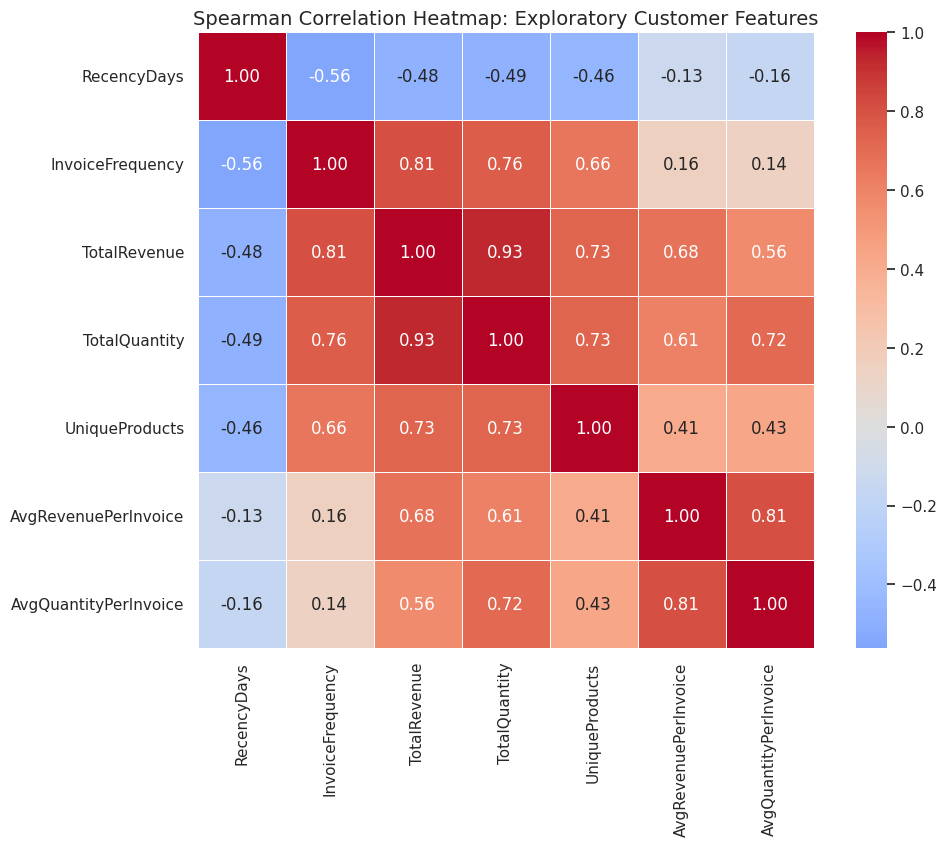

In [60]:
customer_numeric_features = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice"
]

correlation_matrix = customer_eda[customer_numeric_features].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Spearman Correlation Heatmap: Exploratory Customer Features")
plt.show()

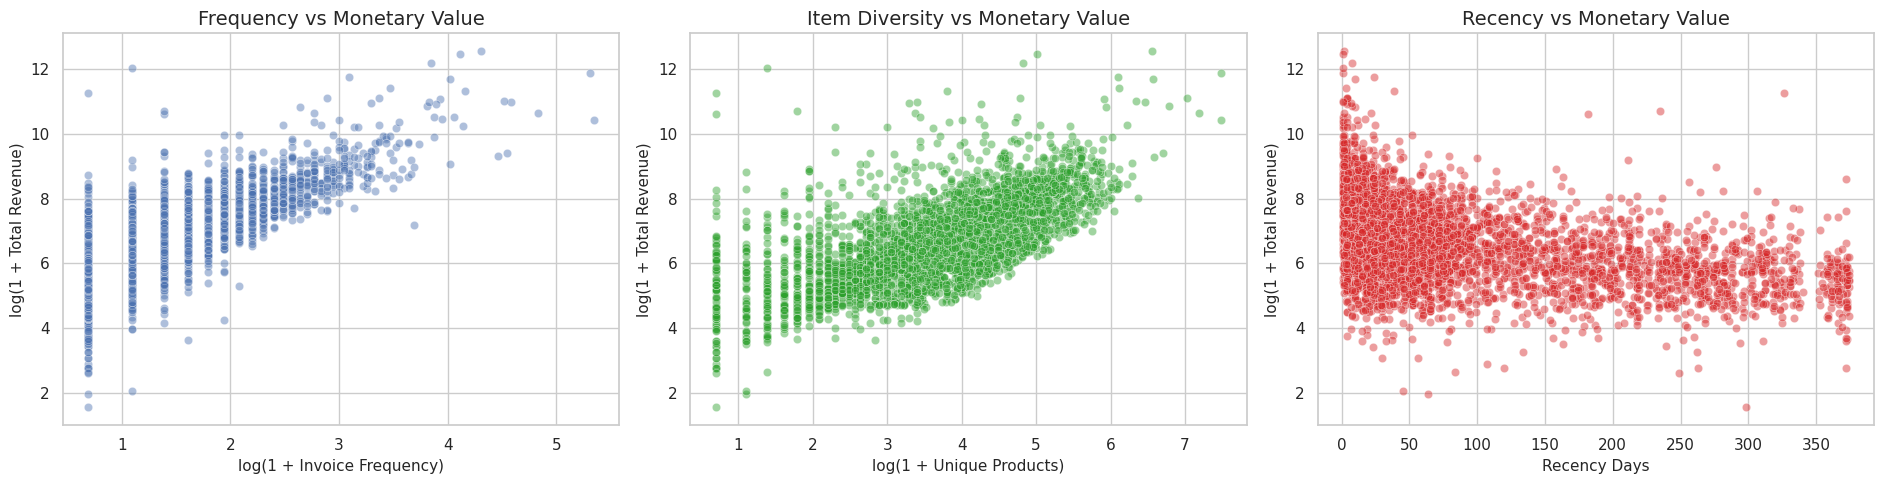

In [61]:
# Selected scatterplots in log space
plot_customer = customer_eda.copy()

for col in ["InvoiceFrequency", "TotalRevenue", "UniqueProducts", "AvgRevenuePerInvoice"]:
    plot_customer[f"log_{col}"] = np.log1p(plot_customer[col])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.scatterplot(
    data=plot_customer,
    x="log_InvoiceFrequency",
    y="log_TotalRevenue",
    alpha=0.45,
    ax=axes[0]
)
axes[0].set_title("Frequency vs Monetary Value")
axes[0].set_xlabel("log(1 + Invoice Frequency)")
axes[0].set_ylabel("log(1 + Total Revenue)")

sns.scatterplot(
    data=plot_customer,
    x="log_UniqueProducts",
    y="log_TotalRevenue",
    alpha=0.45,
    ax=axes[1],
    color="#2ca02c"
)
axes[1].set_title("Item Diversity vs Monetary Value")
axes[1].set_xlabel("log(1 + Unique Products)")
axes[1].set_ylabel("log(1 + Total Revenue)")

sns.scatterplot(
    data=plot_customer,
    x="RecencyDays",
    y="log_TotalRevenue",
    alpha=0.45,
    ax=axes[2],
    color="#d62728"
)
axes[2].set_title("Recency vs Monetary Value")
axes[2].set_xlabel("Recency Days")
axes[2].set_ylabel("log(1 + Total Revenue)")

plt.tight_layout()
plt.show()

The correlation heatmap is used to identify relationships and possible redundancy among future customer-level features. For example, TotalRevenue and InvoiceFrequency may be positively related because frequent customers often spend more.

Highly correlated features should not automatically be removed because they may represent different business concepts. However, the preprocessing member should avoid creating many near-duplicate features that overweight the same behavioural signal in distance-based clustering.

20. Invoice / Basket EDA for Association Rules

In [62]:
invoice_eda = (
    df_completed_eda
    .dropna(subset=["CustomerID"])
    .groupby("InvoiceNo", as_index=False)
    .agg(
        CustomerID=("CustomerID", "first"),
        InvoiceDate=("InvoiceDate", "min"),
        BasketRevenue=("LineRevenue", "sum"),
        BasketQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        UniqueProductDescriptions=("Description", "nunique")
    )
)

display(invoice_eda.head())

invoice_eda_summary = invoice_eda[
    [
        "BasketRevenue",
        "BasketQuantity",
        "UniqueProducts",
        "UniqueProductDescriptions"
    ]
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

invoice_eda_summary["Skewness"] = invoice_eda[
    [
        "BasketRevenue",
        "BasketQuantity",
        "UniqueProducts",
        "UniqueProductDescriptions"
    ]
].skew()

display(invoice_eda_summary)

,InvoiceNo,CustomerID,InvoiceDate,BasketRevenue,BasketQuantity,UniqueProducts,UniqueProductDescriptions
0,536365,17850.0,2010-12-01 08:26:00,139.12,40,7,7
1,536366,17850.0,2010-12-01 08:28:00,22.20,12,2,2
2,536367,13047.0,2010-12-01 08:34:00,278.73,83,12,12
3,536368,13047.0,2010-12-01 08:34:00,70.05,15,4,4
4,536369,13047.0,2010-12-01 08:35:00,17.85,3,1,1


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Skewness
BasketRevenue,18532.0,480.865956,1678.195579,0.38,8.5,38.2,158.0375,303.04,471.84,1236.5925,3849.0214,168469.6,62.139131
BasketQuantity,18532.0,278.858839,972.718727,1.00,1.0,12.0,74.0000,155.00,291.00,778.0000,2270.6900,80995.0,56.499729
UniqueProducts,18532.0,20.928178,23.816197,1.00,1.0,1.0,6.0000,15.00,27.00,62.0000,104.0000,541.0,5.356753
UniqueProductDescriptions,18532.0,20.922620,23.809117,1.00,1.0,1.0,6.0000,15.00,27.00,62.0000,104.0000,541.0,5.358919


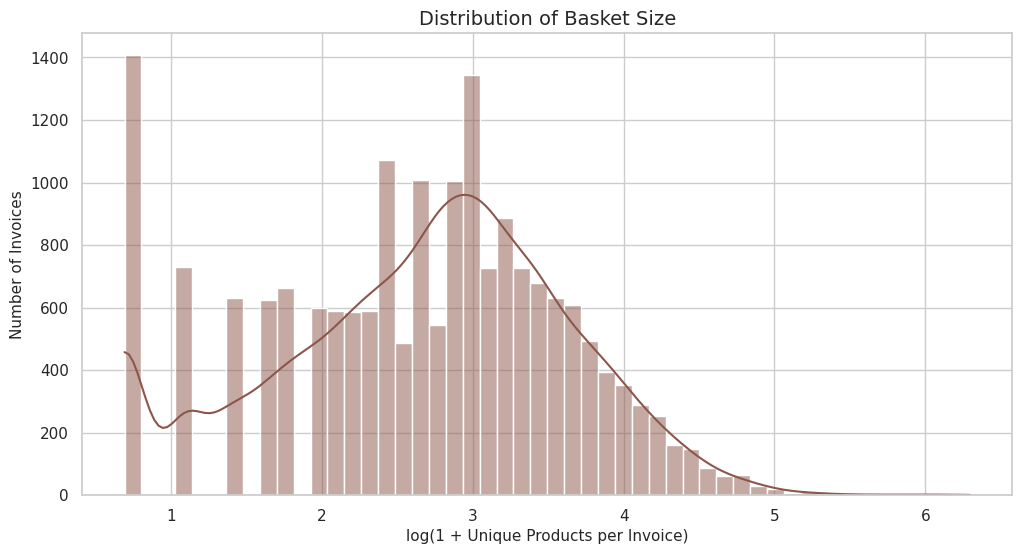

In [63]:
# Basket size distribution
plt.figure(figsize=(12, 6))
sns.histplot(
    np.log1p(invoice_eda["UniqueProducts"]),
    bins=50,
    kde=True,
    color="#8c564b"
)
plt.title("Distribution of Basket Size")
plt.xlabel("log(1 + Unique Products per Invoice)")
plt.ylabel("Number of Invoices")
plt.show()

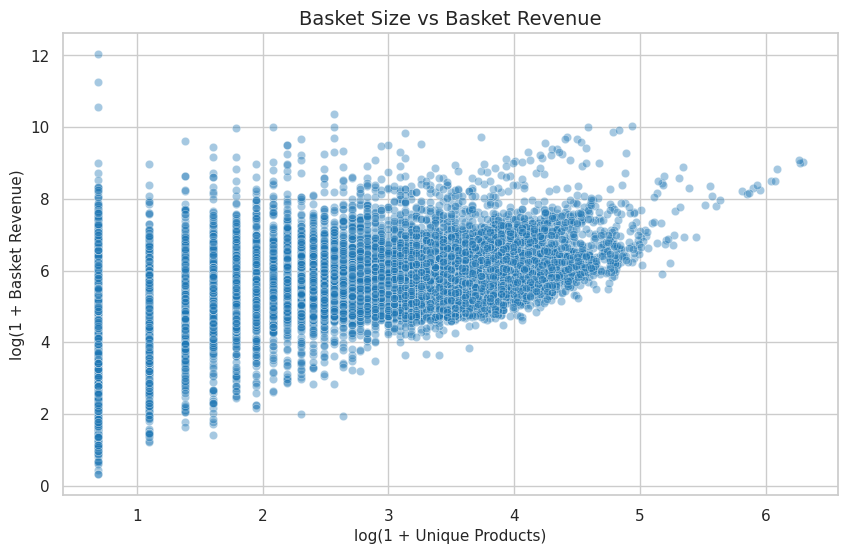

In [64]:
# Relationship between basket size and basket revenue
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=invoice_eda,
    x=np.log1p(invoice_eda["UniqueProducts"]),
    y=np.log1p(invoice_eda["BasketRevenue"]),
    alpha=0.4,
    color="#1f77b4"
)
plt.title("Basket Size vs Basket Revenue")
plt.xlabel("log(1 + Unique Products)")
plt.ylabel("log(1 + Basket Revenue)")
plt.show()

### Basket-Level Interpretation

Each completed invoice will later be treated as one transaction for market-basket analysis. Product associations should be calculated using product presence within an invoice, rather than product quantities, because Apriori examines whether products occur together in a basket.

Before Apriori, the association-rule member should:
- Use completed purchase invoices only.
- Remove cancellation invoices and invalid quantity/price records.
- Exclude non-product StockCodes where necessary.
- Use StockCode for computation and Description for readable reporting.
- Consider filtering extremely rare products.
- Run association mining separately within final customer segments.

21. Non-Product StockCode Audit

In [65]:
stockcode_audit = (
    df_completed_eda
    .groupby("StockCode", as_index=False)
    .agg(
        ExampleDescription=("Description", "first"),
        LineItems=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        Revenue=("LineRevenue", "sum"),
        Quantity=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

# Display codes that are not purely numeric.
# This is an investigation list, not an automatic removal list.
stockcode_audit["StockCode_str"] = stockcode_audit["StockCode"].astype(str).str.strip()
stockcode_audit["IsNumericCode"] = stockcode_audit["StockCode_str"].str.fullmatch(r"\d+")

special_stockcodes = stockcode_audit[
    ~stockcode_audit["IsNumericCode"]
].copy()

print("Number of non-numeric StockCodes:", special_stockcodes.shape[0])
display(special_stockcodes.head(30))

Number of non-numeric StockCodes: 1054


,StockCode,ExampleDescription,LineItems,UniqueInvoices,Revenue,Quantity,StockCode_str,IsNumericCode
3911,DOT,DOTCOM POSTAGE,706,706,206248.77,706,DOT,False
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,2198,104518.80,37660,85123A,False
3528,85099B,JUMBO BAG RED RETROSPOT,2112,2089,94340.05,48474,85099B,False
3912,M,Manual,321,289,78110.27,7224,M,False
3914,POST,POSTAGE,1126,1126,78101.88,3150,POST,False
3530,85099F,JUMBO BAG STRAWBERRY,824,812,32570.47,17273,85099F,False
3529,85099C,JUMBO BAG BAROQUE BLACK WHITE,946,933,28092.20,13922,85099C,False
2876,15056N,EDWARDIAN PARASOL NATURAL,460,456,22176.49,3954,15056N,False
3205,84029E,RED WOOLLY HOTTIE WHITE HEART.,443,429,22144.98,4765,84029E,False
3453,84997D,PINK 3 PIECE POLKADOT CUTLERY SET,478,473,19736.50,5105,84997D,False


In [66]:
# Search for descriptions that may indicate non-product or operational items
keywords = [
    "POSTAGE", "DISCOUNT", "BANK CHARGES", "MANUAL",
    "ADJUST", "CARRIAGE", "DOTCOM", "AMAZON", "SAMPLES"
]

pattern = "|".join(keywords)

special_description_rows = df_completed_eda[
    df_completed_eda["Description"]
    .astype(str)
    .str.upper()
    .str.contains(pattern, na=False)
].copy()

special_description_summary = (
    special_description_rows
    .groupby(["StockCode", "Description"], as_index=False)
    .agg(
        Rows=("InvoiceNo", "size"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        Revenue=("LineRevenue", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

display(special_description_summary.head(30))

,StockCode,Description,Rows,UniqueInvoices,Revenue
10,DOT,DOTCOM POSTAGE,706,706,206248.770
11,M,Manual,321,289,78110.270
12,POST,POSTAGE,1126,1126,78101.880
6,AMAZONFEE,AMAZON FEE,2,2,13761.090
7,B,Adjust bad debt,1,1,11062.060
9,C2,CARRIAGE,141,141,7051.000
4,23444,Next Day Carriage,79,79,1200.000
3,23099,FRENCH CARRIAGE LANTERN,59,58,925.350
5,85168B,BLACK BAROQUE CARRIAGE CLOCK,35,35,432.790
16,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,7,7,175.530


Some StockCodes may represent operational charges, postage, discounts, adjustments, or other non-merchandise entries rather than physical products. These entries may be valid financial records but should be reviewed before item-diversity calculation and Apriori market-basket analysis.

The preprocessing and association-rule members should produce and document a final rule for excluding non-product codes. The rule must be based on inspection of StockCode and Description values, not only on arbitrary assumptions.

22. PCA Readiness Note

PCA will be used later only after customer-level features have been cleaned, transformed, and scaled. It can reduce the customer-feature space to two principal components for visualising cluster separation and possible unusual observations.

PCA is not used at the raw invoice-line stage because the clustering unit of analysis is the customer, not an individual invoice line.

23. Automated EDA Insight Log

In [67]:
total_rows = len(df_raw)
missing_customer_pct = df_raw["CustomerID"].isna().mean() * 100
missing_description_pct = df_raw["Description"].isna().mean() * 100
cancellation_pct = df_eda["IsCancellation"].mean() * 100
nonpositive_quantity_pct = (df_raw["Quantity"] <= 0).mean() * 100
nonpositive_price_pct = (df_raw["UnitPrice"] <= 0).mean() * 100
duplicate_pct = df_raw.duplicated().mean() * 100

customer_revenue_skew = customer_eda["TotalRevenue"].skew()
customer_frequency_skew = customer_eda["InvoiceFrequency"].skew()
customer_recency_skew = customer_eda["RecencyDays"].skew()

top_country = country_summary.iloc[0]["Country"]
top_country_share = country_summary.iloc[0]["Revenue Share (%)"]

top_product = top_products_revenue.iloc[0]["Description"]
top_product_revenue = top_products_revenue.iloc[0]["Revenue"]

insight_log = pd.DataFrame({
    "EDA Area": [
        "Dataset granularity",
        "Missing CustomerID",
        "Missing Description",
        "Cancellations",
        "Invalid quantity",
        "Invalid UnitPrice",
        "Exact duplicates",
        "Customer monetary skewness",
        "Customer frequency skewness",
        "Customer recency skewness",
        "Geographical concentration",
        "Product concentration"
    ],
    "Observed Evidence": [
        "Raw data are invoice-line records, while the segmentation unit is the customer.",
        f"{missing_customer_pct:.2f}% of rows have a missing CustomerID.",
        f"{missing_description_pct:.2f}% of rows have a missing Description.",
        f"{cancellation_pct:.2f}% of rows are cancellation invoices (InvoiceNo starts with C).",
        f"{nonpositive_quantity_pct:.2f}% of rows have Quantity <= 0.",
        f"{nonpositive_price_pct:.2f}% of rows have UnitPrice <= 0.",
        f"{duplicate_pct:.4f}% of rows are exact duplicates.",
        f"Customer total revenue skewness = {customer_revenue_skew:.2f}.",
        f"Customer invoice frequency skewness = {customer_frequency_skew:.2f}.",
        f"Customer recency skewness = {customer_recency_skew:.2f}.",
        f"{top_country} is the highest-revenue country with {top_country_share:.2f}% of completed-purchase revenue.",
        f"Top revenue product: {top_product} with revenue of £{top_product_revenue:,.2f}."
    ],
    "Implication for Next Phase": [
        "Aggregate valid transactions to customer level before clustering.",
        "Remove rows missing CustomerID from customer-level clustering data; do not impute identifiers.",
        "Inspect before association analysis; descriptions are needed for interpretable product rules.",
        "Separate cancellations/returns from completed purchases; consider return behaviour for a feature.",
        "Exclude non-positive quantities from completed-purchase RFM and market-basket data.",
        "Exclude non-positive prices from revenue-based modelling and basket analysis.",
        "Inspect exact duplicates and remove only confirmed duplicates.",
        "Use log1p transformation and RobustScaler for monetary-related customer features.",
        "Use log1p transformation and RobustScaler for frequency-related customer features.",
        "Review recency distribution; scaling remains necessary before distance-based clustering.",
        "Treat Country mainly as a profiling variable unless inclusion is clearly justified.",
        "Use minimum-support thresholds and rare-item filtering for association rules."
    ]
})

display(insight_log)

,EDA Area,Observed Evidence,Implication for Next Phase
0,Dataset granularity,"Raw data are invoice-line records, while the s...",Aggregate valid transactions to customer level...
1,Missing CustomerID,24.93% of rows have a missing CustomerID.,Remove rows missing CustomerID from customer-l...
2,Missing Description,0.27% of rows have a missing Description.,Inspect before association analysis; descripti...
3,Cancellations,1.71% of rows are cancellation invoices (Invoi...,Separate cancellations/returns from completed ...
4,Invalid quantity,1.96% of rows have Quantity <= 0.,Exclude non-positive quantities from completed...
5,Invalid UnitPrice,0.46% of rows have UnitPrice <= 0.,Exclude non-positive prices from revenue-based...
6,Exact duplicates,0.9721% of rows are exact duplicates.,Inspect exact duplicates and remove only confi...
7,Customer monetary skewness,Customer total revenue skewness = 19.32.,Use log1p transformation and RobustScaler for ...
8,Customer frequency skewness,Customer invoice frequency skewness = 12.07.,Use log1p transformation and RobustScaler for ...
9,Customer recency skewness,Customer recency skewness = 1.25.,Review recency distribution; scaling remains n...


In [68]:
# Save the insight log to Drive for use in the final report
OUTPUT_DIR = "/content/drive/MyDrive/ML Project/project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

insight_log_path = os.path.join(OUTPUT_DIR, "eda_insight_log.csv")
insight_log.to_csv(insight_log_path, index=False)

print("EDA insight log saved to:")
print(insight_log_path)

EDA insight log saved to:
/content/drive/MyDrive/ML Project/project_outputs/eda_insight_log.csv


Handover to the Preprocessing Member

## 24. Handover: EDA Findings to Preprocessing and Feature Engineering

Based on the exploratory analysis, the preprocessing and feature-engineering stage should implement the following decisions.

| EDA finding | Required preprocessing / feature-engineering action | Reason |
|---|---|---|
| Raw data are invoice-line records | Aggregate valid transaction data to customer level | Customer segmentation requires one row per customer |
| CustomerID contains missing values | Remove rows with missing CustomerID from segmentation data | Customer-level RFM and behavioural features cannot be calculated without a customer identifier |
| Cancellation invoices exist | Create a cancellation flag; exclude cancellation invoices from completed-purchase RFM and Apriori datasets | Cancellations are reversals/returns rather than completed purchase demand |
| Negative or zero Quantity / UnitPrice values exist | Retain only Quantity > 0 and UnitPrice > 0 for completed-purchase dataset | Valid revenue and product baskets require positive purchases |
| Exact duplicates may exist | Inspect and remove only confirmed exact duplicate records | Avoid removing valid repeated purchases |
| Quantity, revenue, frequency, and basket features are highly skewed | Apply `log1p` transformation to appropriate non-negative customer features | Reduce right-skewness and extreme-value influence |
| Wholesale / high-value customers may exist | Use RobustScaler after transformations | Robust scaling is less sensitive to extreme values |
| Product codes include possible operational entries | Inspect and exclude non-product codes from item diversity and Apriori data | Product association rules should represent merchandise relationships |
| Country is concentrated and categorical | Use primarily for profiling and recommendation context | Avoid allowing location to dominate behavioural distance calculations |
| Product demand is long-tailed | Filter extremely rare products when generating Apriori rules | Reduce weak, unhelpful, and overly specific rules |

# Preprocessing , Feature Engineering & Unsupervised Feature Selection - IT24101801 - Vimukthi L.H.T.P
This section uses **all identified customers** for exploratory clustering (no mandatory train/test split). It preserves the source rows and creates customer-level and invoice-level data. It includes before/after EDA, Filter and Wrapper feature-selection comparisons, and an **exploratory only** pseudo-label diagnostic.

**Validation note:** No split is required to explore clusters, but Member 3 should still report clustering metrics, cluster sizes, stability across random seeds or bootstrap samples, and business interpretation. An optional holdout evaluation is useful if assessing generalization to new customers.

**All Member 2 outputs are saved inside:** `/content/drive/MyDrive/ML Project/project_outputs/pre_process/`. Run this section after Member 1.


## Step 1 — Setup and output folder
Create a working copy without changing raw records. All Member 2 files will be written into the **pre_process** subfolder; Member 1 files remain in the parent folder.


In [69]:
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestClassifier
import joblib

OUTPUT_DIR = '/content/drive/MyDrive/ML Project/project_outputs/pre_process'
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42

required_cols = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
                 'UnitPrice', 'CustomerID', 'Country']
assert set(required_cols).issubset(df_raw.columns)
df_pre = df_raw.copy()
print('Raw shape:', df_raw.shape)
print('Member 2 output folder:', OUTPUT_DIR)


Raw shape: (541909, 8)
Member 2 output folder: /content/drive/MyDrive/ML Project/project_outputs/pre_process


## Step 2 — Fix data types
- `InvoiceNo`, `StockCode` = text identifiers
- `InvoiceDate` = date
- `Quantity`, `UnitPrice` = numbers
- `CustomerID` = identifier (not a prediction feature)

In [70]:
for col in ['InvoiceNo', 'StockCode', 'Description']:
    df_pre[col] = df_pre[col].astype('string').str.strip()

df_pre['InvoiceDate'] = pd.to_datetime(df_pre['InvoiceDate'], errors='coerce')
for col in ['Quantity', 'UnitPrice', 'CustomerID']:
    df_pre[col] = pd.to_numeric(df_pre[col], errors='coerce')
df_pre['CustomerID'] = df_pre['CustomerID'].astype('Int64')
print(df_pre[required_cols].dtypes)

InvoiceNo      string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


## Step 2A — Before cleaning: visual data-quality audit
These charts summarize the **raw transaction data**. They do not modify or remove rows. Missing CustomerID values affect customer-level clustering; cancellations and non-positive values require separate handling.

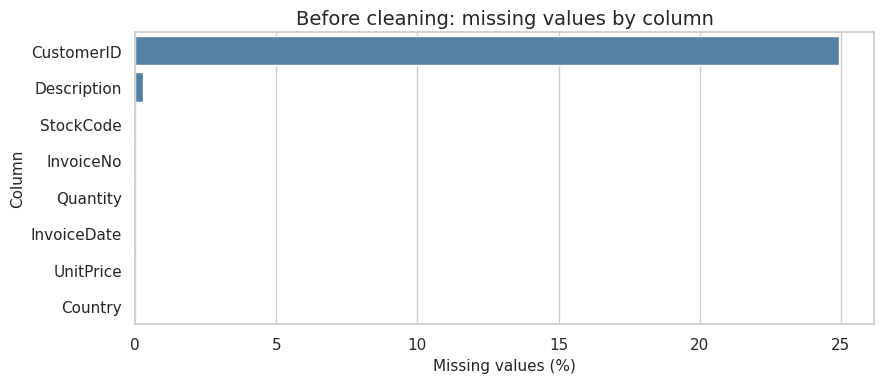

Raw rows: 541909
Missing CustomerID: 135080
Exact duplicate rows: 5268


In [71]:
# Raw missing-value percentages
raw_missing_pct = df_pre.isna().mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=raw_missing_pct.values, y=raw_missing_pct.index, color='steelblue')
plt.title('Before cleaning: missing values by column')
plt.xlabel('Missing values (%)')
plt.ylabel('Column')
plt.tight_layout()
plt.show()

print('Raw rows:', len(df_pre))
print('Missing CustomerID:', df_pre['CustomerID'].isna().sum())
print('Exact duplicate rows:', df_pre.duplicated().sum())

### Before cleaning — quantity and price distributions
The plots focus on a typical value range (up to the 99th percentile of positive values). This is **visual trimming only**, not outlier removal. Non-positive values are counted separately.

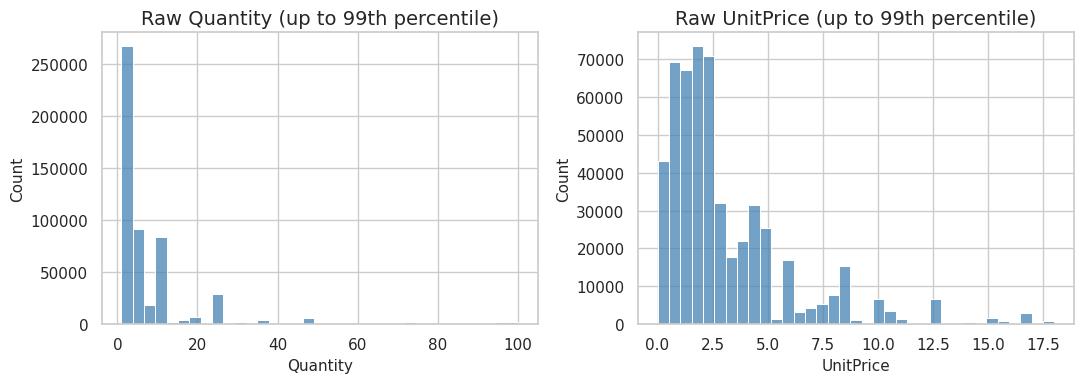

Non-positive Quantity: 10624
Non-positive UnitPrice: 2517


In [72]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ['Quantity', 'UnitPrice']):
    positive = df_pre.loc[df_pre[feature] > 0, feature].dropna()
    upper = positive.quantile(0.99)
    sns.histplot(positive[positive <= upper], bins=35, ax=ax, color='steelblue')
    ax.set_title(f'Raw {feature} (up to 99th percentile)')
    ax.set_xlabel(feature)
plt.tight_layout()
plt.show()
print('Non-positive Quantity:', (df_pre['Quantity'] <= 0).sum())
print('Non-positive UnitPrice:', (df_pre['UnitPrice'] <= 0).sum())

## Step 3 — Check missing values and duplicates
**EDA link:** Member 1 found missing customer identifiers and duplicate invoice lines. Flag duplicates, but do not remove them without business evidence.

In [73]:
missing_customer_rows = int(df_pre['CustomerID'].isna().sum())
missing_description_rows = int(df_pre['Description'].isna().sum())
exact_duplicate_rows = int(df_raw.duplicated().sum())

missing_dup_audit = pd.DataFrame({
    'Issue': ['Missing CustomerID', 'Missing Description', 'Exact duplicate rows'],
    'Rows': [missing_customer_rows, missing_description_rows, exact_duplicate_rows],
    'Decision': ['Exclude from segmentation', 'Keep when StockCode is available',
                 'Keep; investigate possible genuine repeats']
})
display(missing_dup_audit)

,Issue,Rows,Decision
0,Missing CustomerID,135080,Exclude from segmentation
1,Missing Description,1454,Keep when StockCode is available
2,Exact duplicate rows,5268,Keep; investigate possible genuine repeats


## Step 4 — Identify completed purchases
Only rows with **known customer + valid date + non-cancellation + positive quantity + positive price** count as completed purchases. Invoice numbers beginning with `C` indicate cancellation.

In [74]:
df_pre['IsCancellation'] = df_pre['InvoiceNo'].str.upper().str.startswith('C').fillna(False)
df_pre['HasCustomerID'] = df_pre['CustomerID'].notna()
df_pre['HasValidDate'] = df_pre['InvoiceDate'].notna()
df_pre['HasPositiveQuantity'] = df_pre['Quantity'].gt(0).fillna(False)
df_pre['HasPositiveUnitPrice'] = df_pre['UnitPrice'].gt(0).fillna(False)

df_pre['IsCompletedPurchase'] = (
    df_pre['HasCustomerID'] & df_pre['HasValidDate'] &
    ~df_pre['IsCancellation'] & df_pre['HasPositiveQuantity'] &
    df_pre['HasPositiveUnitPrice']
)

transaction_audit = pd.DataFrame({
    'Condition': ['Raw', 'Missing CustomerID', 'Missing/invalid date', 'Cancellations',
                  'Invalid quantity', 'Invalid price', 'Completed purchases'],
    'Rows': [len(df_pre), missing_customer_rows, (~df_pre['HasValidDate']).sum(),
             df_pre['IsCancellation'].sum(), (~df_pre['HasPositiveQuantity']).sum(),
             (~df_pre['HasPositiveUnitPrice']).sum(), df_pre['IsCompletedPurchase'].sum()]
})
transaction_audit['Percent'] = (100 * transaction_audit['Rows'] / len(df_pre)).round(2)
display(transaction_audit)
# Counts overlap and must not be added together.

,Condition,Rows,Percent
0,Raw,541909,100.00
1,Missing CustomerID,135080,24.93
2,Missing/invalid date,0,0.00
3,Cancellations,9288,1.71
4,Invalid quantity,10624,1.96
5,Invalid price,2517,0.46
6,Completed purchases,397884,73.42


## Step 5 — Create the clean purchase table
Keep customer-known invoices for the cancellation feature. Make a separate completed-purchase dataset for RFM.

In [75]:
df_known_customer = df_pre[df_pre['HasCustomerID'] & df_pre['HasValidDate']].copy()
df_completed = df_pre[df_pre['IsCompletedPurchase']].copy()
df_completed['LineRevenue'] = df_completed['Quantity'] * df_completed['UnitPrice']

assert df_completed['CustomerID'].notna().all()
assert (~df_completed['IsCancellation']).all()
assert (df_completed['Quantity'] > 0).all()
assert (df_completed['UnitPrice'] > 0).all()
assert (df_completed['LineRevenue'] > 0).all()
print('Completed purchase lines:', len(df_completed))
print('Customers:', df_completed['CustomerID'].nunique())

Completed purchase lines: 397884
Customers: 4338


## Step 5A — After cleaning: compare the retained purchase data
These plots check whether the filtering rules produced positive completed-purchase records with known customers. The comparison is based on the raw and cleaned **invoice-line counts**, not unique customers.

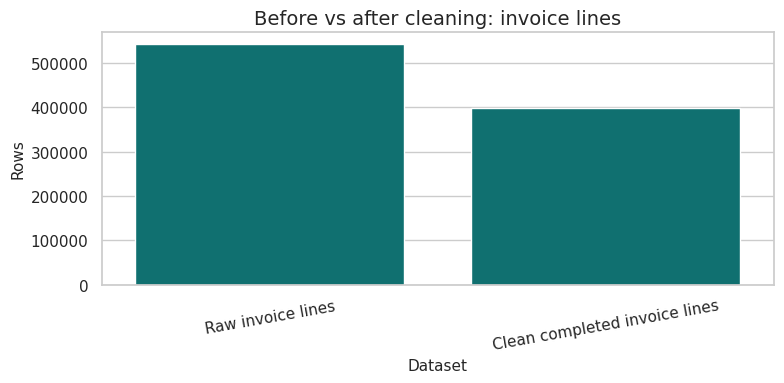

,Dataset,Rows
0,Raw invoice lines,541909
1,Clean completed invoice lines,397884


Rows retained (%): 73.42
Missing CustomerID after cleaning: 0
Non-positive quantity after cleaning: 0
Non-positive price after cleaning: 0
Cancellation lines after cleaning: 0


In [76]:
row_comparison = pd.DataFrame({
    'Dataset': ['Raw invoice lines', 'Clean completed invoice lines'],
    'Rows': [len(df_pre), len(df_completed)]
})
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=row_comparison, x='Dataset', y='Rows', color='teal', ax=ax)
ax.set_title('Before vs after cleaning: invoice lines')
ax.set_ylabel('Rows')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

display(row_comparison)
print('Rows retained (%):', round(100 * len(df_completed) / len(df_pre), 2))
print('Missing CustomerID after cleaning:', df_completed['CustomerID'].isna().sum())
print('Non-positive quantity after cleaning:', (df_completed['Quantity'] <= 0).sum())
print('Non-positive price after cleaning:', (df_completed['UnitPrice'] <= 0).sum())
print('Cancellation lines after cleaning:', df_completed['IsCancellation'].sum())

### Before vs after cleaning — typical quantity distribution
Compare distributions within the **same displayed x-axis range** so the effect of filtering is visible. High-end values remain in the actual data.

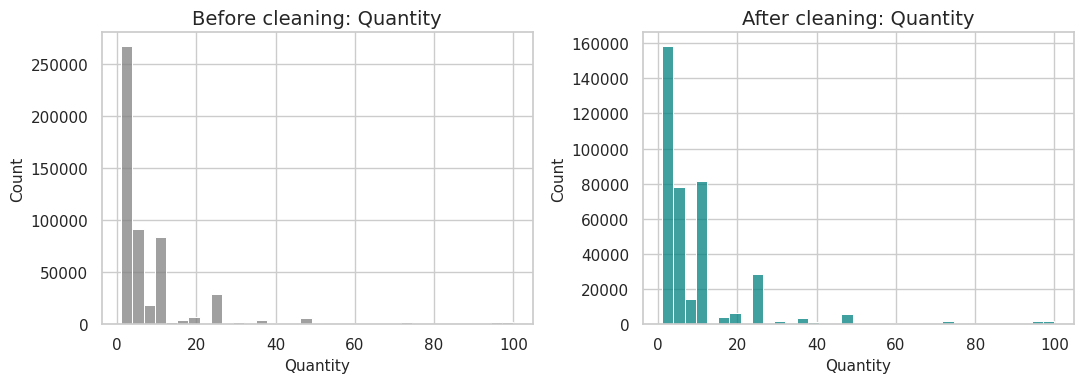

In [77]:
quantity_limit = df_pre.loc[df_pre['Quantity'] > 0, 'Quantity'].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
raw_q = df_pre.loc[df_pre['Quantity'].between(0, quantity_limit), 'Quantity']
clean_q = df_completed.loc[df_completed['Quantity'] <= quantity_limit, 'Quantity']
sns.histplot(raw_q, bins=35, ax=axes[0], color='gray')
sns.histplot(clean_q, bins=35, ax=axes[1], color='teal')
axes[0].set_title('Before cleaning: Quantity')
axes[1].set_title('After cleaning: Quantity')
for ax in axes:
    ax.set_xlabel('Quantity')
plt.tight_layout()
plt.show()

## Step 6 — Separate real merchandise from service/fee codes
Only **explicit listed codes** are excluded from the basket and product-diversity calculations; gross purchase revenue is still based on all completed lines.

In [78]:
OPERATIONAL_CODES = {
    'POST', 'DOT', 'M', 'AMAZONFEE', 'BANK CHARGES',
    'C2', 'B', 'S', 'D', 'CRUK'
}
df_completed['IsMerchandise'] = ~df_completed['StockCode'].str.upper().isin(OPERATIONAL_CODES).fillna(False)
df_merchandise = df_completed[df_completed['IsMerchandise']].copy()
operational_audit = (df_completed[~df_completed['IsMerchandise']]
    .groupby('StockCode', dropna=False)
    .agg(Lines=('InvoiceNo', 'size'), ExampleDescription=('Description', 'first'),
         GrossRevenue=('LineRevenue', 'sum')).reset_index())
display(operational_audit)
print('Merchandise lines:', len(df_merchandise))

,StockCode,Lines,ExampleDescription,GrossRevenue
0,BANK CHARGES,12,Bank Charges,165.001
1,C2,133,CARRIAGE,6686.000
2,DOT,16,DOTCOM POSTAGE,11906.360
3,M,284,Manual,53779.930
4,POST,1099,POSTAGE,77803.960


Merchandise lines: 396340


## Step 7 — Prepare invoice baskets for Apriori
One basket = one `InvoiceNo`. We retain invoice-product rows now; Apriori will run in the modelling stage.

In [79]:
merchandise_basket_source = df_merchandise[
    ['InvoiceNo', 'CustomerID', 'StockCode', 'Description',
     'Quantity', 'InvoiceDate', 'Country']
].copy()
basket_item_counts = (merchandise_basket_source
    .groupby(['InvoiceNo', 'CustomerID', 'StockCode'])['Quantity']
    .sum().reset_index(name='Units'))
display(basket_item_counts.head())

,InvoiceNo,CustomerID,StockCode,Units
0,536365,17850,21730,6
1,536365,17850,22752,2
2,536365,17850,71053,6
3,536365,17850,84029E,6
4,536365,17850,84029G,6


## Step 8 — Group invoices into customer profiles (RFM)
R = days since last purchase; F = distinct invoices; M = completed-purchase total revenue. One row per customer.

In [80]:
analysis_date = df_completed['InvoiceDate'].max() + pd.Timedelta(days=1)
customer_features = (df_completed.groupby('CustomerID', as_index=False)
    .agg(FirstPurchaseDate=('InvoiceDate', 'min'),
         LastPurchaseDate=('InvoiceDate', 'max'),
         InvoiceFrequency=('InvoiceNo', 'nunique'),
         TotalRevenue=('LineRevenue', 'sum'),
         TotalQuantity=('Quantity', 'sum')))
customer_features['RecencyDays'] = (analysis_date - customer_features['LastPurchaseDate']).dt.days
customer_features['CustomerTenureDays'] = (customer_features['LastPurchaseDate'] - customer_features['FirstPurchaseDate']).dt.days
customer_features['AvgRevenuePerInvoice'] = customer_features['TotalRevenue'] / customer_features['InvoiceFrequency']
customer_features['AvgQuantityPerInvoice'] = customer_features['TotalQuantity'] / customer_features['InvoiceFrequency']
print('Customer rows:', len(customer_features))
display(customer_features.head())

Customer rows: 4338


,CustomerID,FirstPurchaseDate,LastPurchaseDate,InvoiceFrequency,TotalRevenue,TotalQuantity,RecencyDays,CustomerTenureDays,AvgRevenuePerInvoice,AvgQuantityPerInvoice
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,326,0,77183.600000,74215.000000
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,2458,2,365,615.714286,351.142857
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,2341,75,282,449.310000,585.250000
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,631,19,0,1757.550000,631.000000
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,310,0,334.400000,197.000000


## Step 9 — Add product diversity and country for profiling
`UniqueProducts` counts **different merchandise StockCodes**, not total units. Country is for later describing clusters, not computing distances.

In [81]:
product_diversity = df_merchandise.groupby('CustomerID')['StockCode'].nunique()
customer_features['UniqueProducts'] = (
    customer_features['CustomerID'].map(product_diversity).fillna(0).astype(int)
)
country_mode = df_completed.groupby('CustomerID')['Country'].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else 'Unknown'
)
customer_features['PrimaryCountry'] = customer_features['CustomerID'].map(country_mode)
display(customer_features[['CustomerID', 'UniqueProducts', 'PrimaryCountry']].head())

,CustomerID,UniqueProducts,PrimaryCountry
0,12346,1,United Kingdom
1,12347,103,Iceland
2,12348,21,Finland
3,12349,72,Italy
4,12350,16,Norway


## Step 10 — Cancellation rate
Count distinct invoices first (not invoice lines). `CancellationRate` = cancellation invoices / all observed invoices.

In [82]:
known_invoices = df_known_customer[
    ['CustomerID', 'InvoiceNo', 'IsCancellation']
].dropna(subset=['InvoiceNo']).drop_duplicates()
assert not known_invoices.groupby(['CustomerID', 'InvoiceNo'])['IsCancellation'].nunique().gt(1).any()
invoice_counts = known_invoices.groupby('CustomerID').agg(
    CancellationInvoices=('IsCancellation', 'sum'),
    TotalInvoicesObserved=('InvoiceNo', 'nunique')
)
customer_features = customer_features.merge(invoice_counts, on='CustomerID', how='left')
customer_features['CancellationRate'] = (
    customer_features['CancellationInvoices'] / customer_features['TotalInvoicesObserved']
).fillna(0)
customer_features = customer_features.sort_values('CustomerID').reset_index(drop=True)
assert customer_features['CustomerID'].is_unique
assert customer_features['CancellationRate'].between(0,1).all()
display(customer_features.head())

,CustomerID,FirstPurchaseDate,LastPurchaseDate,InvoiceFrequency,TotalRevenue,TotalQuantity,RecencyDays,CustomerTenureDays,AvgRevenuePerInvoice,AvgQuantityPerInvoice,UniqueProducts,PrimaryCountry,CancellationInvoices,TotalInvoicesObserved,CancellationRate
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,326,0,77183.600000,74215.000000,1,United Kingdom,1,2,0.5
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,2458,2,365,615.714286,351.142857,103,Iceland,0,7,0.0
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,2341,75,282,449.310000,585.250000,21,Finland,0,4,0.0
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,631,19,0,1757.550000,631.000000,72,Italy,0,1,0.0
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,310,0,334.400000,197.000000,16,Norway,0,1,0.0


## Step 11 — Customer feature dictionary and quality check
Review missing values, skewness and descriptive statistics before selecting model columns.

In [83]:
feature_dictionary = pd.DataFrame([
    ('RecencyDays','Days since last completed purchase'),
    ('InvoiceFrequency','Number of completed invoices'),
    ('TotalRevenue','Total completed line revenue including operational charges'),
    ('TotalQuantity','Total units bought'),
    ('UniqueProducts','Number of different merchandise StockCodes'),
    ('AvgRevenuePerInvoice','TotalRevenue / InvoiceFrequency'),
    ('AvgQuantityPerInvoice','TotalQuantity / InvoiceFrequency'),
    ('CancellationRate','Cancelled invoices / all invoices'),
    ('CustomerTenureDays','Days between first and last completed purchase'),
    ('PrimaryCountry','Most common country; profiling only')
], columns=['Variable','Meaning'])
candidate_features = ['RecencyDays','InvoiceFrequency','TotalRevenue',
                      'TotalQuantity','UniqueProducts','AvgRevenuePerInvoice',
                      'AvgQuantityPerInvoice','CancellationRate']
display(feature_dictionary)
display(customer_features[candidate_features].describe().T)
display(customer_features[candidate_features].skew().to_frame('Skewness'))
print('Missing customer features:', customer_features[candidate_features].isna().sum().sum())

,Variable,Meaning
0,RecencyDays,Days since last completed purchase
1,InvoiceFrequency,Number of completed invoices
2,TotalRevenue,Total completed line revenue including operati...
3,TotalQuantity,Total units bought
4,UniqueProducts,Number of different merchandise StockCodes
5,AvgRevenuePerInvoice,TotalRevenue / InvoiceFrequency
6,AvgQuantityPerInvoice,TotalQuantity / InvoiceFrequency
7,CancellationRate,Cancelled invoices / all invoices
8,CustomerTenureDays,Days between first and last completed purchase
9,PrimaryCountry,Most common country; profiling only


,count,mean,std,min,25%,50%,75%,max
RecencyDays,4338.0,92.536422,100.014169,1.0,18.0,51.0,142.0,374.0
InvoiceFrequency,4338.0,4.272015,7.697998,1.0,1.0,2.0,5.0,209.0
TotalRevenue,4338.0,2054.26646,8989.230441,3.75,307.415,674.485,1661.74,280206.02
TotalQuantity,4338.0,1191.289073,5046.081546,1.0,160.0,379.0,992.75,196915.0
UniqueProducts,4338.0,61.370217,85.288442,0.0,16.0,35.0,77.0,1785.0
AvgRevenuePerInvoice,4338.0,419.166289,1796.537944,3.45,178.625,293.9,430.11375,84236.25
AvgQuantityPerInvoice,4338.0,253.47828,1312.905974,1.0,93.0,161.75,272.0,74215.0
CancellationRate,4338.0,0.105957,0.166292,0.0,0.0,0.0,0.2,0.8


,Skewness
RecencyDays,1.246048
InvoiceFrequency,12.067031
TotalRevenue,19.324953
TotalQuantity,20.359611
UniqueProducts,6.917458
AvgRevenuePerInvoice,41.688126
AvgQuantityPerInvoice,47.991247
CancellationRate,1.403984


Missing customer features: 0


## Step 11A — Customer-level EDA before feature transformation
Clustering uses **one customer per row**, so inspect customer features instead of raw invoice-line features. These charts help justify log transformation and robust scaling.

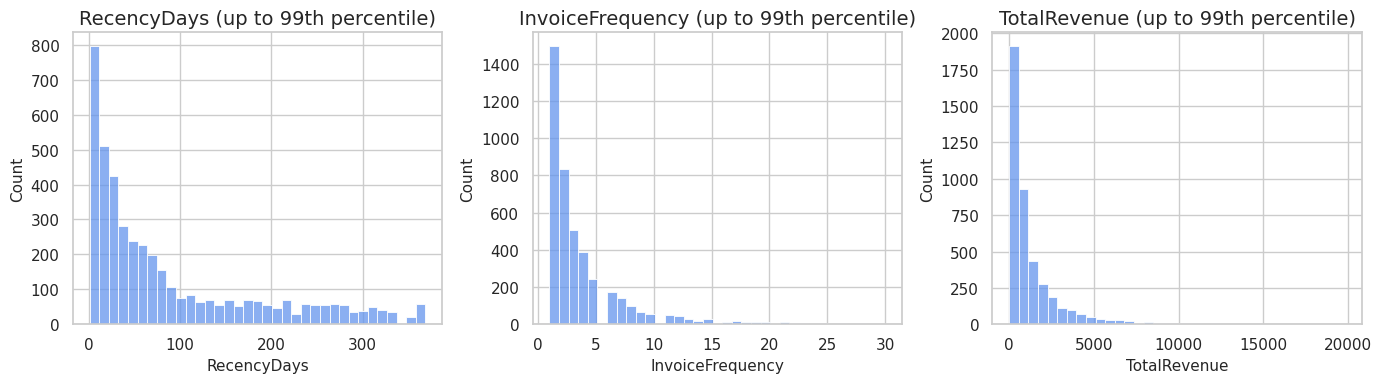

,median,mean,max
RecencyDays,51.00,92.54,374.00
InvoiceFrequency,2.00,4.27,209.00
TotalRevenue,674.48,2054.27,280206.02
UniqueProducts,35.00,61.37,1785.00
CancellationRate,0.00,0.11,0.80


Customer feature skewness:


,0
RecencyDays,1.25
InvoiceFrequency,12.07
TotalRevenue,19.32
UniqueProducts,6.92
CancellationRate,1.4


In [84]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue']):
    values = customer_features[feature].dropna()
    upper = values.quantile(0.99)
    sns.histplot(values[values <= upper], bins=35, color='cornflowerblue', ax=ax)
    ax.set_title(f'{feature} (up to 99th percentile)')
plt.tight_layout()
plt.show()

customer_summary = customer_features[['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']].agg(['median', 'mean', 'max']).T
display(customer_summary.round(2))
print('Customer feature skewness:')
display(customer_features[['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']].skew().round(2))

## Step 12 — IQR outlier audit
Q1 = 25% percentile; Q3 = 75%. Potential outliers are **flagged, not deleted**: genuine wholesale customers might have large purchases.

In [85]:
outlier_rows = []
for feature in candidate_features:
    q1 = customer_features[feature].quantile(0.25)
    q3 = customer_features[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((customer_features[feature] < lower) | (customer_features[feature] > upper)).sum()
    outlier_rows.append([feature, lower, upper, int(count), 100*count/len(customer_features)])
outlier_audit = pd.DataFrame(outlier_rows,
    columns=['Feature','IQR_Low','IQR_High','FlaggedCustomers','FlaggedPercent'])
display(outlier_audit.round(2))

,Feature,IQR_Low,IQR_High,FlaggedCustomers,FlaggedPercent
0,RecencyDays,-168.00,328.00,155,3.57
1,InvoiceFrequency,-5.00,11.00,285,6.57
2,TotalRevenue,-1724.07,3693.23,427,9.84
3,TotalQuantity,-1089.12,2241.88,400,9.22
4,UniqueProducts,-75.50,168.50,309,7.12
5,AvgRevenuePerInvoice,-198.61,807.35,290,6.69
6,AvgQuantityPerInvoice,-175.50,540.50,262,6.04
7,CancellationRate,-0.30,0.50,49,1.13


## Step 13 — Business baseline: select five features
Avoid IDs/countries as distances, and avoid over-weighting strongly overlapping spending features.

Baseline features: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']


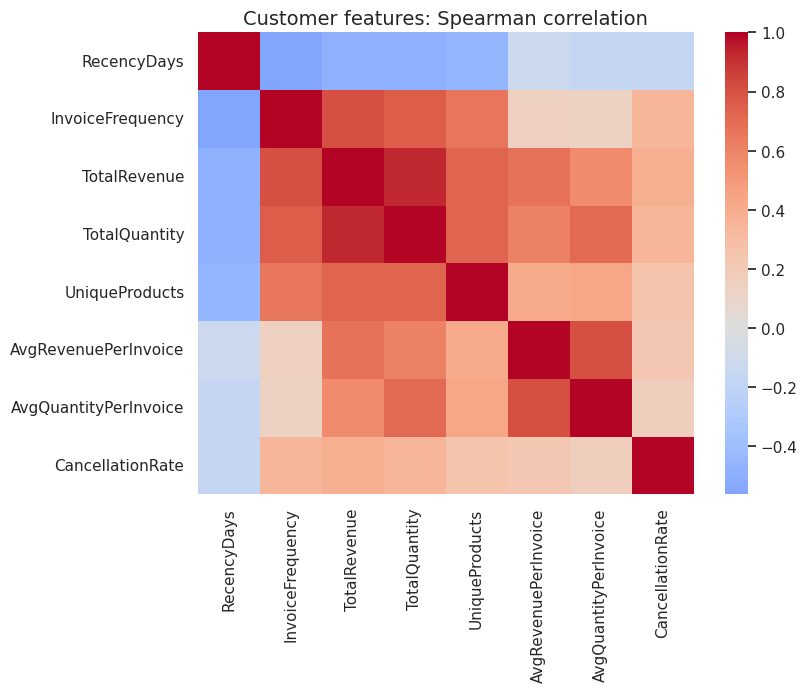

In [86]:
MODEL_FEATURES = [
    'RecencyDays', 'InvoiceFrequency', 'TotalRevenue',
    'UniqueProducts', 'CancellationRate'
]
print('Baseline features:', MODEL_FEATURES)
plt.figure(figsize=(8,6))
sns.heatmap(customer_features[candidate_features].corr(method='spearman'),
            cmap='coolwarm', center=0)
plt.title('Customer features: Spearman correlation')
plt.show()

## Step 14 — Use all customers (no mandatory train/test split)
For **exploratory unsupervised customer segmentation**, use one row per identified customer. No target label is available. This does **not** prove performance on future customers. Member 3 must assess internal clustering quality and robustness; optional holdout evaluation can be added later.


In [87]:
customer_all = customer_features.copy()
X_original = customer_all[MODEL_FEATURES].copy()
customer_ids = customer_all['CustomerID'].astype(int)
assert customer_ids.is_unique
print('Customer profiles:', len(customer_all))
print('Original feature matrix:', X_original.shape)
display(X_original.head())


Customer profiles: 4338
Original feature matrix: (4338, 5)


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
0,326,1,77183.60,1,0.5
1,2,7,4310.00,103,0.0
2,75,4,1797.24,21,0.0
3,19,1,1757.55,72,0.0
4,310,1,334.40,16,0.0


## Step 15 — Log transformation
Use `log1p(x) = ln(1+x)` on non-negative, right-skewed features; keep CancellationRate on its original scale.


In [88]:
LOG_FEATURES = ['RecencyDays','InvoiceFrequency','TotalRevenue','UniqueProducts']
def apply_log_features(frame, columns):
    result = frame.copy()
    for column in columns:
        result[column] = np.log1p(result[column])
    return result

assert (X_original[LOG_FEATURES] >= 0).all().all()
X_log = apply_log_features(X_original, LOG_FEATURES)
display(pd.DataFrame({'Before': X_original.skew(), 'AfterLog': X_log.skew()}))


,Before,AfterLog
RecencyDays,1.246048,-0.379169
InvoiceFrequency,12.067031,1.208652
TotalRevenue,19.324953,0.393553
UniqueProducts,6.917458,-0.259797
CancellationRate,1.403984,1.403984


## Step 16 — Scale the complete customer matrix
`RobustScaler` uses medians and interquartile ranges. Because this notebook is for exploratory clustering on the full dataset, it fits the scaler to **all customers**. If a future holdout test is created, refit the preprocessing only on that training partition.


In [89]:
scaler = RobustScaler()
X_preprocessed = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=MODEL_FEATURES,
    index=pd.Index(customer_ids, name='CustomerID')
)
assert np.isfinite(X_preprocessed.to_numpy()).all()
assert X_preprocessed.index.is_unique
print('Full clustering matrix:', X_preprocessed.shape)
display(X_preprocessed.head())


Full clustering matrix: (4338, 5)


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
CustomerID,,,,,
12346,0.910975,-0.369070,2.812555,-1.897197,2.5
12347,-1.413309,0.892789,1.100143,0.696341,0.0
12348,0.188015,0.464974,0.581165,-0.323254,0.0
12349,-0.473399,-0.369070,0.567918,0.464025,0.0
12350,0.886120,-0.369070,-0.415549,-0.492490,0.0


## Step 16A — After preprocessing: inspect the distributions
Compare values before transformation, after `log1p`, and after `RobustScaler`. Percentile limits are for display only.


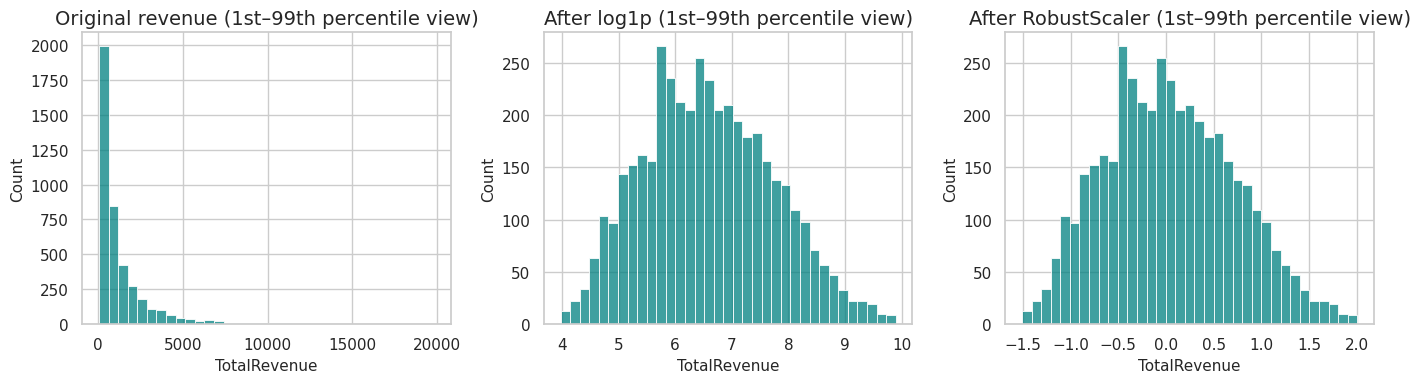

,Original skew,After log skew,After scaling skew
RecencyDays,1.246,-0.379,-0.379
InvoiceFrequency,12.067,1.209,1.209
TotalRevenue,19.325,0.394,0.394
UniqueProducts,6.917,-0.26,-0.260
CancellationRate,1.404,1.404,1.404


Missing values after scaling: 0


In [90]:
feature_to_plot = 'TotalRevenue'
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, values, title in [
    (axes[0], X_original[feature_to_plot], 'Original revenue'),
    (axes[1], X_log[feature_to_plot], 'After log1p'),
    (axes[2], X_preprocessed[feature_to_plot], 'After RobustScaler')
]:
    low, high = values.quantile([0.01, 0.99])
    sns.histplot(values[values.between(low, high)], bins=35, ax=ax, color='teal')
    ax.set_title(title + ' (1st–99th percentile view)')
plt.tight_layout()
plt.show()
display(pd.DataFrame({
    'Original skew': X_original.skew(),
    'After log skew': X_log.skew(),
    'After scaling skew': X_preprocessed.skew()
}).round(3))
print('Missing values after scaling:', X_preprocessed.isna().sum().sum())


## Step 17 — Prepare full invoice baskets and check modelling inputs
Use all identified-customer merchandise transactions for market-basket analysis. Cluster input must exclude identifiers and country. No train/test split is performed here.


In [91]:
basket_source_all = merchandise_basket_source.copy()
checks = {
    'Unique customer rows': customer_all['CustomerID'].is_unique,
    'No CustomerID distance feature': 'CustomerID' not in MODEL_FEATURES,
    'No Country distance feature': 'PrimaryCountry' not in MODEL_FEATURES,
    'Finite numeric model inputs': np.isfinite(X_preprocessed.to_numpy()).all(),
    'No missing numeric model inputs': not X_preprocessed.isna().any().any(),
    'Basket records have invoice identifiers': basket_source_all['InvoiceNo'].notna().all()
}
quality_checklist = pd.DataFrame(list(checks.items()), columns=['Check','Pass'])
assert quality_checklist['Pass'].all()
display(quality_checklist)


,Check,Pass
0,Unique customer rows,True
1,No CustomerID distance feature,True
2,No Country distance feature,True
3,Finite numeric model inputs,True
4,No missing numeric model inputs,True
5,Basket records have invoice identifiers,True


## Step 18 — Duplicate sensitivity (extra assignment evidence)
Show *how much revenue changes* if exact duplicate invoice lines are hypothetically dropped. Main dataset still retains them.

In [92]:
valid_unique = df_completed.drop_duplicates(subset=required_cols)
keep_revenue = df_completed.groupby('CustomerID')['LineRevenue'].sum()
dedup_revenue = valid_unique.groupby('CustomerID')['LineRevenue'].sum()
revenue_compare = pd.concat([keep_revenue, dedup_revenue], axis=1)
revenue_compare.columns = ['KeepDuplicates','DropDuplicates']
revenue_compare['Difference'] = revenue_compare['KeepDuplicates'] - revenue_compare['DropDuplicates']
duplicate_sensitivity = pd.DataFrame([{
    'ValidCompletedLines': len(df_completed),
    'ExactDuplicateValidLines': len(df_completed)-len(valid_unique),
    'GrossRevenue_Keep': df_completed['LineRevenue'].sum(),
    'GrossRevenue_Dedup': valid_unique['LineRevenue'].sum(),
    'RevenueImpactPercent': 100*(df_completed['LineRevenue'].sum()-valid_unique['LineRevenue'].sum())/df_completed['LineRevenue'].sum(),
    'CustomersWithRevenueDifference': int((revenue_compare['Difference'].abs()>1e-9).sum())
}])
display(duplicate_sensitivity)

,ValidCompletedLines,ExactDuplicateValidLines,GrossRevenue_Keep,GrossRevenue_Dedup,RevenueImpactPercent,CustomersWithRevenueDifference
0,397884,5192,8911407.904,8887208.894,0.271551,951


## Step 19 — Revenue definition audit
`TotalRevenue` in the baseline includes positive service/fee lines. Compare with merchandise-only revenue; do not silently switch the modelling definition.

In [93]:
revenue_definition_audit = pd.DataFrame({
    'Definition': ['All completed lines', 'Merchandise-only lines'],
    'Revenue': [df_completed['LineRevenue'].sum(), df_merchandise['LineRevenue'].sum()],
    'LineCount': [len(df_completed), len(df_merchandise)]
})
display(revenue_definition_audit)

,Definition,Revenue,LineCount
0,All completed lines,8911407.904,397884
1,Merchandise-only lines,8761066.653,396340


## Step 20 — Feature-selection candidate matrix
Scale all eight candidate features consistently using the complete customer dataset. **Filter** screens redundancy without fitting a clustering model; **Wrapper** compares specified subsets through internal cluster validation. Selection and metric evaluation on the same data can be optimistic, so Member 3 should test robustness.


In [94]:
FS_CANDIDATES = candidate_features.copy()
FS_LOG = [f for f in FS_CANDIDATES if f != 'CancellationRate']
assert (customer_all[FS_LOG] >= 0).all().all()
fs_log = apply_log_features(customer_all[FS_CANDIDATES], FS_LOG)
fs_scaler = RobustScaler()
fs_all = pd.DataFrame(
    fs_scaler.fit_transform(fs_log),
    columns=FS_CANDIDATES,
    index=pd.Index(customer_ids, name='CustomerID')
)
assert np.isfinite(fs_all.to_numpy()).all()
print('Full candidate matrix:', fs_all.shape)
display(fs_all.head())


Full candidate matrix: (4338, 8)


,RecencyDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationRate
CustomerID,,,,,,,,
12346,0.910975,-0.369070,2.812555,2.897983,-1.897197,6.359012,5.742498,2.5
12347,-1.413309,0.892789,1.100143,1.025965,0.696341,0.842683,0.723915,0.0
12348,0.188015,0.464974,0.581165,0.999180,-0.323254,0.483495,1.201987,0.0
12349,-0.473399,-0.369070,0.567918,0.279503,0.464025,2.039529,1.272466,0.0
12350,0.886120,-0.369070,-0.415549,-0.358173,-0.492490,0.146988,0.183883,0.0


## Step 21 — FILTER: variance and Spearman correlation
Screen near-constant features, then reject candidates with absolute Spearman correlation of at least 0.95 with an already-selected feature. Correlation cutoffs are heuristics, not universal truths. This is an **unsupervised filter method** because it does not require labels.


In [95]:
feature_variances = fs_all.var(ddof=0)
filter_selected = []
filter_rejected = []
priority = MODEL_FEATURES + [f for f in FS_CANDIDATES if f not in MODEL_FEATURES]
corr = fs_all.corr(method='spearman').abs().fillna(0)
for feature in priority:
    if feature_variances[feature] <= 1e-8:
        filter_rejected.append([feature, 'Near-constant']); continue
    too_similar = [old for old in filter_selected if corr.loc[feature, old] >= 0.95]
    if too_similar:
        filter_rejected.append([feature, f'Correlation >= 0.95 with {too_similar}'])
    else:
        filter_selected.append(feature)
filter_report = pd.DataFrame({
    'Feature': FS_CANDIDATES,
    'ScaledVariance': [feature_variances[f] for f in FS_CANDIDATES],
    'Selected': [f in filter_selected for f in FS_CANDIDATES]
})
display(filter_report)
print('Filter features:', filter_selected)
display(pd.DataFrame(filter_rejected, columns=['Feature','Reason']))


,Feature,ScaledVariance,Selected
0,RecencyDays,0.440821,True
1,InvoiceFrequency,0.386531,True
2,TotalRevenue,0.557039,True
3,TotalQuantity,0.566513,True
4,UniqueProducts,0.556813,True
5,AvgRevenuePerInvoice,0.723553,True
6,AvgQuantityPerInvoice,0.718045,True
7,CancellationRate,0.691168,True


Filter features: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate', 'TotalQuantity', 'AvgRevenuePerInvoice', 'AvgQuantityPerInvoice']


,Feature,Reason


## Step 22 — WRAPPER: compare clustering-based feature subsets
Train K-Means on predefined feature subsets and compare **Silhouette Score** and the smallest cluster's fraction. A larger Silhouette Score alone does not guarantee better business segments. All results are exploratory because the same dataset is used for selection and scoring.


In [96]:
proposal_sets = [
    ('Business baseline', MODEL_FEATURES),
    ('RFM only', ['RecencyDays','InvoiceFrequency','TotalRevenue']),
    ('Filter proposal', filter_selected)
]
for feature in MODEL_FEATURES:
    proposal_sets.append(('Baseline without '+feature,
                          [f for f in MODEL_FEATURES if f != feature]))
for feature in filter_selected:
    proposal_sets.append(('Filter without '+feature,
                          [f for f in filter_selected if f != feature]))

wrapper_rows = []
seen = set()
for name, features in proposal_sets:
    key = tuple(sorted(features))
    if len(features) < 2 or key in seen: continue
    seen.add(key)
    data = fs_all[features]
    km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
    cluster_labels = km.fit_predict(data)
    smallest = pd.Series(cluster_labels).value_counts(normalize=True).min()
    score = silhouette_score(data, cluster_labels, sample_size=min(800,len(data)),random_state=RANDOM_STATE)
    wrapper_rows.append([name, ', '.join(features), len(features), score, smallest, km.inertia_, smallest >= 0.01])
wrapper_results = pd.DataFrame(wrapper_rows, columns=[
    'Proposal','Features','FeatureCount','TrainSilhouette',
    'SmallestClusterFraction','Inertia','MeetsMinClusterRule'
]).sort_values('TrainSilhouette',ascending=False)
display(wrapper_results)
viable = wrapper_results[wrapper_results['MeetsMinClusterRule']]
wrapper_selected = viable.iloc[0]['Features'].split(', ') if len(viable) else MODEL_FEATURES.copy()
print('Exploratory wrapper choice:',wrapper_selected)


,Proposal,Features,FeatureCount,TrainSilhouette,SmallestClusterFraction,Inertia,MeetsMinClusterRule
3,Baseline without RecencyDays,"InvoiceFrequency, TotalRevenue, UniqueProducts...",4,0.427637,0.163670,3922.607843,True
6,Baseline without UniqueProducts,"RecencyDays, InvoiceFrequency, TotalRevenue, C...",4,0.423109,0.174965,3775.499089,True
5,Baseline without TotalRevenue,"RecencyDays, InvoiceFrequency, UniqueProducts,...",4,0.392409,0.176118,4069.622824,True
0,Business baseline,"RecencyDays, InvoiceFrequency, TotalRevenue, U...",5,0.378611,0.167589,5314.670226,True
4,Baseline without InvoiceFrequency,"RecencyDays, TotalRevenue, UniqueProducts, Can...",4,0.370291,0.167589,4541.727513,True
1,RFM only,"RecencyDays, InvoiceFrequency, TotalRevenue",3,0.325322,0.188336,2257.451883,True
15,Filter without AvgQuantityPerInvoice,"RecencyDays, InvoiceFrequency, TotalRevenue, U...",7,0.309977,0.148917,9215.423223,True
7,Baseline without CancellationRate,"RecencyDays, InvoiceFrequency, TotalRevenue, U...",4,0.298256,0.212310,3424.948370,True
12,Filter without CancellationRate,"RecencyDays, InvoiceFrequency, TotalRevenue, U...",7,0.251858,0.244122,8342.887799,True
8,Filter without RecencyDays,"InvoiceFrequency, TotalRevenue, UniqueProducts...",7,0.221826,0.233748,9659.324583,True


Exploratory wrapper choice: ['InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']


## Step 23 — Embedded-style diagnostic (not true independent selection)
Generate K-Means pseudo-labels and fit a Random Forest to explain them. These feature importances are **circular** and are not independent proof of which features are best. This is not a genuine standalone unsupervised embedded selector.


In [97]:
pseudo_labels = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit_predict(
    fs_all[MODEL_FEATURES]
)
forest = RandomForestClassifier(n_estimators=120, min_samples_leaf=5,
                                random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(fs_all, pseudo_labels)
pseudo_label_importance = pd.DataFrame({
    'Feature': FS_CANDIDATES,
    'Importance': forest.feature_importances_
}).sort_values('Importance',ascending=False)
display(pseudo_label_importance)
print('WARNING: these pseudo-label importances are not independent validation.')


,Feature,Importance
7,CancellationRate,0.356104
1,InvoiceFrequency,0.192393
2,TotalRevenue,0.158226
4,UniqueProducts,0.111526
3,TotalQuantity,0.091482
0,RecencyDays,0.056404
5,AvgRevenuePerInvoice,0.019177
6,AvgQuantityPerInvoice,0.014688


## Step 24 — Decision log
Record each issue, its evidence, action, and rationale. Feature selection should be confirmed later through clustering stability and business interpretation.


In [98]:
decisions = [
    ('Missing CustomerID', f'{missing_customer_rows:,} rows', 'Exclude', 'Unknown customer identity'),
    ('Missing Description', f'{missing_description_rows:,} rows', 'Keep', 'StockCode identifies merchandise'),
    ('Cancellation lines', str(int(df_pre['IsCancellation'].sum())), 'Separate', 'Not completed sales'),
    ('Invalid quantity/price', 'Positive flags checked', 'Filter', 'Positive sales only'),
    ('Exact duplicates', f'{exact_duplicate_rows:,} rows', 'Retain + sensitivity check', 'May be real invoice lines'),
    ('Non-merchandise codes', f'{len(df_completed)-len(df_merchandise):,} lines', 'Exclude from baskets', 'Not actual products'),
    ('Customer aggregation', f'{len(customer_features):,} customers', 'Group by CustomerID', 'One row per customer'),
    ('Outliers', 'IQR table', 'Flag, do not delete', 'May be genuine wholesale buyers'),
    ('High skew', 'Skewness table', 'Log1p', 'Compress large ranges'),
    ('Feature selection', 'Spearman/filter/wrapper', 'Compare alternatives', 'Avoid redundancy'),
    ('Scaling', 'Different units', 'RobustScaler', 'Median and IQR'),
    ('Country', 'Categorical geography', 'Profiling only', 'Not a behaviour distance'),
    ('Imbalance', 'No class labels', 'No SMOTE', 'Unsupervised learning'),
    ('Validation', 'No target labels / no mandatory split', 'Use all customers', 'Internal metrics and stability checks are needed; optional holdout is possible'),
    ('Revenue definition', 'All vs merchandise revenue', 'Document both', 'Service charges may be included'),
    ('Embedded-style check', 'Pseudo K-Means labels', 'Diagnostic only', 'Circular explanation')
]
preprocessing_decision_log = pd.DataFrame(decisions,
    columns=['Issue','EDA Evidence','Decision','Reason'])
display(preprocessing_decision_log)


,Issue,EDA Evidence,Decision,Reason
0,Missing CustomerID,"135,080 rows",Exclude,Unknown customer identity
1,Missing Description,"1,454 rows",Keep,StockCode identifies merchandise
2,Cancellation lines,9288,Separate,Not completed sales
3,Invalid quantity/price,Positive flags checked,Filter,Positive sales only
4,Exact duplicates,"5,268 rows",Retain + sensitivity check,May be real invoice lines
5,Non-merchandise codes,"1,544 lines",Exclude from baskets,Not actual products
6,Customer aggregation,"4,338 customers",Group by CustomerID,One row per customer
7,Outliers,IQR table,"Flag, do not delete",May be genuine wholesale buyers
8,High skew,Skewness table,Log1p,Compress large ranges
9,Feature selection,Spearman/filter/wrapper,Compare alternatives,Avoid redundancy


## Step 25 — Save files to the pre_process folder
Member 3 should use `X_all_preprocessed.csv` for the five-feature full-data baseline and `X_all_candidates_scaled.csv` for Filter/Wrapper alternatives. Customer profiles and complete invoice baskets are also saved. Legacy train/test CSVs are **not generated** by this version. Update Member 3's loader accordingly.


In [99]:
outputs = {
    'completed_purchases.csv': df_completed,
    'customer_features_unscaled.csv': customer_features,
    'X_all_preprocessed.csv': X_preprocessed,
    'X_all_candidates_scaled.csv': fs_all,
    'merchandise_basket_source.csv': basket_source_all,
    'preprocessing_decision_log.csv': preprocessing_decision_log,
    'data_quality_summary.csv': transaction_audit,
    'outlier_audit.csv': outlier_audit,
    'feature_dictionary.csv': feature_dictionary,
    'member2_duplicate_sensitivity.csv': duplicate_sensitivity,
    'member2_revenue_definition_audit.csv': revenue_definition_audit,
    'member2_filter_feature_report.csv': filter_report,
    'member2_wrapper_comparison.csv': wrapper_results,
    'member2_pseudolabel_importance_EXPLORATORY.csv': pseudo_label_importance,
}
for filename, table in outputs.items():
    table.to_csv(os.path.join(OUTPUT_DIR, filename), index=filename.startswith('X_'))
print('Saved', len(outputs), 'CSV files to', OUTPUT_DIR)
joblib.dump({
    'scaler': scaler, 'model_features': MODEL_FEATURES,
    'log_features': LOG_FEATURES,
    'analysis_date': str(analysis_date),
    'scope': 'full-dataset exploratory clustering'
}, os.path.join(OUTPUT_DIR, 'member2_preprocessing.joblib'))
joblib.dump({
    'candidate_scaler': fs_scaler,
    'candidate_log_features': FS_LOG,
    'baseline_features': MODEL_FEATURES,
    'filter_features': filter_selected,
    'wrapper_exploratory_features': wrapper_selected,
    'fs_all_candidates': FS_CANDIDATES
}, os.path.join(OUTPUT_DIR, 'member2_feature_selection_exploration.joblib'))
print('Saved scaling and selection metadata')


Saved 14 CSV files to /content/drive/MyDrive/ML Project/project_outputs/pre_process
Saved scaling and selection metadata


## Step 26 — Verify the saved full-data matrices
Read the model-ready CSV files again. Every row represents one identified customer; there is no train/test split. Member 3 should compare clustering methods, run stability tests, and profile resulting groups in original business units.


In [100]:
full_check = pd.read_csv(os.path.join(OUTPUT_DIR, 'X_all_preprocessed.csv'), index_col=0)
fs_check = pd.read_csv(os.path.join(OUTPUT_DIR, 'X_all_candidates_scaled.csv'), index_col=0)
print('Full baseline shape:', full_check.shape)
print('Full candidate shape:', fs_check.shape)
assert full_check.shape[0] == customer_features.shape[0]
assert fs_check.shape[0] == customer_features.shape[0]
assert list(full_check.columns) == MODEL_FEATURES
assert full_check.index.is_unique and fs_check.index.is_unique
assert np.isfinite(full_check.to_numpy()).all()
assert np.isfinite(fs_check.to_numpy()).all()
display(full_check.head())


Full baseline shape: (4338, 5)
Full candidate shape: (4338, 8)


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
CustomerID,,,,,
12346,0.910975,-0.369070,2.812555,-1.897197,2.5
12347,-1.413309,0.892789,1.100143,0.696341,0.0
12348,0.188015,0.464974,0.581165,-0.323254,0.0
12349,-0.473399,-0.369070,0.567918,0.464025,0.0
12350,0.886120,-0.369070,-0.415549,-0.492490,0.0


1. **Clean:** audit missing IDs, cancellations, invalid quantities and prices, and duplicate sensitivity.
2. **Engineer:** customer-level RFM, product diversity, and cancellation rate; prepare product baskets.
3. **Explore:** check data quality before and after filtering, and distributions before/after log and scaling.
4. **Select:** compare an eight-feature unsupervised Filter, a Silhouette-based Wrapper, and a pseudo-label *diagnostic* (not standalone embedded selection).
5. **Deliver:** full-data matrices in `project_outputs/pre_process/` for Member 3. No mandatory train/test split, but **validation is still necessary**.


# K-Means Clustering - IT24100802 Ranawansha P.G.D.D

In [101]:
# K-MEANS CUSTOMER SEGMENTATION
# CELL 1: IMPORT LIBRARIES AND SET PATHS


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42

# Folder provided by Member 2 / preprocessing member
PREPROCESS_DIR = "/content/drive/MyDrive/ML Project/project_outputs/pre_process"

# New output folder for your K-Means work
KMEANS_DIR = "/content/drive/MyDrive/ML Project/project_outputs/kmeans"

os.makedirs(KMEANS_DIR, exist_ok=True)

print("Preprocessing folder:", PREPROCESS_DIR)
print("K-Means output folder:", KMEANS_DIR)

Preprocessing folder: /content/drive/MyDrive/ML Project/project_outputs/pre_process
K-Means output folder: /content/drive/MyDrive/ML Project/project_outputs/kmeans


Load the preprocessed data

In [102]:
input_file = os.path.join(PREPROCESS_DIR, "X_all_preprocessed.csv")

# Read the already log-transformed and RobustScaler-scaled data
X_all = pd.read_csv(input_file)

print("Loaded file:", input_file)
print("Dataset shape:", X_all.shape)
print("\nAvailable columns:")
print(X_all.columns.tolist())

display(X_all.head())

Loaded file: /content/drive/MyDrive/ML Project/project_outputs/pre_process/X_all_preprocessed.csv
Dataset shape: (4338, 6)

Available columns:
['CustomerID', 'RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']


,CustomerID,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
0,12346,0.910975,-0.369070,2.812555,-1.897197,2.5
1,12347,-1.413309,0.892789,1.100143,0.696341,0.0
2,12348,0.188015,0.464974,0.581165,-0.323254,0.0
3,12349,-0.473399,-0.369070,0.567918,0.464025,0.0
4,12350,0.886120,-0.369070,-0.415549,-0.492490,0.0


In [103]:
# CustomerID is an identifier, so do NOT use it in K-Means.
ID_COL = "CustomerID"

FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

# Confirm that expected columns are available
missing_columns = [col for col in FEATURES if col not in X_all.columns]

if missing_columns:
    raise ValueError(
        f"Missing expected clustering columns: {missing_columns}\n"
        f"Available columns are: {X_all.columns.tolist()}"
    )

# Keep CustomerID separately and create only numerical K-Means matrix
customer_ids = X_all[ID_COL].copy()
X = X_all[FEATURES].copy()

# Final data-quality checks
assert customer_ids.is_unique, "CustomerID values should be unique."
assert X.isna().sum().sum() == 0, "Missing values found in clustering features."
assert np.isfinite(X.to_numpy()).all(), "Infinite/non-numeric values found."

print("K-Means matrix shape:", X.shape)
print("K-Means features:", X.columns.tolist())
print("Total missing values:", X.isna().sum().sum())

display(X.describe().round(3))

K-Means matrix shape: (4338, 5)
K-Means features: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']
Total missing values: 0


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
count,4338.000,4338.000,4338.000,4338.000,4338.000
mean,-0.060,0.225,0.046,-0.024,0.530
std,0.664,0.622,0.746,0.746,0.831
min,-1.614,-0.369,-2.942,-2.352,0.000
25%,-0.499,-0.369,-0.465,-0.492,0.000
50%,0.000,0.000,0.000,0.000,0.000
75%,0.501,0.631,0.535,0.508,1.000
max,0.979,3.867,3.578,2.563,4.000


K-Means with k = 2

In [104]:
K = 2

kmeans_k2 = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=30,
    max_iter=500,
    random_state=RANDOM_STATE
)

labels_k2 = kmeans_k2.fit_predict(X)

# Internal validation metrics
silhouette_k2 = silhouette_score(X, labels_k2)
calinski_k2 = calinski_harabasz_score(X, labels_k2)
davies_k2 = davies_bouldin_score(X, labels_k2)

# Correct and reliable cluster-size table
cluster_sizes_k2 = pd.DataFrame({
    "Cluster": np.arange(K),
    "Customer_Count": np.bincount(labels_k2, minlength=K)
})

cluster_sizes_k2["Customer_Percentage"] = (
    cluster_sizes_k2["Customer_Count"] / len(X) * 100
)

print("=" * 55)
print("K-MEANS RESULTS FOR k = 2")
print("=" * 55)
print(f"Inertia:                 {kmeans_k2.inertia_:.2f}")
print(f"Silhouette Score:        {silhouette_k2:.4f}  (higher is better)")
print(f"Calinski-Harabasz Score: {calinski_k2:.2f}  (higher is better)")
print(f"Davies-Bouldin Score:    {davies_k2:.4f}  (lower is better)")

print("\nCluster sizes:")
display(cluster_sizes_k2.round(2))

K-MEANS RESULTS FOR k = 2
Inertia:                 7250.93
Silhouette Score:        0.3341  (higher is better)
Calinski-Harabasz Score: 2492.61  (higher is better)
Davies-Bouldin Score:    1.1979  (lower is better)

Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,0,2500,57.63
1,1,1838,42.37


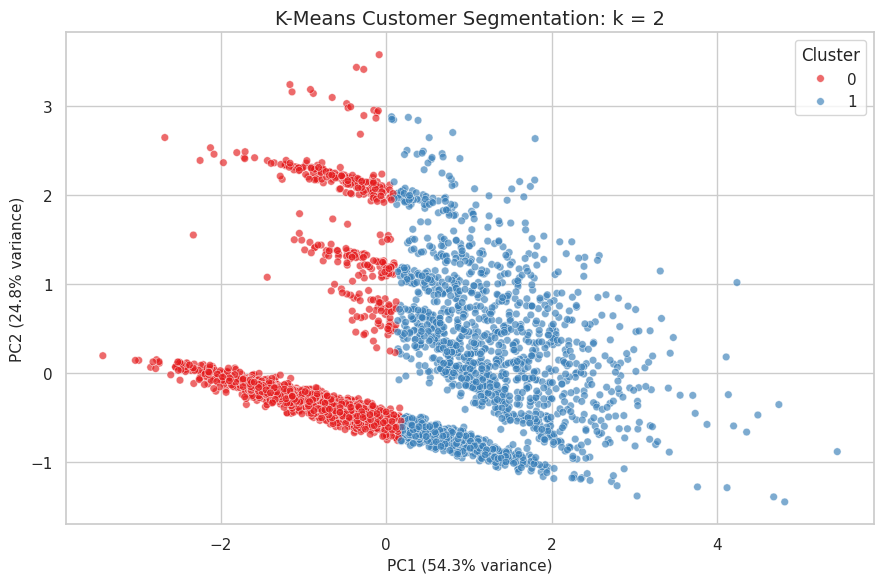

In [105]:
# PCA VISUALISATION FOR k = 2


pca_k2 = PCA(n_components=2, random_state=RANDOM_STATE)
pca_values_k2 = pca_k2.fit_transform(X)

pca_df_k2 = pd.DataFrame(
    pca_values_k2,
    columns=["PC1", "PC2"]
)

pca_df_k2["Cluster"] = labels_k2

explained_k2 = pca_k2.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df_k2,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=30
)

plt.title("K-Means Customer Segmentation: k = 2")
plt.xlabel(f"PC1 ({explained_k2[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_k2[1]:.1f}% variance)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.savefig(
    os.path.join(KMEANS_DIR, "kmeans_pca_k2.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

K means for k=3

In [106]:
K = 3

kmeans_k3 = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=30,
    max_iter=500,
    random_state=RANDOM_STATE
)

labels_k3 = kmeans_k3.fit_predict(X)

# Internal evaluation metrics
silhouette_k3 = silhouette_score(X, labels_k3)
calinski_k3 = calinski_harabasz_score(X, labels_k3)
davies_k3 = davies_bouldin_score(X, labels_k3)

# Cluster count and percentage table
cluster_sizes_k3 = pd.DataFrame({
    "Cluster": np.arange(K),
    "Customer_Count": np.bincount(labels_k3, minlength=K)
})

cluster_sizes_k3["Customer_Percentage"] = (
    cluster_sizes_k3["Customer_Count"] / len(X) * 100
)

print("=" * 60)
print("K-MEANS RESULTS FOR k = 3")
print("=" * 60)
print(f"Inertia:                 {kmeans_k3.inertia_:.2f}")
print(f"Silhouette Score:        {silhouette_k3:.4f}  (higher is better)")
print(f"Calinski-Harabasz Score: {calinski_k3:.2f}  (higher is better)")
print(f"Davies-Bouldin Score:    {davies_k3:.4f}  (lower is better)")

print("\nCluster sizes:")
display(cluster_sizes_k3.round(2))

K-MEANS RESULTS FOR k = 3
Inertia:                 5314.67
Silhouette Score:        0.3704  (higher is better)
Calinski-Harabasz Score: 2489.64  (higher is better)
Davies-Bouldin Score:    1.0282  (lower is better)

Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,0,727,16.76
1,1,2189,50.46
2,2,1422,32.78


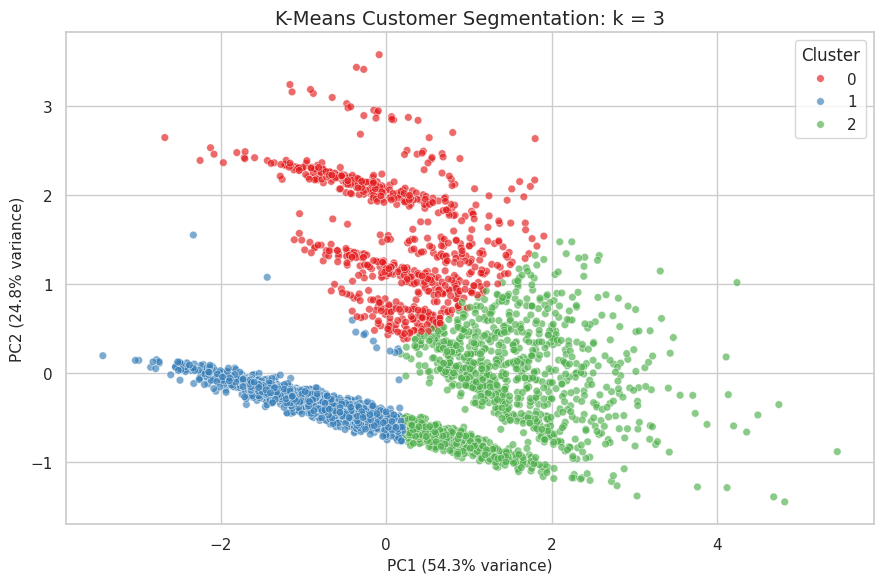

In [107]:
#  PCA VISUALISATION FOR k = 3

pca_k3 = PCA(n_components=2, random_state=RANDOM_STATE)
pca_values_k3 = pca_k3.fit_transform(X)

pca_df_k3 = pd.DataFrame(
    pca_values_k3,
    columns=["PC1", "PC2"]
)

pca_df_k3["Cluster"] = labels_k3
explained_k3 = pca_k3.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df_k3,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=30
)

plt.title("K-Means Customer Segmentation: k = 3")
plt.xlabel(f"PC1 ({explained_k3[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_k3[1]:.1f}% variance)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.savefig(
    os.path.join(KMEANS_DIR, "kmeans_pca_k3.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

K means clustering for k=4

In [108]:
K = 4

kmeans_k4 = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=30,
    max_iter=500,
    random_state=RANDOM_STATE
)

labels_k4 = kmeans_k4.fit_predict(X)

# Internal evaluation metrics
silhouette_k4 = silhouette_score(X, labels_k4)
calinski_k4 = calinski_harabasz_score(X, labels_k4)
davies_k4 = davies_bouldin_score(X, labels_k4)

# Cluster count and percentage table
cluster_sizes_k4 = pd.DataFrame({
    "Cluster": np.arange(K),
    "Customer_Count": np.bincount(labels_k4, minlength=K)
})

cluster_sizes_k4["Customer_Percentage"] = (
    cluster_sizes_k4["Customer_Count"] / len(X) * 100
)

print("=" * 60)
print("K-MEANS RESULTS FOR k = 4")
print("=" * 60)
print(f"Inertia:                 {kmeans_k4.inertia_:.2f}")
print(f"Silhouette Score:        {silhouette_k4:.4f}  (higher is better)")
print(f"Calinski-Harabasz Score: {calinski_k4:.2f}  (higher is better)")
print(f"Davies-Bouldin Score:    {davies_k4:.4f}  (lower is better)")

print("\nCluster sizes:")
display(cluster_sizes_k4.round(2))

K-MEANS RESULTS FOR k = 4
Inertia:                 4392.80
Silhouette Score:        0.2887  (higher is better)
Calinski-Harabasz Score: 2310.79  (higher is better)
Davies-Bouldin Score:    1.1039  (lower is better)

Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,0,1370,31.58
1,1,896,20.65
2,2,704,16.23
3,3,1368,31.54


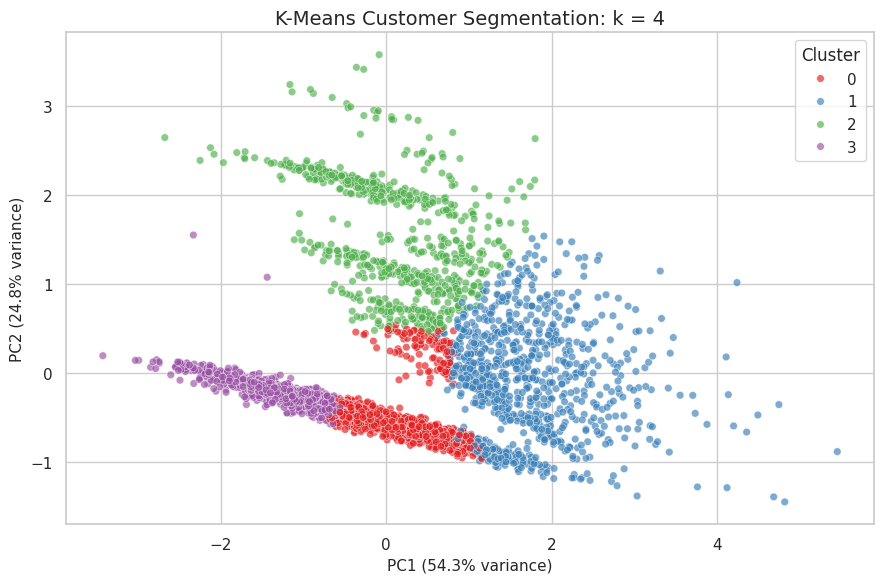

In [109]:

# PCA VISUALISATION FOR k = 4


pca_k4 = PCA(n_components=2, random_state=RANDOM_STATE)
pca_values_k4 = pca_k4.fit_transform(X)

pca_df_k4 = pd.DataFrame(
    pca_values_k4,
    columns=["PC1", "PC2"]
)

pca_df_k4["Cluster"] = labels_k4
explained_k4 = pca_k4.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df_k4,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=30
)

plt.title("K-Means Customer Segmentation: k = 4")
plt.xlabel(f"PC1 ({explained_k4[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_k4[1]:.1f}% variance)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.savefig(
    os.path.join(KMEANS_DIR, "kmeans_pca_k4.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

K means Clustering for K=5

In [110]:


K = 5

kmeans_k5 = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=30,
    max_iter=500,
    random_state=RANDOM_STATE
)

labels_k5 = kmeans_k5.fit_predict(X)

# Internal evaluation metrics
silhouette_k5 = silhouette_score(X, labels_k5)
calinski_k5 = calinski_harabasz_score(X, labels_k5)
davies_k5 = davies_bouldin_score(X, labels_k5)

# Cluster count and percentage table
cluster_sizes_k5 = pd.DataFrame({
    "Cluster": np.arange(K),
    "Customer_Count": np.bincount(labels_k5, minlength=K)
})

cluster_sizes_k5["Customer_Percentage"] = (
    cluster_sizes_k5["Customer_Count"] / len(X) * 100
)

print("=" * 60)
print("K-MEANS RESULTS FOR k = 5")
print("=" * 60)
print(f"Inertia:                 {kmeans_k5.inertia_:.2f}")
print(f"Silhouette Score:        {silhouette_k5:.4f}  (higher is better)")
print(f"Calinski-Harabasz Score: {calinski_k5:.2f}  (higher is better)")
print(f"Davies-Bouldin Score:    {davies_k5:.4f}  (lower is better)")

print("\nCluster sizes:")
display(cluster_sizes_k5.round(2))

K-MEANS RESULTS FOR k = 5
Inertia:                 3916.55
Silhouette Score:        0.2826  (higher is better)
Calinski-Harabasz Score: 2075.11  (higher is better)
Davies-Bouldin Score:    1.2076  (lower is better)

Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,0,675,15.56
1,1,1280,29.51
2,2,1351,31.14
3,3,395,9.11
4,4,637,14.68


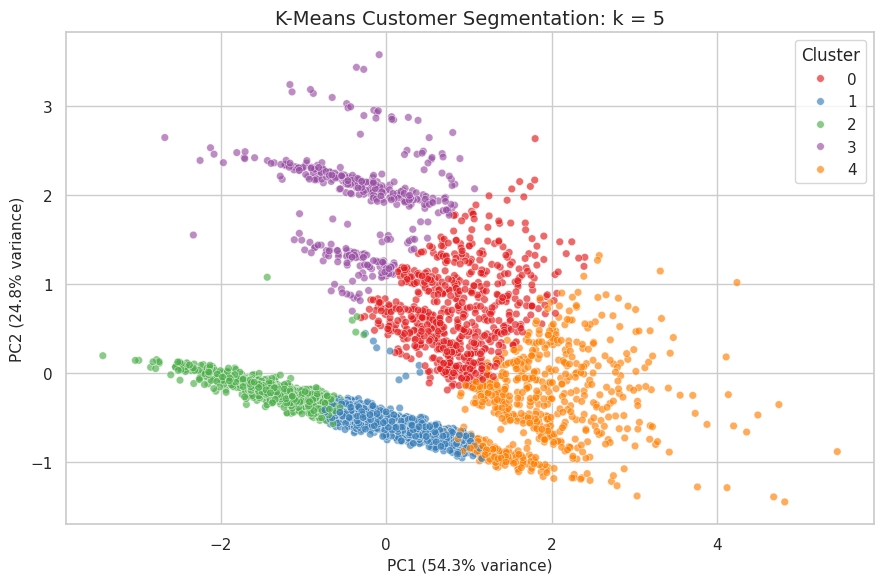

In [111]:

#PCA VISUALISATION FOR k = 5

pca_k5 = PCA(n_components=2, random_state=RANDOM_STATE)
pca_values_k5 = pca_k5.fit_transform(X)

pca_df_k5 = pd.DataFrame(
    pca_values_k5,
    columns=["PC1", "PC2"]
)

pca_df_k5["Cluster"] = labels_k5
explained_k5 = pca_k5.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df_k5,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=30
)

plt.title("K-Means Customer Segmentation: k = 5")
plt.xlabel(f"PC1 ({explained_k5[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_k5[1]:.1f}% variance)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.savefig(
    os.path.join(KMEANS_DIR, "kmeans_pca_k5.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Combined k-value result

In [112]:


k_comparison = pd.DataFrame({
    "k": [2, 3, 4, 5],
    "Inertia": [
        kmeans_k2.inertia_,
        kmeans_k3.inertia_,
        kmeans_k4.inertia_,
        kmeans_k5.inertia_
    ],
    "Silhouette_Score": [
        silhouette_k2,
        silhouette_k3,
        silhouette_k4,
        silhouette_k5
    ],
    "Calinski_Harabasz_Score": [
        calinski_k2,
        calinski_k3,
        calinski_k4,
        calinski_k5
    ],
    "Davies_Bouldin_Score": [
        davies_k2,
        davies_k3,
        davies_k4,
        davies_k5
    ],
    "Smallest_Cluster_Size": [
        cluster_sizes_k2["Customer_Count"].min(),
        cluster_sizes_k3["Customer_Count"].min(),
        cluster_sizes_k4["Customer_Count"].min(),
        cluster_sizes_k5["Customer_Count"].min()
    ],
    "Smallest_Cluster_Percentage": [
        cluster_sizes_k2["Customer_Percentage"].min(),
        cluster_sizes_k3["Customer_Percentage"].min(),
        cluster_sizes_k4["Customer_Percentage"].min(),
        cluster_sizes_k5["Customer_Percentage"].min()
    ]
})

k_comparison = k_comparison.round(4)

display(k_comparison)

comparison_path = os.path.join(
    KMEANS_DIR,
    "kmeans_k2_to_k5_comparison.csv"
)

k_comparison.to_csv(comparison_path, index=False)

print(f"Saved successfully: {comparison_path}")

,k,Inertia,Silhouette_Score,Calinski_Harabasz_Score,Davies_Bouldin_Score,Smallest_Cluster_Size,Smallest_Cluster_Percentage
0,2,7250.9315,0.3341,2492.6114,1.1979,1838,42.3698
1,3,5314.6702,0.3704,2489.6411,1.0282,727,16.7589
2,4,4392.8036,0.2887,2310.7907,1.1039,704,16.2287
3,5,3916.5518,0.2826,2075.1111,1.2076,395,9.1056


Saved successfully: /content/drive/MyDrive/ML Project/project_outputs/kmeans/kmeans_k2_to_k5_comparison.csv


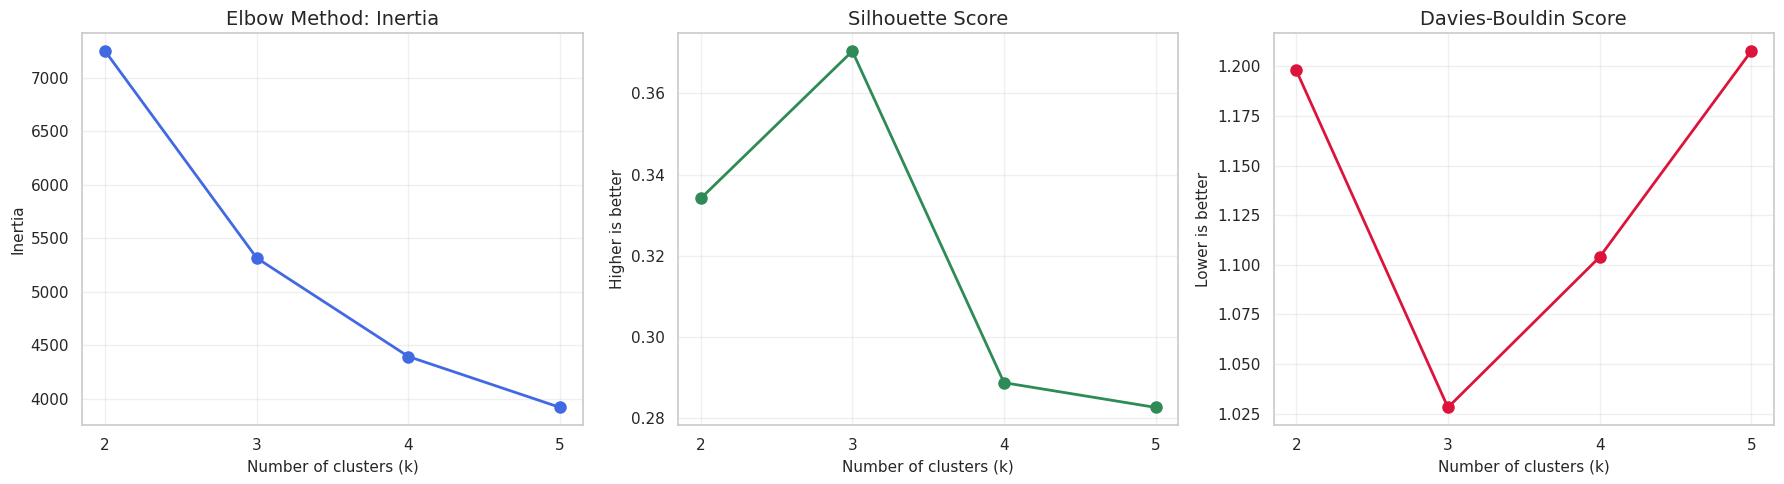

Saved successfully: /content/drive/MyDrive/ML Project/project_outputs/kmeans/kmeans_k_selection_metrics.png


In [113]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Elbow / inertia
axes[0].plot(
    k_comparison["k"],
    k_comparison["Inertia"],
    marker="o",
    markersize=8,
    linewidth=2,
    color="royalblue"
)
axes[0].set_title("Elbow Method: Inertia")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks([2, 3, 4, 5])
axes[0].grid(alpha=0.3)

# Silhouette
axes[1].plot(
    k_comparison["k"],
    k_comparison["Silhouette_Score"],
    marker="o",
    markersize=8,
    linewidth=2,
    color="seagreen"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Higher is better")
axes[1].set_xticks([2, 3, 4, 5])
axes[1].grid(alpha=0.3)

# Davies-Bouldin
axes[2].plot(
    k_comparison["k"],
    k_comparison["Davies_Bouldin_Score"],
    marker="o",
    markersize=8,
    linewidth=2,
    color="crimson"
)
axes[2].set_title("Davies-Bouldin Score")
axes[2].set_xlabel("Number of clusters (k)")
axes[2].set_ylabel("Lower is better")
axes[2].set_xticks([2, 3, 4, 5])
axes[2].grid(alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    KMEANS_DIR,
    "kmeans_k_selection_metrics.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved successfully: {plot_path}")

K means clustering evaluated for K=2,3,4,5 evaluating inertia, silhoute score, Calinski-Harabasz Score, Davies-Bouldin Score, and cluster-size balance. The final solution selected as k= 3 as it achieved the highest Silhouette Score (0.3704) and the lowest Davies-Bouldin Score (1.0282). It also retained a sufficiently large smallest segment of 727 customers (16.76%), supporting practical business interpretation

Create final dataset

In [114]:
#CREATE FINAL k = 3 CUSTOMER SEGMENT DATASET


FINAL_K = 3

# Checks before attaching labels
assert len(customer_all) == 4338
assert len(labels_k3) == 4338
assert customer_all["CustomerID"].is_unique
assert np.array_equal(
    customer_all["CustomerID"].to_numpy(),
    X_all["CustomerID"].to_numpy()
), "customer_all row order does not match X_all row order."

# Copy full original-scale customer profiles
customer_clusters = customer_all.copy().reset_index(drop=True)

# Add K-Means labels from the selected k = 3 model
customer_clusters["Cluster"] = labels_k3.astype(int)

# Final validation
assert customer_clusters["Cluster"].between(0, FINAL_K - 1).all()
assert customer_clusters["CustomerID"].is_unique

cluster_size_check = (
    customer_clusters["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Customer_Count")
)

cluster_size_check["Customer_Percentage"] = (
    cluster_size_check["Customer_Count"] / len(customer_clusters) * 100
).round(2)

print("Final k = 3 customer-segment dataset created successfully.")
print("Shape:", customer_clusters.shape)

display(cluster_size_check)
display(customer_clusters.head())

Final k = 3 customer-segment dataset created successfully.
Shape: (4338, 16)


,Cluster,Customer_Count,Customer_Percentage
0,0,727,16.76
1,1,2189,50.46
2,2,1422,32.78


,CustomerID,FirstPurchaseDate,LastPurchaseDate,InvoiceFrequency,TotalRevenue,TotalQuantity,RecencyDays,CustomerTenureDays,AvgRevenuePerInvoice,AvgQuantityPerInvoice,UniqueProducts,PrimaryCountry,CancellationInvoices,TotalInvoicesObserved,CancellationRate,Cluster
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,326,0,77183.600000,74215.000000,1,United Kingdom,1,2,0.5,0
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,2458,2,365,615.714286,351.142857,103,Iceland,0,7,0.0,2
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,2341,75,282,449.310000,585.250000,21,Finland,0,4,0.0,1
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,631,19,0,1757.550000,631.000000,72,Italy,0,1,0.0,2
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,310,0,334.400000,197.000000,16,Norway,0,1,0.0,1


In [115]:
# PROFILE k = 3 CLUSTERS IN ORIGINAL UNITS


profile_features = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationRate",
    "CustomerTenureDays"
]

# Customer count and percentage
cluster_counts = (
    customer_clusters
    .groupby("Cluster")
    .size()
    .rename("Customer_Count")
)

cluster_percentages = (
    customer_clusters
    .groupby("Cluster")
    .size()
    .div(len(customer_clusters))
    .mul(100)
    .rename("Customer_Percentage")
)

# Mean profile values
cluster_profile_mean = (
    customer_clusters
    .groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

# Median profile values: more resistant to high-value wholesale outliers
cluster_profile_median = (
    customer_clusters
    .groupby("Cluster")[profile_features]
    .median()
    .round(2)
)

cluster_profile_summary = pd.concat(
    [cluster_counts, cluster_percentages, cluster_profile_mean],
    axis=1
).round(2)

print("Mean cluster profiles — original-scale customer measures:")
display(cluster_profile_summary)

print("\nMedian cluster profiles — original-scale customer measures:")
display(cluster_profile_median)

# Export
cluster_profile_summary.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_cluster_profile_means.csv")
)

cluster_profile_median.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_cluster_profile_medians.csv")
)

print("\nSaved profile tables to:", KMEANS_DIR)

Mean cluster profiles — original-scale customer measures:


,Customer_Count,Customer_Percentage,RecencyDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationRate,CustomerTenureDays
Cluster,,,,,,,,,,,
0,727,16.76,111.56,2.54,1186.40,690.08,39.58,553.20,344.36,0.4,111.27
1,2189,50.46,128.89,1.65,453.70,288.86,26.13,297.19,187.20,0.0,56.12
2,1422,32.78,26.85,9.19,4961.84,2836.72,126.75,538.41,309.05,0.12,254.67



Median cluster profiles — original-scale customer measures:


,RecencyDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationRate,CustomerTenureDays
Cluster,,,,,,,,,
0,73.0,2.0,696.68,375.0,29.0,324.81,175.00,0.4,86.0
1,88.0,1.0,336.96,190.0,20.0,225.77,128.00,0.0,0.0
2,16.0,6.0,2292.40,1358.5,99.0,356.12,209.24,0.1,277.0



Saved profile tables to: /content/drive/MyDrive/ML Project/project_outputs/kmeans


Identify the segments properly

In [116]:

# RANK CLUSTERS FOR SEGMENT NAMING


segment_ranking = cluster_profile_median[
    [
        "RecencyDays",
        "InvoiceFrequency",
        "TotalRevenue",
        "UniqueProducts",
        "CancellationRate"
    ]
].copy()

# Rank 1 means highest value for each feature
for column in segment_ranking.columns:
    segment_ranking[f"{column}_Rank_Highest"] = (
        segment_ranking[column]
        .rank(ascending=False, method="dense")
        .astype(int)
    )

print("Median values and rank, where 1 = highest:")
display(segment_ranking)

print("\nInterpretation guide:")
print("- Lowest RecencyDays = most recently active customers.")
print("- Highest InvoiceFrequency = most frequent purchasers.")
print("- Highest TotalRevenue = highest-value customers.")
print("- Highest UniqueProducts = broadest product variety.")
print("- Highest CancellationRate = customers with more cancellations/returns.")

Median values and rank, where 1 = highest:


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate,RecencyDays_Rank_Highest,InvoiceFrequency_Rank_Highest,TotalRevenue_Rank_Highest,UniqueProducts_Rank_Highest,CancellationRate_Rank_Highest
Cluster,,,,,,,,,,
0,73.0,2.0,696.68,29.0,0.4,2,2,2,2,1
1,88.0,1.0,336.96,20.0,0.0,1,3,3,3,3
2,16.0,6.0,2292.40,99.0,0.1,3,1,1,1,2



Interpretation guide:
- Lowest RecencyDays = most recently active customers.
- Highest InvoiceFrequency = most frequent purchasers.
- Highest TotalRevenue = highest-value customers.
- Highest UniqueProducts = broadest product variety.
- Highest CancellationRate = customers with more cancellations/returns.


ASSIGN FINAL EVIDENCE-BASED SEGMENT NAMES

In [117]:

#  ASSIGN FINAL EVIDENCE-BASED SEGMENT NAMES


cluster_name_map = {
    0: "At-Risk / High-Cancellation Customers",
    1: "Low-Engagement Lapsed Customers",
    2: "High-Value Loyal Customers"
}

customer_clusters["Segment"] = (
    customer_clusters["Cluster"]
    .map(cluster_name_map)
)

assert customer_clusters["Segment"].notna().all()

segment_size_summary = (
    customer_clusters
    .groupby(["Cluster", "Segment"])
    .size()
    .reset_index(name="Customer_Count")
)

segment_size_summary["Customer_Percentage"] = (
    segment_size_summary["Customer_Count"]
    / len(customer_clusters)
    * 100
).round(2)

display(segment_size_summary)

segment_size_summary.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_segment_sizes.csv"),
    index=False
)

,Cluster,Segment,Customer_Count,Customer_Percentage
0,0,At-Risk / High-Cancellation Customers,727,16.76
1,1,Low-Engagement Lapsed Customers,2189,50.46
2,2,High-Value Loyal Customers,1422,32.78


Final business profile

In [118]:

# FINAL BUSINESS SEGMENT PROFILE


final_segment_profile = (
    customer_clusters
    .groupby(["Cluster", "Segment"])
    .agg(
        Customers=("CustomerID", "count"),
        Customer_Percentage=(
            "CustomerID",
            lambda customers: len(customers) / len(customer_clusters) * 100
        ),
        Median_Recency_Days=("RecencyDays", "median"),
        Median_Invoices=("InvoiceFrequency", "median"),
        Median_Revenue=("TotalRevenue", "median"),
        Median_Quantity=("TotalQuantity", "median"),
        Median_Unique_Products=("UniqueProducts", "median"),
        Median_Revenue_Per_Invoice=("AvgRevenuePerInvoice", "median"),
        Median_Cancellation_Rate=("CancellationRate", "median"),
        Median_Tenure_Days=("CustomerTenureDays", "median"),
        Mean_Revenue=("TotalRevenue", "mean"),
        Mean_Invoices=("InvoiceFrequency", "mean")
    )
    .reset_index()
)

# Reporting-friendly percentage format
final_segment_profile["Median_Cancellation_Rate (%)"] = (
    final_segment_profile["Median_Cancellation_Rate"] * 100
).round(1)

final_segment_profile = (
    final_segment_profile
    .drop(columns="Median_Cancellation_Rate")
    .round(2)
)

display(final_segment_profile)

final_segment_profile.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_business_segment_profile.csv"),
    index=False
)

,Cluster,Segment,Customers,Customer_Percentage,Median_Recency_Days,Median_Invoices,Median_Revenue,Median_Quantity,Median_Unique_Products,Median_Revenue_Per_Invoice,Median_Tenure_Days,Mean_Revenue,Mean_Invoices,Median_Cancellation_Rate (%)
0,0,At-Risk / High-Cancellation Customers,727,16.76,73.0,2.0,696.68,375.0,29.0,324.81,86.0,1186.40,2.54,40.0
1,1,Low-Engagement Lapsed Customers,2189,50.46,88.0,1.0,336.96,190.0,20.0,225.77,0.0,453.70,1.65,0.0
2,2,High-Value Loyal Customers,1422,32.78,16.0,6.0,2292.40,1358.5,99.0,356.12,277.0,4961.84,9.19,10.0


TOP CUSTOMER COUNTRIES WITHIN EACH SEGMENT

In [119]:

# TOP CUSTOMER COUNTRIES WITHIN EACH SEGMENT


country_profile = (
    customer_clusters
    .groupby(["Cluster", "Segment", "PrimaryCountry"])
    .size()
    .reset_index(name="Customer_Count")
)

country_profile["Segment_Total"] = (
    country_profile
    .groupby("Cluster")["Customer_Count"]
    .transform("sum")
)

country_profile["Segment_Country_Percentage"] = (
    country_profile["Customer_Count"]
    / country_profile["Segment_Total"]
    * 100
).round(2)

top_countries_by_segment = (
    country_profile
    .sort_values(
        ["Cluster", "Customer_Count"],
        ascending=[True, False]
    )
    .groupby("Cluster", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

display(top_countries_by_segment)

top_countries_by_segment.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_top_countries_by_segment.csv"),
    index=False
)

,Cluster,Segment,PrimaryCountry,Customer_Count,Segment_Total,Segment_Country_Percentage
0,0,At-Risk / High-Cancellation Customers,United Kingdom,646,727,88.86
1,0,At-Risk / High-Cancellation Customers,Germany,22,727,3.03
2,0,At-Risk / High-Cancellation Customers,France,12,727,1.65
3,0,At-Risk / High-Cancellation Customers,Switzerland,7,727,0.96
4,0,At-Risk / High-Cancellation Customers,Spain,5,727,0.69
5,1,Low-Engagement Lapsed Customers,United Kingdom,2004,2189,91.55
6,1,Low-Engagement Lapsed Customers,France,39,2189,1.78
7,1,Low-Engagement Lapsed Customers,Germany,33,2189,1.51
8,1,Low-Engagement Lapsed Customers,Spain,15,2189,0.69
9,1,Low-Engagement Lapsed Customers,Belgium,9,2189,0.41


Business action table

In [120]:

#  SEGMENT-SPECIFIC BUSINESS ACTIONS


segment_actions = pd.DataFrame({
    "Cluster": [0, 1, 2],
    "Segment": [
        "At-Risk / High-Cancellation Customers",
        "Low-Engagement Lapsed Customers",
        "High-Value Loyal Customers"
    ],
    "Primary_Business_Interpretation": [
        "Moderate spend but low recent activity and the highest cancellation behaviour.",
        "Largest segment, typically one completed purchase, low spend, and no repeat-purchase tenure.",
        "Recent, repeat, high-spending customers with broad product purchasing behaviour."
    ],
    "Recommended_Action": [
        "Analyse cancellation reasons; use post-purchase support, delivery clarity, and carefully targeted retention offers.",
        "Run low-cost reactivation campaigns, such as reminder emails, first-repeat-purchase discounts, and popular-product recommendations.",
        "Prioritize loyalty rewards, VIP communication, early access, premium bundles, and personalized cross-selling."
    ],
    "Association_Rule_Use": [
        "Use bundles cautiously; prioritize products with low cancellation or return risk.",
        "Use simple, popular product bundles to encourage a second purchase.",
        "Use stronger segment-specific association rules for personalized multi-item bundles and cross-selling."
    ]
})

display(segment_actions)

segment_actions.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_segment_business_actions.csv"),
    index=False
)

,Cluster,Segment,Primary_Business_Interpretation,Recommended_Action,Association_Rule_Use
0,0,At-Risk / High-Cancellation Customers,Moderate spend but low recent activity and the...,Analyse cancellation reasons; use post-purchas...,Use bundles cautiously; prioritize products wi...
1,1,Low-Engagement Lapsed Customers,"Largest segment, typically one completed purch...","Run low-cost reactivation campaigns, such as r...","Use simple, popular product bundles to encoura..."
2,2,High-Value Loyal Customers,"Recent, repeat, high-spending customers with b...","Prioritize loyalty rewards, VIP communication,...",Use stronger segment-specific association rule...


 Segment visualizations

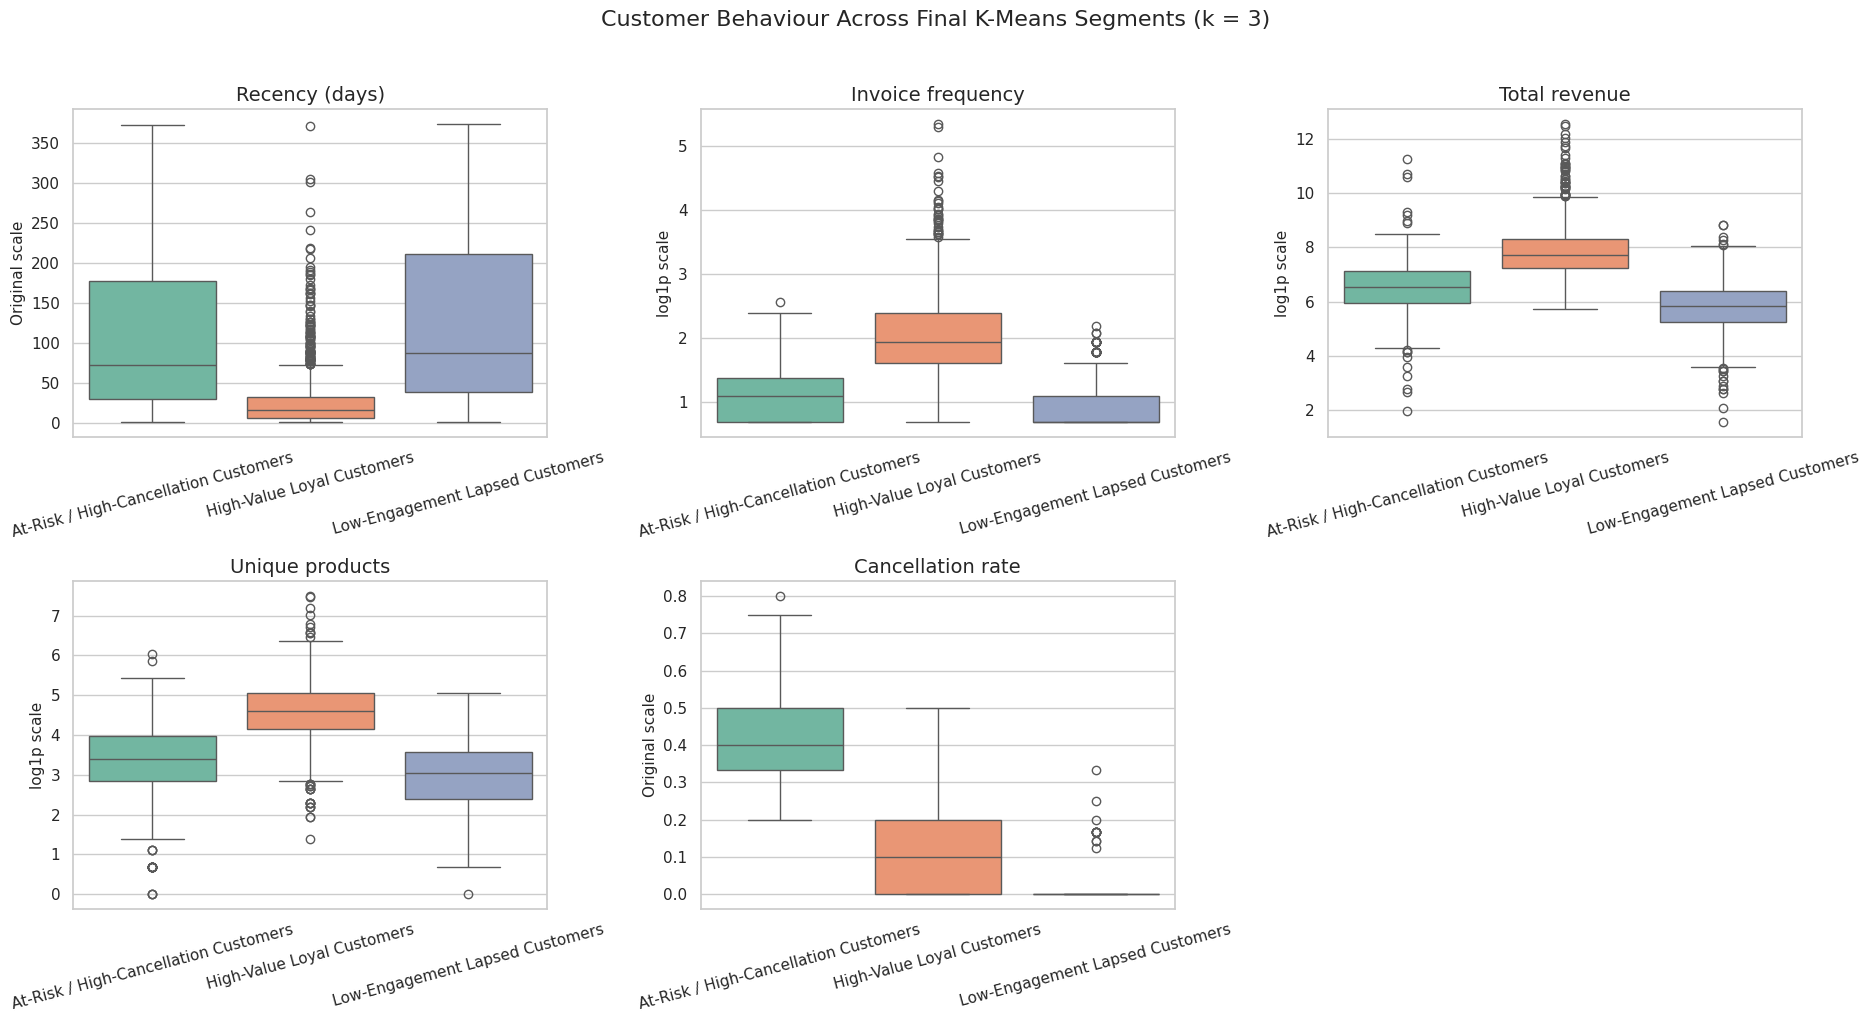

In [121]:


plot_data = customer_clusters.copy()

# Log displays are used for heavily right-skewed purchase measures.
plot_data["Log_InvoiceFrequency"] = np.log1p(plot_data["InvoiceFrequency"])
plot_data["Log_TotalRevenue"] = np.log1p(plot_data["TotalRevenue"])
plot_data["Log_UniqueProducts"] = np.log1p(plot_data["UniqueProducts"])

plot_specs = [
    ("RecencyDays", "Recency (days)", "Original scale"),
    ("Log_InvoiceFrequency", "Invoice frequency", "log1p scale"),
    ("Log_TotalRevenue", "Total revenue", "log1p scale"),
    ("Log_UniqueProducts", "Unique products", "log1p scale"),
    ("CancellationRate", "Cancellation rate", "Original scale")
]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
axes = axes.flatten()

for ax, (column, title, scale_note) in zip(axes, plot_specs):
    sns.boxplot(
        data=plot_data,
        x="Segment",
        y=column,
        hue="Segment",
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(scale_note)
    ax.tick_params(axis="x", rotation=15)

# Remove unused sixth subplot
axes[-1].axis("off")

plt.suptitle(
    "Customer Behaviour Across Final K-Means Segments (k = 3)",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    os.path.join(KMEANS_DIR, "final_k3_segment_boxplots.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PCA visualization

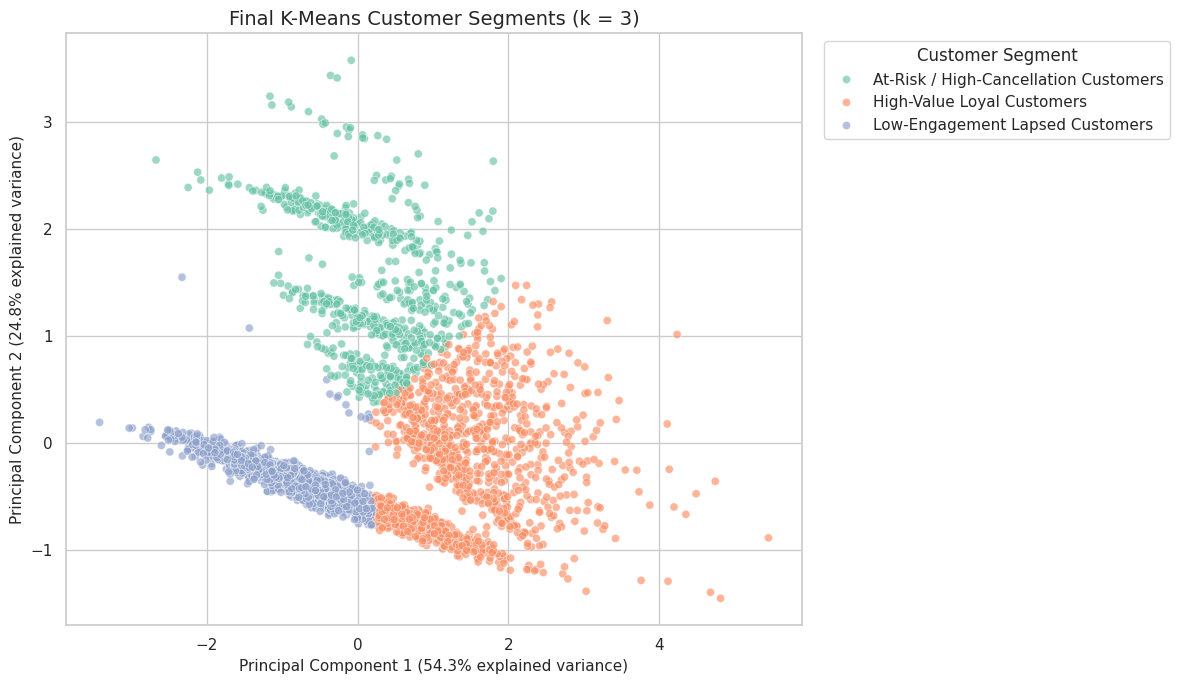

In [122]:


from sklearn.decomposition import PCA

pca_final = PCA(n_components=2, random_state=RANDOM_STATE)

pca_coordinates = pca_final.fit_transform(X)

pca_final_df = pd.DataFrame(
    pca_coordinates,
    columns=["PC1", "PC2"]
)

pca_final_df["Cluster"] = labels_k3
pca_final_df["Segment"] = (
    pca_final_df["Cluster"]
    .map(cluster_name_map)
)

explained_variance = pca_final.explained_variance_ratio_ * 100

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=pca_final_df,
    x="PC1",
    y="PC2",
    hue="Segment",
    palette="Set2",
    alpha=0.65,
    s=35
)

plt.title("Final K-Means Customer Segments (k = 3)")
plt.xlabel(
    f"Principal Component 1 ({explained_variance[0]:.1f}% explained variance)"
)
plt.ylabel(
    f"Principal Component 2 ({explained_variance[1]:.1f}% explained variance)"
)
plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(KMEANS_DIR, "final_k3_pca_named_segments.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Stability check

In [123]:

from sklearn.metrics import adjusted_rand_score, silhouette_score

seed_values = [0, 7, 21, 42, 77, 100, 202, 999]

stability_results = []

for seed in seed_values:

    seed_model = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=30,
        max_iter=500,
        random_state=seed
    )

    seed_labels = seed_model.fit_predict(X)

    stability_results.append({
        "Random_Seed": seed,
        "Inertia": seed_model.inertia_,
        "Silhouette_Score": silhouette_score(X, seed_labels),
        "ARI_vs_Reference_Seed_42": adjusted_rand_score(
            labels_k3,
            seed_labels
        )
    })

stability_results = pd.DataFrame(stability_results).round(4)

display(stability_results)

print(
    "Mean silhouette score:",
    round(stability_results["Silhouette_Score"].mean(), 4)
)

print(
    "Minimum ARI against reference:",
    round(stability_results["ARI_vs_Reference_Seed_42"].min(), 4)
)

print(
    "Mean ARI against reference:",
    round(stability_results["ARI_vs_Reference_Seed_42"].mean(), 4)
)

stability_results.to_csv(
    os.path.join(KMEANS_DIR, "final_k3_seed_stability.csv"),
    index=False
)

,Random_Seed,Inertia,Silhouette_Score,ARI_vs_Reference_Seed_42
0,0,5314.6741,0.3704,1.0000
1,7,5314.6560,0.3706,0.9957
2,21,5314.6723,0.3704,1.0000
3,42,5314.6702,0.3704,1.0000
4,77,5314.6733,0.3704,0.9973
5,100,5314.6702,0.3704,1.0000
6,202,5314.6560,0.3706,0.9957
7,999,5314.6702,0.3704,1.0000


Mean silhouette score: 0.3704
Minimum ARI against reference: 0.9957
Mean ARI against reference: 0.9986


In [124]:

export_columns = [
    "CustomerID",
    "Cluster",
    "Segment",
    "PrimaryCountry",
    "FirstPurchaseDate",
    "LastPurchaseDate",
    "RecencyDays",
    "CustomerTenureDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationInvoices",
    "TotalInvoicesObserved",
    "CancellationRate"
]

final_customer_segments = (
    customer_clusters[export_columns]
    .sort_values(["Cluster", "CustomerID"])
    .reset_index(drop=True)
)

final_export_path = os.path.join(
    KMEANS_DIR,
    "final_k3_customer_segment_assignments.csv"
)

final_customer_segments.to_csv(final_export_path, index=False)

print("Final assignment file saved to:")
print(final_export_path)

display(final_customer_segments.head(10))

Final assignment file saved to:
/content/drive/MyDrive/ML Project/project_outputs/kmeans/final_k3_customer_segment_assignments.csv


,CustomerID,Cluster,Segment,PrimaryCountry,FirstPurchaseDate,LastPurchaseDate,RecencyDays,CustomerTenureDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationInvoices,TotalInvoicesObserved,CancellationRate
0,12346,0,At-Risk / High-Cancellation Customers,United Kingdom,2011-01-18 10:01:00,2011-01-18 10:01:00,326,0,1,77183.60,74215,1,77183.600,74215.000000,1,2,0.5
1,12365,0,At-Risk / High-Cancellation Customers,Cyprus,2011-02-21 13:51:00,2011-02-21 14:04:00,291,0,2,641.38,174,21,320.690,87.000000,1,3,0.333333
2,12375,0,At-Risk / High-Cancellation Customers,Finland,2011-09-02 14:23:00,2011-11-29 10:36:00,11,87,2,457.50,178,13,228.750,89.000000,1,3,0.333333
3,12379,0,At-Risk / High-Cancellation Customers,Belgium,2011-06-22 16:32:00,2011-09-19 10:09:00,82,88,2,852.24,407,38,426.120,203.500000,1,3,0.333333
4,12384,0,At-Risk / High-Cancellation Customers,Switzerland,2011-08-10 11:23:00,2011-11-11 08:39:00,29,92,2,585.27,126,25,292.635,63.000000,1,3,0.333333
5,12403,0,At-Risk / High-Cancellation Customers,Denmark,2011-10-21 10:51:00,2011-10-21 10:51:00,50,0,1,427.70,96,4,427.700,96.000000,1,2,0.5
6,12406,0,At-Risk / High-Cancellation Customers,Denmark,2011-06-09 10:23:00,2011-11-17 19:22:00,22,161,2,3415.30,1818,92,1707.650,909.000000,1,3,0.333333
7,12408,0,At-Risk / High-Cancellation Customers,Belgium,2011-03-24 14:46:00,2011-11-07 12:27:00,33,227,5,2888.55,1409,80,577.710,281.800000,4,9,0.444444
8,12409,0,At-Risk / High-Cancellation Customers,Switzerland,2011-06-10 12:19:00,2011-09-22 10:38:00,79,103,3,11072.67,5551,91,3690.890,1850.333333,4,7,0.571429
9,12410,0,At-Risk / High-Cancellation Customers,Switzerland,2011-02-04 10:38:00,2011-02-04 10:39:00,309,0,2,693.33,211,25,346.665,105.500000,1,3,0.333333


## K-Means clustering with
𝑘
=
3
k=3 produced three actionable customer segments. The High-Value Loyal Customers segment comprised 32.78% of customers and had the strongest median behavioural profile: 16 days recency, six invoices, 2,292.40 total revenue, 99 unique products, and 277 days tenure. The Low-Engagement Lapsed Customers segment was the largest group at 50.46%, characterized by a median of one invoice, 336.96 revenue, 88 days recency, and zero tenure. The At-Risk / High-Cancellation Customers segment represented 16.76% of customers and showed the highest median cancellation rate of 40%, indicating a need for service-quality and retention interventions

# AGGLOMERATIVE / HIERARCHICAL CLUSTERING - IT24101861 Gamage K.T.P

In [125]:


from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
import warnings

warnings.filterwarnings("ignore")

# Output directory dedicated to hierarchical clustering
HIERARCHICAL_DIR = os.path.join(
    KMEANS_DIR,
    "hierarchical_clustering"
)

os.makedirs(HIERARCHICAL_DIR, exist_ok=True)

# Use the same preprocessed five-feature matrix as K-Means.
# X is confirmed to be 4338 rows x 5 columns.
X_hierarchical = X.copy()

# Ensure numeric matrix and expected dimensions
assert isinstance(X_hierarchical, pd.DataFrame)
assert X_hierarchical.shape == (4338, 5)
assert list(X_hierarchical.columns) == [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]
assert np.isfinite(X_hierarchical.to_numpy()).all()
assert not X_hierarchical.isna().any().any()

# Confirm that customer data and X use the same row order
assert len(customer_all) == len(X_hierarchical)
assert np.array_equal(
    customer_all["CustomerID"].to_numpy(),
    X_all["CustomerID"].to_numpy()
), "Customer order mismatch between customer_all and X_all."

print("Hierarchical clustering setup completed.")
print("Clustering matrix shape:", X_hierarchical.shape)
print("Features used:", X_hierarchical.columns.tolist())
print("Output folder:", HIERARCHICAL_DIR)

Hierarchical clustering setup completed.
Clustering matrix shape: (4338, 5)
Features used: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']
Output folder: /content/drive/MyDrive/ML Project/project_outputs/kmeans/hierarchical_clustering


Baseline plus three variations

In [126]:


N_CLUSTERS = 3
SILHOUETTE_SAMPLE_SIZE = 1500
RANDOM_STATE = 42

# One baseline and three linkage variations
hierarchical_configurations = {
    "Baseline: Ward linkage": {
        "linkage": "ward",
        "metric": "euclidean"
    },
    "Variation 1: Complete linkage": {
        "linkage": "complete",
        "metric": "euclidean"
    },
    "Variation 2: Average linkage": {
        "linkage": "average",
        "metric": "euclidean"
    },
    "Variation 3: Single linkage": {
        "linkage": "single",
        "metric": "euclidean"
    }
}

hierarchical_models = {}
hierarchical_labels = {}
hierarchical_results_rows = []

for model_name, config in hierarchical_configurations.items():

    model = AgglomerativeClustering(
        n_clusters=N_CLUSTERS,
        linkage=config["linkage"],
        metric=config["metric"]
    )

    labels = model.fit_predict(X_hierarchical)

    cluster_proportions = pd.Series(labels).value_counts(normalize=True)
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    # Sampling only speeds up silhouette calculation.
    # Other metrics are calculated using all 4,338 customers.
    silhouette = silhouette_score(
        X_hierarchical,
        labels,
        sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(X_hierarchical)),
        random_state=RANDOM_STATE
    )

    db_score = davies_bouldin_score(
        X_hierarchical,
        labels
    )

    ch_score = calinski_harabasz_score(
        X_hierarchical,
        labels
    )

    hierarchical_models[model_name] = model
    hierarchical_labels[model_name] = labels

    hierarchical_results_rows.append({
        "Model": model_name,
        "Linkage": config["linkage"],
        "Metric": config["metric"],
        "Clusters": N_CLUSTERS,
        "Silhouette_Score": silhouette,
        "Davies_Bouldin_Score": db_score,
        "Calinski_Harabasz_Score": ch_score,
        "Smallest_Cluster_Size": cluster_counts.min(),
        "Largest_Cluster_Size": cluster_counts.max(),
        "Smallest_Cluster_Percentage": cluster_proportions.min() * 100,
        "Largest_Cluster_Percentage": cluster_proportions.max() * 100,
        "Meets_5pct_Minimum_Cluster_Rule": (
            cluster_proportions.min() >= 0.05
        )
    })

hierarchical_comparison = (
    pd.DataFrame(hierarchical_results_rows)
    .sort_values(
        by=[
            "Meets_5pct_Minimum_Cluster_Rule",
            "Silhouette_Score",
            "Davies_Bouldin_Score",
            "Calinski_Harabasz_Score"
        ],
        ascending=[False, False, True, False]
    )
    .reset_index(drop=True)
)

# Round only for display and CSV output
hierarchical_comparison_display = hierarchical_comparison.copy()

for column in [
    "Silhouette_Score",
    "Davies_Bouldin_Score",
    "Calinski_Harabasz_Score",
    "Smallest_Cluster_Percentage",
    "Largest_Cluster_Percentage"
]:
    hierarchical_comparison_display[column] = (
        hierarchical_comparison_display[column].round(4)
    )

print("Agglomerative clustering model comparison:")
display(hierarchical_comparison_display)

hierarchical_comparison_display.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "hierarchical_baseline_and_variations_comparison.csv"
    ),
    index=False
)

Agglomerative clustering model comparison:


,Model,Linkage,Metric,Clusters,Silhouette_Score,Davies_Bouldin_Score,Calinski_Harabasz_Score,Smallest_Cluster_Size,Largest_Cluster_Size,Smallest_Cluster_Percentage,Largest_Cluster_Percentage,Meets_5pct_Minimum_Cluster_Rule
0,Variation 1: Complete linkage,complete,euclidean,3,0.3132,1.0255,1533.5090,360,3157,8.2988,72.7755,True
1,Baseline: Ward linkage,ward,euclidean,3,0.3131,1.2271,2041.4328,924,2030,21.3001,46.7958,True
2,Variation 3: Single linkage,single,euclidean,3,0.4711,0.5490,9.7764,1,4334,0.0231,99.9078,False
3,Variation 2: Average linkage,average,euclidean,3,0.3827,0.7829,157.1652,4,4270,0.0922,98.4325,False


Rank models clearly

In [127]:

hierarchical_ranking = hierarchical_comparison.copy()

# Higher silhouette is better.
hierarchical_ranking["Silhouette_Rank"] = (
    hierarchical_ranking["Silhouette_Score"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

# Lower Davies-Bouldin is better.
hierarchical_ranking["Davies_Bouldin_Rank"] = (
    hierarchical_ranking["Davies_Bouldin_Score"]
    .rank(ascending=True, method="dense")
    .astype(int)
)

# Higher Calinski-Harabasz is better.
hierarchical_ranking["Calinski_Harabasz_Rank"] = (
    hierarchical_ranking["Calinski_Harabasz_Score"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

# Average rank provides a simple overall internal-validation ranking.
hierarchical_ranking["Average_Metric_Rank"] = (
    hierarchical_ranking[
        [
            "Silhouette_Rank",
            "Davies_Bouldin_Rank",
            "Calinski_Harabasz_Rank"
        ]
    ]
    .mean(axis=1)
    .round(2)
)

hierarchical_ranking = (
    hierarchical_ranking
    .sort_values(
        by=[
            "Meets_5pct_Minimum_Cluster_Rule",
            "Average_Metric_Rank",
            "Silhouette_Score"
        ],
        ascending=[False, True, False]
    )
    .reset_index(drop=True)
)

display(
    hierarchical_ranking[
        [
            "Model",
            "Linkage",
            "Silhouette_Score",
            "Davies_Bouldin_Score",
            "Calinski_Harabasz_Score",
            "Smallest_Cluster_Percentage",
            "Meets_5pct_Minimum_Cluster_Rule",
            "Silhouette_Rank",
            "Davies_Bouldin_Rank",
            "Calinski_Harabasz_Rank",
            "Average_Metric_Rank"
        ]
    ].round(4)
)

hierarchical_ranking.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "hierarchical_model_rankings.csv"
    ),
    index=False
)

print("Important:")
print("- Higher silhouette score is better.")
print("- Lower Davies-Bouldin score is better.")
print("- Higher Calinski-Harabasz score is better.")
print("- Models creating a cluster smaller than 5% of customers should be treated cautiously.")
print("- Final selection should also consider whether customer profiles are meaningful and actionable.")

,Model,Linkage,Silhouette_Score,Davies_Bouldin_Score,Calinski_Harabasz_Score,Smallest_Cluster_Percentage,Meets_5pct_Minimum_Cluster_Rule,Silhouette_Rank,Davies_Bouldin_Rank,Calinski_Harabasz_Rank,Average_Metric_Rank
0,Variation 1: Complete linkage,complete,0.3132,1.0255,1533.5090,8.2988,True,3,3,2,2.67
1,Baseline: Ward linkage,ward,0.3131,1.2271,2041.4328,21.3001,True,4,4,1,3.00
2,Variation 3: Single linkage,single,0.4711,0.5490,9.7764,0.0231,False,1,1,4,2.00
3,Variation 2: Average linkage,average,0.3827,0.7829,157.1652,0.0922,False,2,2,3,2.33


Important:
- Higher silhouette score is better.
- Lower Davies-Bouldin score is better.
- Higher Calinski-Harabasz score is better.
- Models creating a cluster smaller than 5% of customers should be treated cautiously.
- Final selection should also consider whether customer profiles are meaningful and actionable.


Cluster-size comparison

,Model,Cluster,Customer_Count,Customer_Percentage
0,Baseline: Ward linkage,0,1384,31.90
1,Baseline: Ward linkage,1,2030,46.80
2,Baseline: Ward linkage,2,924,21.30
3,Variation 1: Complete linkage,0,3157,72.78
4,Variation 1: Complete linkage,1,821,18.93
5,Variation 1: Complete linkage,2,360,8.30
6,Variation 2: Average linkage,0,4270,98.43
7,Variation 2: Average linkage,1,4,0.09
8,Variation 2: Average linkage,2,64,1.48
9,Variation 3: Single linkage,0,4334,99.91


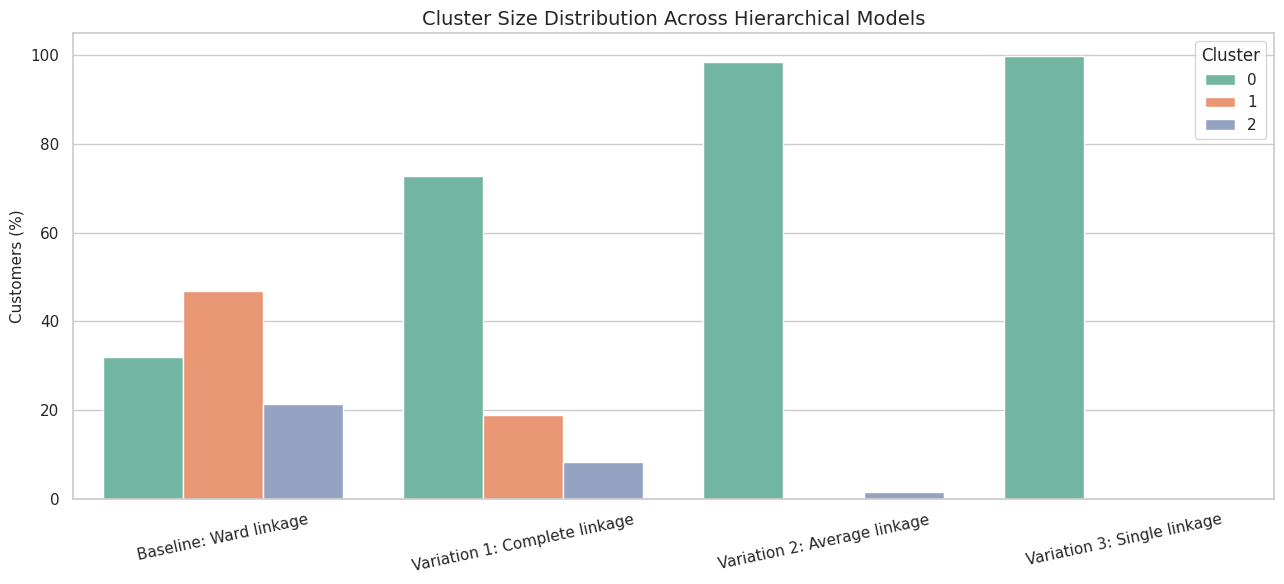

In [128]:


hierarchical_cluster_sizes = []

for model_name, labels in hierarchical_labels.items():

    size_table = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .reset_index(name="Customer_Count")
    )

    size_table["Customer_Percentage"] = (
        size_table["Customer_Count"]
        / len(labels)
        * 100
    ).round(2)

    size_table.insert(0, "Model", model_name)

    hierarchical_cluster_sizes.append(size_table)

hierarchical_cluster_sizes = pd.concat(
    hierarchical_cluster_sizes,
    ignore_index=True
)

display(hierarchical_cluster_sizes)

hierarchical_cluster_sizes.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "hierarchical_cluster_sizes_all_models.csv"
    ),
    index=False
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=hierarchical_cluster_sizes,
    x="Model",
    y="Customer_Percentage",
    hue="Cluster",
    palette="Set2"
)

plt.title("Cluster Size Distribution Across Hierarchical Models")
plt.xlabel("")
plt.ylabel("Customers (%)")
plt.xticks(rotation=12)
plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    os.path.join(
        HIERARCHICAL_DIR,
        "hierarchical_cluster_size_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

 Dendrogram sample

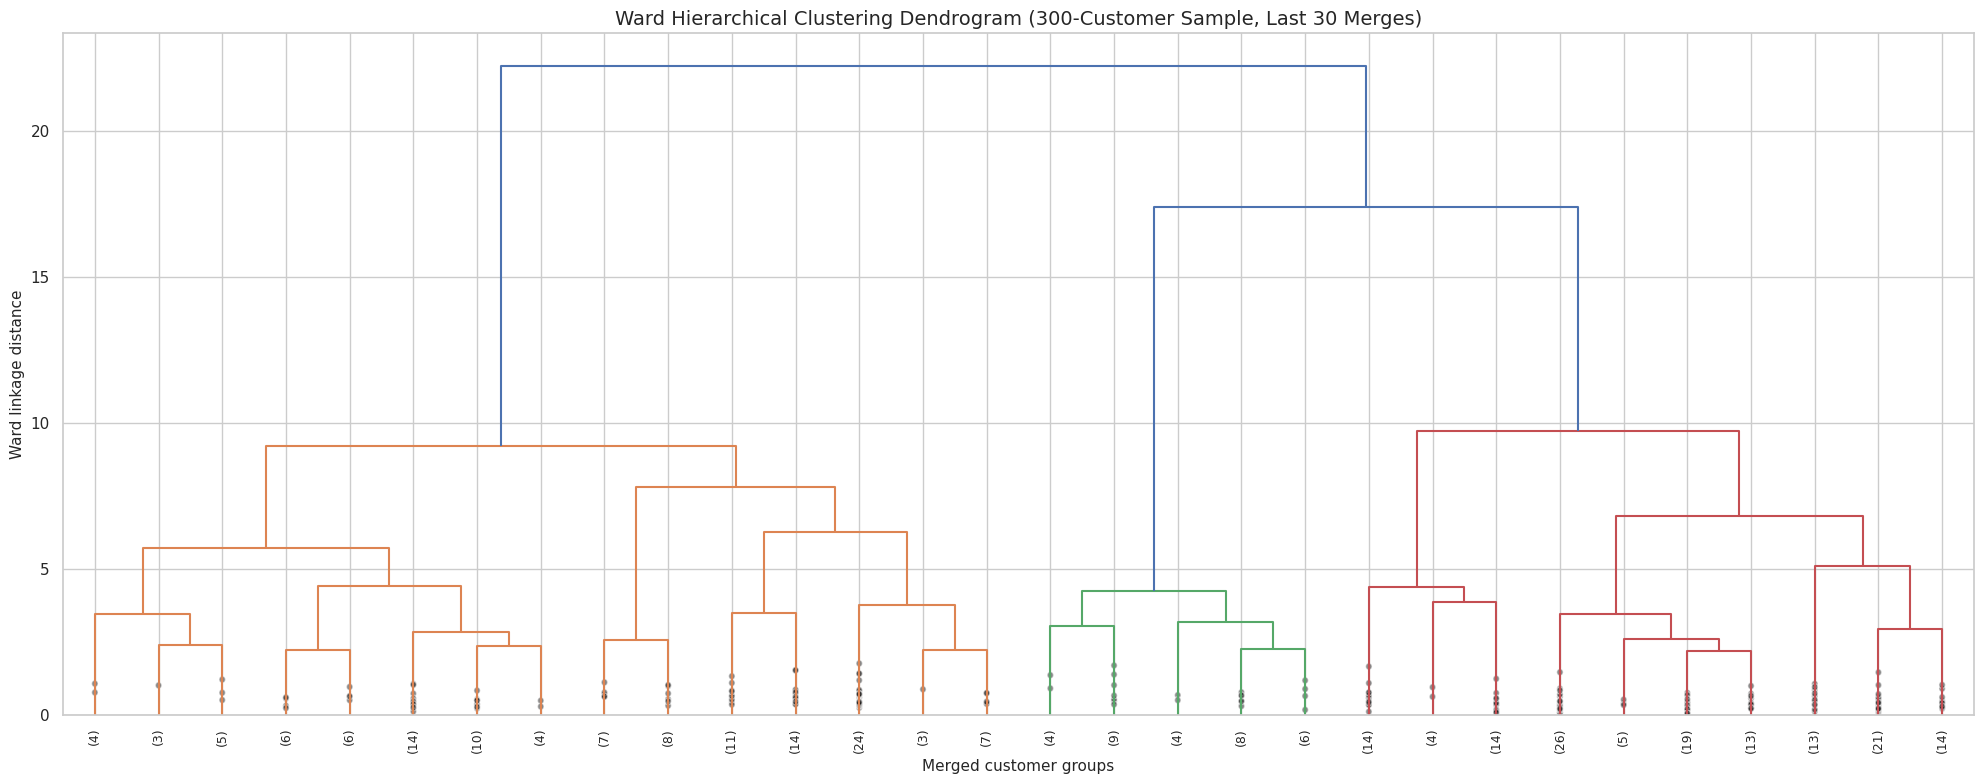

Dendrogram sample size: 300
The dendrogram is an explanatory visualization only.
All 4,338 customers are used in model comparison and final clustering.


In [129]:

# DENDROGRAM ON A REPRODUCIBLE 300 CUSTOMER SAMPLE


DENDROGRAM_SAMPLE_SIZE = 300

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    X_hierarchical.index.to_numpy(),
    size=DENDROGRAM_SAMPLE_SIZE,
    replace=False
)

X_dendrogram_sample = X_hierarchical.loc[sample_indices]

# Ward linkage is used for the illustrative baseline dendrogram.
linkage_matrix = linkage(
    X_dendrogram_sample,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(20, 8))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title(
    "Ward Hierarchical Clustering Dendrogram "
    "(300-Customer Sample, Last 30 Merges)"
)
plt.xlabel("Merged customer groups")
plt.ylabel("Ward linkage distance")

plt.tight_layout()

plt.savefig(
    os.path.join(
        HIERARCHICAL_DIR,
        "ward_dendrogram_sample_300_customers.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dendrogram sample size:", DENDROGRAM_SAMPLE_SIZE)
print("The dendrogram is an explanatory visualization only.")
print("All 4,338 customers are used in model comparison and final clustering.")

Choosing the best model

In [130]:


eligible_hierarchical_models = hierarchical_ranking[
    hierarchical_ranking["Meets_5pct_Minimum_Cluster_Rule"]
].copy()

if eligible_hierarchical_models.empty:
    eligible_hierarchical_models = hierarchical_ranking.copy()
    print(
        "Warning: no model met the 5% minimum-cluster rule. "
        "Selecting the best available model for profiling."
    )

best_hierarchical_model_name = (
    eligible_hierarchical_models
    .iloc[0]["Model"]
)

best_hierarchical_linkage = (
    eligible_hierarchical_models
    .iloc[0]["Linkage"]
)

best_hierarchical_labels = hierarchical_labels[
    best_hierarchical_model_name
]

best_hierarchical_model = hierarchical_models[
    best_hierarchical_model_name
]

print("Selected hierarchical model:")
print("Model:", best_hierarchical_model_name)
print("Linkage:", best_hierarchical_linkage)
print("Clusters:", N_CLUSTERS)

display(
    eligible_hierarchical_models.head(1).round(4)
)

Selected hierarchical model:
Model: Variation 1: Complete linkage
Linkage: complete
Clusters: 3


,Model,Linkage,Metric,Clusters,Silhouette_Score,Davies_Bouldin_Score,Calinski_Harabasz_Score,Smallest_Cluster_Size,Largest_Cluster_Size,Smallest_Cluster_Percentage,Largest_Cluster_Percentage,Meets_5pct_Minimum_Cluster_Rule,Silhouette_Rank,Davies_Bouldin_Rank,Calinski_Harabasz_Rank,Average_Metric_Rank
0,Variation 1: Complete linkage,complete,euclidean,3,0.3132,1.0255,1533.509,360,3157,8.2988,72.7755,True,3,3,2,2.67


 Profile the best hierarchical model

In [131]:


hierarchical_customer_clusters = customer_all.copy().reset_index(drop=True)

assert len(hierarchical_customer_clusters) == len(best_hierarchical_labels)
assert hierarchical_customer_clusters["CustomerID"].is_unique

hierarchical_customer_clusters["Cluster"] = (
    best_hierarchical_labels.astype(int)
)

profile_features = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationRate",
    "CustomerTenureDays"
]

hierarchical_cluster_counts = (
    hierarchical_customer_clusters
    .groupby("Cluster")
    .size()
    .rename("Customer_Count")
)

hierarchical_cluster_percentages = (
    hierarchical_customer_clusters
    .groupby("Cluster")
    .size()
    .div(len(hierarchical_customer_clusters))
    .mul(100)
    .rename("Customer_Percentage")
)

hierarchical_profile_means = (
    hierarchical_customer_clusters
    .groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

hierarchical_profile_medians = (
    hierarchical_customer_clusters
    .groupby("Cluster")[profile_features]
    .median()
    .round(2)
)

hierarchical_profile_summary = pd.concat(
    [
        hierarchical_cluster_counts,
        hierarchical_cluster_percentages,
        hierarchical_profile_means
    ],
    axis=1
).round(2)

print("Selected model:", best_hierarchical_model_name)

print("\nMean customer profile by hierarchical cluster:")
display(hierarchical_profile_summary)

print("\nMedian customer profile by hierarchical cluster:")
display(hierarchical_profile_medians)

hierarchical_profile_summary.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "best_hierarchical_cluster_profile_means.csv"
    )
)

hierarchical_profile_medians.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "best_hierarchical_cluster_profile_medians.csv"
    )
)

Selected model: Variation 1: Complete linkage

Mean customer profile by hierarchical cluster:


,Customer_Count,Customer_Percentage,RecencyDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationRate,CustomerTenureDays
Cluster,,,,,,,,,,,
0,3157,72.78,107.18,2.47,800.59,496.94,39.69,331.98,205.57,0.04,97.89
1,821,18.93,18.24,12.33,7068.23,4003.98,158.02,515.72,295.02,0.18,287.04
2,360,8.30,133.55,1.66,1613.71,865.85,31.07,963.57,578.83,0.48,58.84



Median customer profile by hierarchical cluster:


,RecencyDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationRate,CustomerTenureDays
Cluster,,,,,,,,,
0,66.0,2.0,508.46,285.0,28.0,251.21,143.33,0.0,41.0
1,10.0,9.0,3281.63,1887.0,119.0,385.52,229.50,0.17,317.0
2,87.5,1.0,443.52,252.0,20.0,324.69,171.25,0.5,0.0


PCA chart of selected model

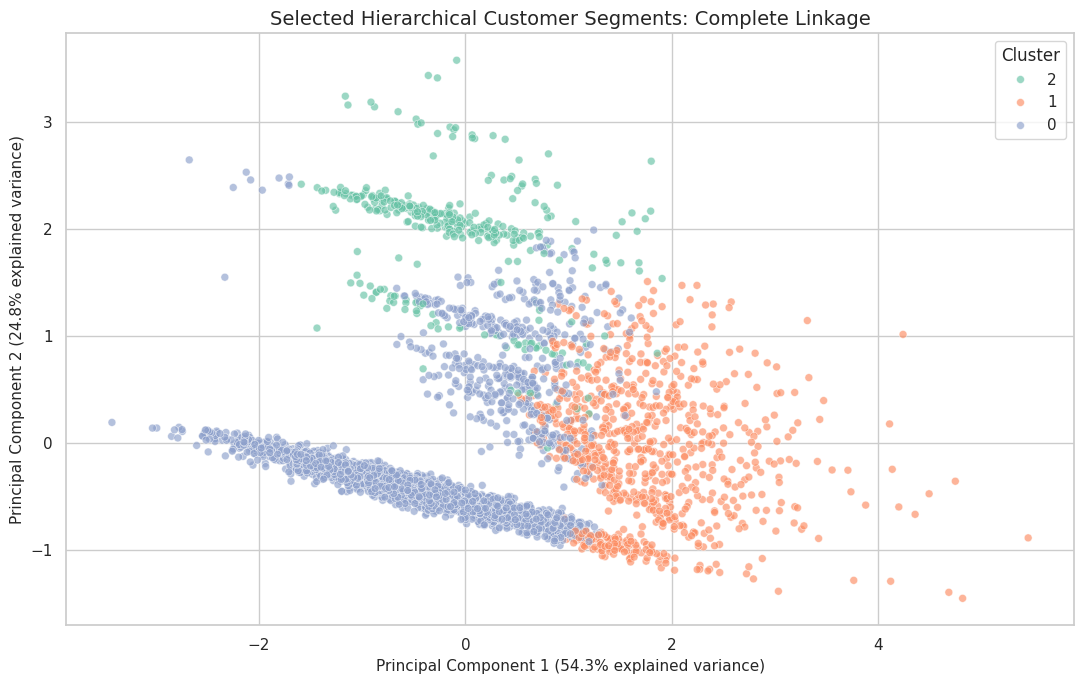

In [132]:


pca_hierarchical = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

pca_hierarchical_values = pca_hierarchical.fit_transform(
    X_hierarchical
)

pca_hierarchical_df = pd.DataFrame(
    pca_hierarchical_values,
    columns=["PC1", "PC2"]
)

pca_hierarchical_df["Cluster"] = (
    best_hierarchical_labels.astype(str)
)

explained_variance_hierarchical = (
    pca_hierarchical.explained_variance_ratio_ * 100
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_hierarchical_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.65,
    s=32
)

plt.title(
    f"Selected Hierarchical Customer Segments: "
    f"{best_hierarchical_linkage.title()} Linkage"
)
plt.xlabel(
    f"Principal Component 1 "
    f"({explained_variance_hierarchical[0]:.1f}% explained variance)"
)
plt.ylabel(
    f"Principal Component 2 "
    f"({explained_variance_hierarchical[1]:.1f}% explained variance)"
)
plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    os.path.join(
        HIERARCHICAL_DIR,
        "best_hierarchical_pca_clusters.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare selected hierarchical model with K-Means

In [133]:

# COMPARE SELECTED HIERARCHICAL MODEL WITH K-MEANS k = 3


assert "labels_k3" in globals(), (
    "labels_k3 is not available. Run the K-Means k = 3 model first."
)

assert len(labels_k3) == len(best_hierarchical_labels)

kmeans_hierarchical_ari = adjusted_rand_score(
    labels_k3,
    best_hierarchical_labels
)

model_agreement = pd.DataFrame({
    "Comparison": [
        "K-Means (k = 3) vs Selected Hierarchical Model (k = 3)"
    ],
    "Selected_Hierarchical_Model": [
        best_hierarchical_model_name
    ],
    "Adjusted_Rand_Index": [
        round(kmeans_hierarchical_ari, 4)
    ]
})

display(model_agreement)

model_agreement.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "kmeans_vs_best_hierarchical_agreement.csv"
    ),
    index=False
)

print("ARI interpretation guide:")
print("- 1.00: identical customer grouping, ignoring cluster label names.")
print("- Around 0.00: little agreement beyond chance.")
print("- A moderate score can still be useful because the models optimize different grouping rules.")

,Comparison,Selected_Hierarchical_Model,Adjusted_Rand_Index
0,K-Means (k = 3) vs Selected Hierarchical Model...,Variation 1: Complete linkage,0.3779


ARI interpretation guide:
- 1.00: identical customer grouping, ignoring cluster label names.
- Around 0.00: little agreement beyond chance.
- A moderate score can still be useful because the models optimize different grouping rules.


In [134]:


hierarchical_export_columns = [
    "CustomerID",
    "Cluster",
    "PrimaryCountry",
    "FirstPurchaseDate",
    "LastPurchaseDate",
    "RecencyDays",
    "CustomerTenureDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationInvoices",
    "TotalInvoicesObserved",
    "CancellationRate"
]

best_hierarchical_assignments = (
    hierarchical_customer_clusters[
        hierarchical_export_columns
    ]
    .sort_values(["Cluster", "CustomerID"])
    .reset_index(drop=True)
)

best_hierarchical_export_path = os.path.join(
    HIERARCHICAL_DIR,
    "best_hierarchical_customer_cluster_assignments.csv"
)

best_hierarchical_assignments.to_csv(
    best_hierarchical_export_path,
    index=False
)

print("Best hierarchical cluster assignments saved to:")
print(best_hierarchical_export_path)

display(best_hierarchical_assignments.head(10))

Best hierarchical cluster assignments saved to:
/content/drive/MyDrive/ML Project/project_outputs/kmeans/hierarchical_clustering/best_hierarchical_customer_cluster_assignments.csv


,CustomerID,Cluster,PrimaryCountry,FirstPurchaseDate,LastPurchaseDate,RecencyDays,CustomerTenureDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationInvoices,TotalInvoicesObserved,CancellationRate
0,12348,0,Finland,2010-12-16 19:09:00,2011-09-25 13:13:00,75,282,4,1797.24,2341,21,449.310000,585.250000,0,4,0.0
1,12349,0,Italy,2011-11-21 09:51:00,2011-11-21 09:51:00,19,0,1,1757.55,631,72,1757.550000,631.000000,0,1,0.0
2,12350,0,Norway,2011-02-02 16:01:00,2011-02-02 16:01:00,310,0,1,334.40,197,16,334.400000,197.000000,0,1,0.0
3,12353,0,Bahrain,2011-05-19 17:47:00,2011-05-19 17:47:00,204,0,1,89.00,20,4,89.000000,20.000000,0,1,0.0
4,12354,0,Spain,2011-04-21 13:11:00,2011-04-21 13:11:00,232,0,1,1079.40,530,58,1079.400000,530.000000,0,1,0.0
5,12355,0,Bahrain,2011-05-09 13:49:00,2011-05-09 13:49:00,214,0,1,459.40,240,13,459.400000,240.000000,0,1,0.0
6,12356,0,Portugal,2011-01-18 09:50:00,2011-11-17 08:40:00,23,302,3,2811.43,1591,52,937.143333,530.333333,0,3,0.0
7,12357,0,Switzerland,2011-11-06 16:07:00,2011-11-06 16:07:00,33,0,1,6207.67,2708,131,6207.670000,2708.000000,0,1,0.0
8,12358,0,Austria,2011-07-12 10:04:00,2011-12-08 10:26:00,2,149,2,1168.06,248,12,584.030000,124.000000,0,2,0.0
9,12360,0,Austria,2011-05-23 09:43:00,2011-10-18 15:22:00,52,148,3,2662.06,1165,104,887.353333,388.333333,0,3,0.0


ADD BUSINESS NAMES TO SELECTED HIERARCHICAL CLUSTERS

In [135]:

# ADD BUSINESS NAMES TO SELECTED HIERARCHICAL CLUSTERS


hierarchical_segment_names = {
    0: "Occasional Low-Value Customers",
    1: "Loyal High-Value Customers",
    2: "High-Value At-Risk / Return-Prone Customers"
}

hierarchical_segment_descriptions = {
    0: (
        "Low-frequency and lower-spend customers with relatively long "
        "recency; suitable for low-cost reactivation and repeat-purchase campaigns."
    ),
    1: (
        "Recent, frequent, high-spending, high-diversity customers with "
        "long customer tenure; suitable for retention, loyalty, and premium cross-selling."
    ),
    2: (
        "Infrequent customers with high average order value and elevated cancellation "
        "behaviour; suitable for service recovery and cancellation-cause investigation."
    )
}

hierarchical_customer_clusters["Segment_Name"] = (
    hierarchical_customer_clusters["Cluster"]
    .map(hierarchical_segment_names)
)

hierarchical_customer_clusters["Segment_Description"] = (
    hierarchical_customer_clusters["Cluster"]
    .map(hierarchical_segment_descriptions)
)

assert hierarchical_customer_clusters["Segment_Name"].notna().all()
assert hierarchical_customer_clusters["Segment_Description"].notna().all()

display(
    hierarchical_customer_clusters[
        [
            "CustomerID",
            "Cluster",
            "Segment_Name",
            "Segment_Description",
            "RecencyDays",
            "InvoiceFrequency",
            "TotalRevenue",
            "CancellationRate"
        ]
    ].head(10)
)

print(
    hierarchical_customer_clusters[
        ["Cluster", "Segment_Name"]
    ]
    .drop_duplicates()
    .sort_values("Cluster")
    .to_string(index=False)
)

,CustomerID,Cluster,Segment_Name,Segment_Description,RecencyDays,InvoiceFrequency,TotalRevenue,CancellationRate
0,12346,2,High-Value At-Risk / Return-Prone Customers,Infrequent customers with high average order v...,326,1,77183.60,0.5
1,12347,1,Loyal High-Value Customers,"Recent, frequent, high-spending, high-diversit...",2,7,4310.00,0.0
2,12348,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,75,4,1797.24,0.0
3,12349,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,19,1,1757.55,0.0
4,12350,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,310,1,334.40,0.0
5,12352,1,Loyal High-Value Customers,"Recent, frequent, high-spending, high-diversit...",36,8,2506.04,0.272727
6,12353,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,204,1,89.00,0.0
7,12354,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,232,1,1079.40,0.0
8,12355,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,214,1,459.40,0.0
9,12356,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,23,3,2811.43,0.0


 Cluster                                Segment_Name
       0              Occasional Low-Value Customers
       1                  Loyal High-Value Customers
       2 High-Value At-Risk / Return-Prone Customers


In [136]:

#  NAMED HIERARCHICAL SEGMENT PROFILE TABLE


named_hierarchical_profile = (
    hierarchical_customer_clusters
    .groupby(["Cluster", "Segment_Name"])
    .agg(
        Customers=("CustomerID", "count"),
        Customer_Percentage=("CustomerID", lambda x: len(x) / len(hierarchical_customer_clusters) * 100),
        Mean_RecencyDays=("RecencyDays", "mean"),
        Median_RecencyDays=("RecencyDays", "median"),
        Mean_InvoiceFrequency=("InvoiceFrequency", "mean"),
        Median_InvoiceFrequency=("InvoiceFrequency", "median"),
        Mean_TotalRevenue=("TotalRevenue", "mean"),
        Median_TotalRevenue=("TotalRevenue", "median"),
        Mean_UniqueProducts=("UniqueProducts", "mean"),
        Median_UniqueProducts=("UniqueProducts", "median"),
        Mean_AvgRevenuePerInvoice=("AvgRevenuePerInvoice", "mean"),
        Median_AvgRevenuePerInvoice=("AvgRevenuePerInvoice", "median"),
        Mean_CancellationRate=("CancellationRate", "mean"),
        Median_CancellationRate=("CancellationRate", "median"),
        Mean_CustomerTenureDays=("CustomerTenureDays", "mean"),
        Median_CustomerTenureDays=("CustomerTenureDays", "median")
    )
    .reset_index()
)

named_hierarchical_profile["Customer_Percentage"] = (
    named_hierarchical_profile["Customer_Percentage"].round(2)
)

numeric_profile_columns = [
    column for column in named_hierarchical_profile.columns
    if column not in ["Cluster", "Segment_Name", "Customers", "Customer_Percentage"]
]

named_hierarchical_profile[numeric_profile_columns] = (
    named_hierarchical_profile[numeric_profile_columns].round(2)
)

display(named_hierarchical_profile)

named_hierarchical_profile.to_csv(
    os.path.join(
        HIERARCHICAL_DIR,
        "best_hierarchical_named_segment_profiles.csv"
    ),
    index=False
)

,Cluster,Segment_Name,Customers,Customer_Percentage,Mean_RecencyDays,Median_RecencyDays,Mean_InvoiceFrequency,Median_InvoiceFrequency,Mean_TotalRevenue,Median_TotalRevenue,Mean_UniqueProducts,Median_UniqueProducts,Mean_AvgRevenuePerInvoice,Median_AvgRevenuePerInvoice,Mean_CancellationRate,Median_CancellationRate,Mean_CustomerTenureDays,Median_CustomerTenureDays
0,0,Occasional Low-Value Customers,3157,72.78,107.18,66.0,2.47,2.0,800.59,508.46,39.69,28.0,331.98,251.21,0.04,0.0,97.89,41.0
1,1,Loyal High-Value Customers,821,18.93,18.24,10.0,12.33,9.0,7068.23,3281.63,158.02,119.0,515.72,385.52,0.18,0.17,287.04,317.0
2,2,High-Value At-Risk / Return-Prone Customers,360,8.30,133.55,87.5,1.66,1.0,1613.71,443.52,31.07,20.0,963.57,324.69,0.48,0.5,58.84,0.0


Add named cluster chart

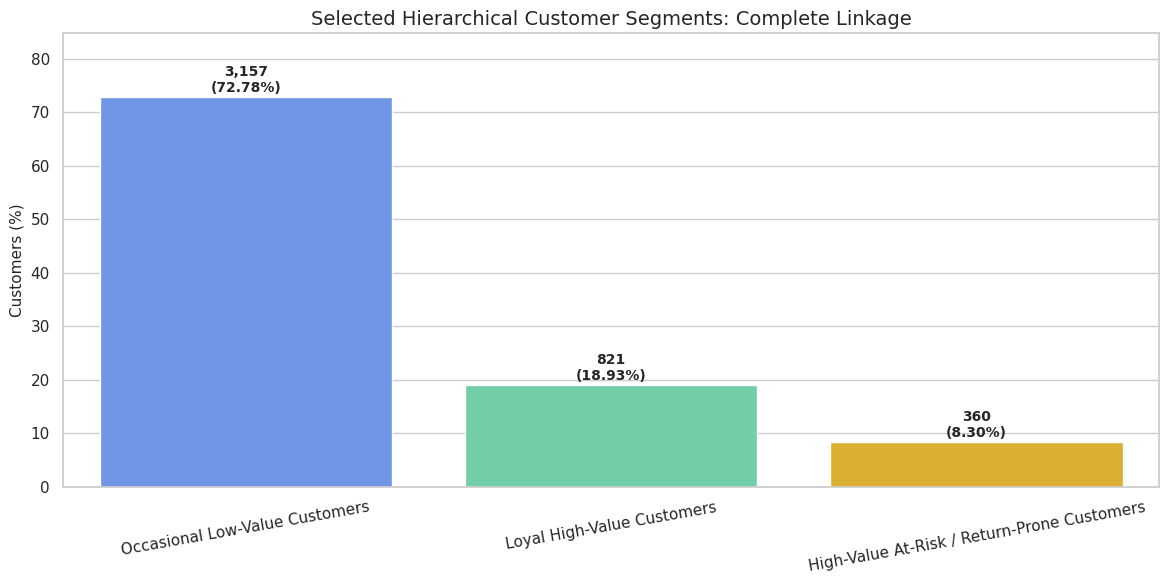

,Segment_Name,Customer_Count,Customer_Percentage
0,Occasional Low-Value Customers,3157,72.78
1,Loyal High-Value Customers,821,18.93
2,High-Value At-Risk / Return-Prone Customers,360,8.30


In [137]:


hierarchical_segment_counts = (
    hierarchical_customer_clusters["Segment_Name"]
    .value_counts()
    .rename_axis("Segment_Name")
    .reset_index(name="Customer_Count")
)

hierarchical_segment_counts["Customer_Percentage"] = (
    hierarchical_segment_counts["Customer_Count"]
    / hierarchical_segment_counts["Customer_Count"].sum()
    * 100
).round(2)

segment_order = [
    "Occasional Low-Value Customers",
    "Loyal High-Value Customers",
    "High-Value At-Risk / Return-Prone Customers"
]

hierarchical_segment_counts["Segment_Name"] = pd.Categorical(
    hierarchical_segment_counts["Segment_Name"],
    categories=segment_order,
    ordered=True
)

hierarchical_segment_counts = (
    hierarchical_segment_counts
    .sort_values("Segment_Name")
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=hierarchical_segment_counts,
    x="Segment_Name",
    y="Customer_Percentage",
    hue="Segment_Name",
    palette=["#5B8FF9", "#61DDAA", "#F6BD16"],
    legend=False
)

for index, row in hierarchical_segment_counts.iterrows():
    ax.text(
        index,
        row["Customer_Percentage"] + 1,
        f'{row["Customer_Count"]:,}\n({row["Customer_Percentage"]:.2f}%)',
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Selected Hierarchical Customer Segments: Complete Linkage")
plt.xlabel("")
plt.ylabel("Customers (%)")
plt.xticks(rotation=10)
plt.ylim(
    0,
    hierarchical_segment_counts["Customer_Percentage"].max() + 12
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        HIERARCHICAL_DIR,
        "best_hierarchical_named_segment_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(hierarchical_segment_counts)

In [138]:


final_hierarchical_export_columns = [
    "CustomerID",
    "Cluster",
    "Segment_Name",
    "Segment_Description",
    "PrimaryCountry",
    "FirstPurchaseDate",
    "LastPurchaseDate",
    "RecencyDays",
    "CustomerTenureDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationInvoices",
    "TotalInvoicesObserved",
    "CancellationRate"
]

final_hierarchical_assignments = (
    hierarchical_customer_clusters[
        final_hierarchical_export_columns
    ]
    .sort_values(["Cluster", "CustomerID"])
    .reset_index(drop=True)
)

final_hierarchical_export_path = os.path.join(
    HIERARCHICAL_DIR,
    "final_complete_linkage_hierarchical_customer_segments.csv"
)

final_hierarchical_assignments.to_csv(
    final_hierarchical_export_path,
    index=False
)

print("Final named hierarchical segments saved to:")
print(final_hierarchical_export_path)

display(final_hierarchical_assignments.head(10))

Final named hierarchical segments saved to:
/content/drive/MyDrive/ML Project/project_outputs/kmeans/hierarchical_clustering/final_complete_linkage_hierarchical_customer_segments.csv


,CustomerID,Cluster,Segment_Name,Segment_Description,PrimaryCountry,FirstPurchaseDate,LastPurchaseDate,RecencyDays,CustomerTenureDays,InvoiceFrequency,TotalRevenue,TotalQuantity,UniqueProducts,AvgRevenuePerInvoice,AvgQuantityPerInvoice,CancellationInvoices,TotalInvoicesObserved,CancellationRate
0,12348,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Finland,2010-12-16 19:09:00,2011-09-25 13:13:00,75,282,4,1797.24,2341,21,449.310000,585.250000,0,4,0.0
1,12349,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Italy,2011-11-21 09:51:00,2011-11-21 09:51:00,19,0,1,1757.55,631,72,1757.550000,631.000000,0,1,0.0
2,12350,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Norway,2011-02-02 16:01:00,2011-02-02 16:01:00,310,0,1,334.40,197,16,334.400000,197.000000,0,1,0.0
3,12353,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Bahrain,2011-05-19 17:47:00,2011-05-19 17:47:00,204,0,1,89.00,20,4,89.000000,20.000000,0,1,0.0
4,12354,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Spain,2011-04-21 13:11:00,2011-04-21 13:11:00,232,0,1,1079.40,530,58,1079.400000,530.000000,0,1,0.0
5,12355,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Bahrain,2011-05-09 13:49:00,2011-05-09 13:49:00,214,0,1,459.40,240,13,459.400000,240.000000,0,1,0.0
6,12356,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Portugal,2011-01-18 09:50:00,2011-11-17 08:40:00,23,302,3,2811.43,1591,52,937.143333,530.333333,0,3,0.0
7,12357,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Switzerland,2011-11-06 16:07:00,2011-11-06 16:07:00,33,0,1,6207.67,2708,131,6207.670000,2708.000000,0,1,0.0
8,12358,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Austria,2011-07-12 10:04:00,2011-12-08 10:26:00,2,149,2,1168.06,248,12,584.030000,124.000000,0,2,0.0
9,12360,0,Occasional Low-Value Customers,Low-frequency and lower-spend customers with r...,Austria,2011-05-23 09:43:00,2011-10-18 15:22:00,52,148,3,2662.06,1165,104,887.353333,388.333333,0,3,0.0


Agglomerative hierarchical clustering was evaluated using a Ward-linkage baseline and complete-, average-, and single-linkage variations, each with three clusters and Euclidean distance. Complete linkage was selected because it produced the strongest valid overall result: a silhouette score of 0.3132, Davies–Bouldin score of 1.0255, and Calinski–Harabasz score of 1533.51, while retaining three usable clusters containing 72.78%, 18.93%, and 8.30% of customers. Average and single linkage were rejected despite stronger silhouette values because both generated one dominant cluster above 98% of customers and tiny residual clusters, making the segmentation commercially impractical.

The selected model identified occasional low-value customers, loyal high-value customers, and high-value at-risk/return-prone customers. These groups support differentiated marketing actions: low-cost reactivation for occasional customers, retention and cross-selling for loyal high-value customers, and service recovery or cancellation-cause investigation for the at-risk segment.

Limitation - The segmentation is exploratory because the dataset has no verified customer-segment labels. Internal validity metrics indicate structural separation but do not prove that segments will remain stable or respond differently to campaigns. The selected model also has moderate agreement with K-Means (ARI = 0.3779), indicating partially consistent but not identical customer structures. Future work should validate the segments using campaign response, retention, repeat purchase, and profitability outcomes.

# DBSCAN Clustering - IT24102710 - Sandul T.H.N.N

In [139]:

# D1: DBSCAN SETUP AND INPUT VALIDATION


from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

DBSCAN_DIR = os.path.join(
    HIERARCHICAL_DIR,
    "dbscan_clustering"
)

os.makedirs(DBSCAN_DIR, exist_ok=True)

# Use the SAME five selected, transformed, and RobustScaler-scaled
# customer features used for K-Means and hierarchical clustering.
# This preserves fair comparability between clustering methods.
if "X_hierarchical" in globals():
    X_dbscan = X_hierarchical.copy()
elif "Xpreprocessed" in globals():
    X_dbscan = Xpreprocessed.copy()
else:
    raise NameError(
        "No valid preprocessed matrix found. "
        "Run the preprocessing, K-Means, and hierarchical sections first."
    )

EXPECTED_FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

assert X_dbscan.shape == (4338, 5)
assert list(X_dbscan.columns) == EXPECTED_FEATURES
assert np.isfinite(X_dbscan.to_numpy()).all()
assert not X_dbscan.isna().any().any()

assert len(customer_all) == len(X_dbscan)

print("DBSCAN setup completed successfully.")
print("Customer matrix shape:", X_dbscan.shape)
print("Selected model features:", X_dbscan.columns.tolist())
print("Output folder:", DBSCAN_DIR)

DBSCAN setup completed successfully.
Customer matrix shape: (4338, 5)
Selected model features: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']
Output folder: /content/drive/MyDrive/ML Project/project_outputs/kmeans/hierarchical_clustering/dbscan_clustering


k-distance plot
- This plot helps justify a sensible eps search range. For each customer, it calculates the distance to its 10th nearest neighbour. Look for the elbow: the point where distances begin increasing rapidly.

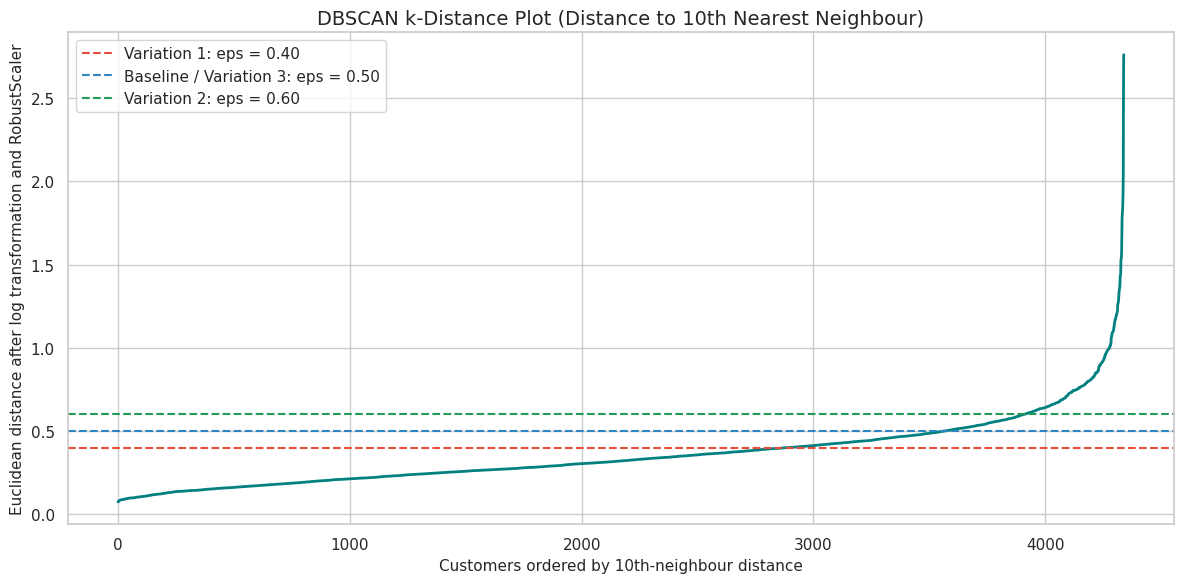

,Statistic,10th_Neighbour_Distance
0,Minimum,0.0738
1,25th Percentile,0.2195
2,Median,0.3195
3,75th Percentile,0.4444
4,90th Percentile,0.5986
5,95th Percentile,0.7433
6,99th Percentile,1.1129
7,Maximum,2.7615


In [140]:

#K-DISTANCE PLOT FOR EPS JUSTIFICATION


K_DISTANCE_NEIGHBOURS = 10

nearest_neighbours = NearestNeighbors(
    n_neighbors=K_DISTANCE_NEIGHBOURS,
    metric="euclidean"
)

nearest_neighbours.fit(X_dbscan)

distances, indices = nearest_neighbours.kneighbors(X_dbscan)

# The final column contains each customer's distance to its 10th nearest neighbour.
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(k_distances) + 1),
    k_distances,
    color="teal",
    linewidth=2
)

# Visual guides for proposed eps values
for eps_value, color, label in [
    (0.40, "#E74C3C", "Variation 1: eps = 0.40"),
    (0.50, "#2E86C1", "Baseline / Variation 3: eps = 0.50"),
    (0.60, "#239B56", "Variation 2: eps = 0.60")
]:
    plt.axhline(
        y=eps_value,
        color=color,
        linestyle="--",
        linewidth=1.5,
        label=label
    )

plt.title(
    "DBSCAN k-Distance Plot "
    "(Distance to 10th Nearest Neighbour)"
)
plt.xlabel("Customers ordered by 10th-neighbour distance")
plt.ylabel("Euclidean distance after log transformation and RobustScaler")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_k_distance_plot_min_samples_10.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

k_distance_summary = pd.DataFrame({
    "Statistic": ["Minimum", "25th Percentile", "Median",
                  "75th Percentile", "90th Percentile",
                  "95th Percentile", "99th Percentile", "Maximum"],
    "10th_Neighbour_Distance": [
        k_distances.min(),
        np.percentile(k_distances, 25),
        np.percentile(k_distances, 50),
        np.percentile(k_distances, 75),
        np.percentile(k_distances, 90),
        np.percentile(k_distances, 95),
        np.percentile(k_distances, 99),
        k_distances.max()
    ]
}).round(4)

display(k_distance_summary)

k_distance_summary.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_k_distance_summary.csv"
    ),
    index=False
)

Baseline DBSCAN Model

In [141]:

# DBSCAN BASELINE
# eps = 0.50, min_samples = 10


dbscan_baseline = DBSCAN(
    eps=0.50,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

labels_dbscan_baseline = dbscan_baseline.fit_predict(X_dbscan)

print("Baseline DBSCAN completed.")
print("Parameters: eps = 0.50, min_samples = 10")
print("Number of discovered clusters:",
      len(set(labels_dbscan_baseline)) - (1 if -1 in labels_dbscan_baseline else 0))
print("Noise customers:",
      int((labels_dbscan_baseline == -1).sum()))
print("Noise percentage:",
      round((labels_dbscan_baseline == -1).mean() * 100, 2), "%")

Baseline DBSCAN completed.
Parameters: eps = 0.50, min_samples = 10
Number of discovered clusters: 2
Noise customers: 343
Noise percentage: 7.91 %


DBSCAN Model Variation 1

In [142]:

# DBSCAN VARIATION 1
# eps = 0.40, min_samples = 10
# Stricter neighbourhood radius


dbscan_variation_1 = DBSCAN(
    eps=0.40,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

labels_dbscan_variation_1 = dbscan_variation_1.fit_predict(X_dbscan)

print("DBSCAN Variation 1 completed.")
print("Parameters: eps = 0.40, min_samples = 10")
print("Number of discovered clusters:",
      len(set(labels_dbscan_variation_1)) -
      (1 if -1 in labels_dbscan_variation_1 else 0))
print("Noise customers:",
      int((labels_dbscan_variation_1 == -1).sum()))
print("Noise percentage:",
      round((labels_dbscan_variation_1 == -1).mean() * 100, 2), "%")

DBSCAN Variation 1 completed.
Parameters: eps = 0.40, min_samples = 10
Number of discovered clusters: 4
Noise customers: 845
Noise percentage: 19.48 %


DBSCAN Variation 2

eps = 0.60, min_samples = 10
Looser neighbourhood radius

In [143]:

# eps = 0.60, min_samples = 10
# Looser neighbourhood radius


dbscan_variation_2 = DBSCAN(
    eps=0.60,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

labels_dbscan_variation_2 = dbscan_variation_2.fit_predict(X_dbscan)

print("DBSCAN Variation 2 completed.")
print("Parameters: eps = 0.60, min_samples = 10")
print("Number of discovered clusters:",
      len(set(labels_dbscan_variation_2)) -
      (1 if -1 in labels_dbscan_variation_2 else 0))
print("Noise customers:",
      int((labels_dbscan_variation_2 == -1).sum()))
print("Noise percentage:",
      round((labels_dbscan_variation_2 == -1).mean() * 100, 2), "%")

DBSCAN Variation 2 completed.
Parameters: eps = 0.60, min_samples = 10
Number of discovered clusters: 1
Noise customers: 194
Noise percentage: 4.47 %


DBSCAN Variation 3

eps = 0.50, min_samples = 20
Higher minimum density requirement

In [144]:
# DBSCAN VARIATION 3
# eps = 0.50, min_samples = 20
# Higher minimum density requirement


dbscan_variation_3 = DBSCAN(
    eps=0.50,
    min_samples=20,
    metric="euclidean",
    n_jobs=-1
)

labels_dbscan_variation_3 = dbscan_variation_3.fit_predict(X_dbscan)

print("DBSCAN Variation 3 completed.")
print("Parameters: eps = 0.50, min_samples = 20")
print("Number of discovered clusters:",
      len(set(labels_dbscan_variation_3)) -
      (1 if -1 in labels_dbscan_variation_3 else 0))
print("Noise customers:",
      int((labels_dbscan_variation_3 == -1).sum()))
print("Noise percentage:",
      round((labels_dbscan_variation_3 == -1).mean() * 100, 2), "%")

DBSCAN Variation 3 completed.
Parameters: eps = 0.50, min_samples = 20
Number of discovered clusters: 2
Noise customers: 586
Noise percentage: 13.51 %


Evaluation on All 4 Models

In [145]:

#  EVALUATE BASELINE + THREE DBSCAN VARIATIONS


DBSCAN_SILHOUETTE_SAMPLE_SIZE = 1500
MIN_CLUSTER_SIZE_PERCENT = 0.05
MAX_NOISE_PERCENT = 30.0

dbscan_configurations = {
    "Baseline: eps=0.50, min_samples=10": {
        "eps": 0.50,
        "min_samples": 10,
        "labels": labels_dbscan_baseline
    },
    "Variation 1: eps=0.40, min_samples=10": {
        "eps": 0.40,
        "min_samples": 10,
        "labels": labels_dbscan_variation_1
    },
    "Variation 2: eps=0.60, min_samples=10": {
        "eps": 0.60,
        "min_samples": 10,
        "labels": labels_dbscan_variation_2
    },
    "Variation 3: eps=0.50, min_samples=20": {
        "eps": 0.50,
        "min_samples": 20,
        "labels": labels_dbscan_variation_3
    }
}

dbscan_models = {
    "Baseline: eps=0.50, min_samples=10": dbscan_baseline,
    "Variation 1: eps=0.40, min_samples=10": dbscan_variation_1,
    "Variation 2: eps=0.60, min_samples=10": dbscan_variation_2,
    "Variation 3: eps=0.50, min_samples=20": dbscan_variation_3
}

dbscan_evaluation_rows = []

for model_name, config in dbscan_configurations.items():

    labels = config["labels"]

    non_noise_mask = labels != -1
    non_noise_labels = labels[non_noise_mask]
    X_non_noise = X_dbscan.loc[non_noise_mask]

    n_clusters = len(np.unique(non_noise_labels))
    n_noise = int((labels == -1).sum())
    noise_percentage = n_noise / len(labels) * 100
    n_non_noise = int(non_noise_mask.sum())

    if n_clusters >= 2 and n_non_noise > n_clusters:
        cluster_counts = pd.Series(non_noise_labels).value_counts()
        cluster_percentages = cluster_counts / len(labels) * 100

        silhouette = silhouette_score(
            X_non_noise,
            non_noise_labels,
            sample_size=min(
                DBSCAN_SILHOUETTE_SAMPLE_SIZE,
                len(X_non_noise)
            ),
            random_state=RANDOM_STATE
        )

        davies_bouldin = davies_bouldin_score(
            X_non_noise,
            non_noise_labels
        )

        calinski_harabasz = calinski_harabasz_score(
            X_non_noise,
            non_noise_labels
        )

        smallest_cluster_size = int(cluster_counts.min())
        largest_cluster_size = int(cluster_counts.max())
        smallest_cluster_percentage = cluster_percentages.min()
        largest_cluster_percentage = cluster_percentages.max()

    else:
        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan
        smallest_cluster_size = np.nan
        largest_cluster_size = np.nan
        smallest_cluster_percentage = np.nan
        largest_cluster_percentage = np.nan

    # Business validity conditions:
    # - At least two discovered customer segments
    # - All discovered segments have at least 5% of all customers
    # - Noise customers do not exceed 30% of all customers
    meets_cluster_size_rule = (
        pd.notna(smallest_cluster_percentage)
        and smallest_cluster_percentage >= MIN_CLUSTER_SIZE_PERCENT * 100
    )

    meets_noise_rule = noise_percentage <= MAX_NOISE_PERCENT

    is_valid_dbscan_solution = (
        n_clusters >= 2
        and meets_cluster_size_rule
        and meets_noise_rule
        and pd.notna(silhouette)
    )

    dbscan_evaluation_rows.append({
        "Model": model_name,
        "eps": config["eps"],
        "min_samples": config["min_samples"],
        "Discovered_Clusters_Excluding_Noise": n_clusters,
        "Noise_Customers": n_noise,
        "Noise_Percentage": noise_percentage,
        "Non_Noise_Customers": n_non_noise,
        "Silhouette_Score_Non_Noise": silhouette,
        "Davies_Bouldin_Non_Noise": davies_bouldin,
        "Calinski_Harabasz_Non_Noise": calinski_harabasz,
        "Smallest_Cluster_Size": smallest_cluster_size,
        "Largest_Cluster_Size": largest_cluster_size,
        "Smallest_Cluster_Percentage_All_Customers": smallest_cluster_percentage,
        "Largest_Cluster_Percentage_All_Customers": largest_cluster_percentage,
        "Meets_5pct_Minimum_Cluster_Rule": meets_cluster_size_rule,
        "Meets_30pct_Maximum_Noise_Rule": meets_noise_rule,
        "Valid_Business_Segmentation": is_valid_dbscan_solution
    })

dbscan_comparison = pd.DataFrame(dbscan_evaluation_rows)

dbscan_comparison = (
    dbscan_comparison
    .sort_values(
        by=[
            "Valid_Business_Segmentation",
            "Silhouette_Score_Non_Noise",
            "Davies_Bouldin_Non_Noise",
            "Calinski_Harabasz_Non_Noise",
            "Noise_Percentage"
        ],
        ascending=[False, False, True, False, True]
    )
    .reset_index(drop=True)
)

dbscan_comparison_display = dbscan_comparison.copy()

round_columns = [
    "Noise_Percentage",
    "Silhouette_Score_Non_Noise",
    "Davies_Bouldin_Non_Noise",
    "Calinski_Harabasz_Non_Noise",
    "Smallest_Cluster_Percentage_All_Customers",
    "Largest_Cluster_Percentage_All_Customers"
]

for column in round_columns:
    dbscan_comparison_display[column] = (
        dbscan_comparison_display[column].round(4)
    )

print("DBSCAN baseline and variation comparison:")
display(dbscan_comparison_display)

dbscan_comparison_display.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_baseline_and_variations_comparison.csv"
    ),
    index=False
)

DBSCAN baseline and variation comparison:


,Model,eps,min_samples,Discovered_Clusters_Excluding_Noise,Noise_Customers,Noise_Percentage,Non_Noise_Customers,Silhouette_Score_Non_Noise,Davies_Bouldin_Non_Noise,Calinski_Harabasz_Non_Noise,Smallest_Cluster_Size,Largest_Cluster_Size,Smallest_Cluster_Percentage_All_Customers,Largest_Cluster_Percentage_All_Customers,Meets_5pct_Minimum_Cluster_Rule,Meets_30pct_Maximum_Noise_Rule,Valid_Business_Segmentation
0,"Variation 3: eps=0.50, min_samples=20",0.5,20,2,586,13.5085,3752,0.3473,0.8328,543.3836,190.0,3562.0,4.3799,82.1116,False,True,False
1,"Baseline: eps=0.50, min_samples=10",0.5,10,2,343,7.9069,3995,0.3198,0.5674,34.3980,8.0,3987.0,0.1844,91.9087,False,True,False
2,"Variation 1: eps=0.40, min_samples=10",0.4,10,4,845,19.4790,3493,0.2477,1.1779,803.0495,119.0,2589.0,2.7432,59.6819,False,True,False
3,"Variation 2: eps=0.60, min_samples=10",0.6,10,1,194,4.4721,4144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,False


Show Each DBSCAN CLuster size

,Model,Cluster,Customer_Count,Customer_Percentage,Cluster_Type
0,"Baseline: eps=0.50, min_samples=10",-1,343,7.91,Noise
1,"Baseline: eps=0.50, min_samples=10",0,3987,91.91,Customer Segment
2,"Baseline: eps=0.50, min_samples=10",1,8,0.18,Customer Segment
3,"Variation 1: eps=0.40, min_samples=10",-1,845,19.48,Noise
4,"Variation 1: eps=0.40, min_samples=10",0,2589,59.68,Customer Segment
5,"Variation 1: eps=0.40, min_samples=10",1,119,2.74,Customer Segment
6,"Variation 1: eps=0.40, min_samples=10",2,614,14.15,Customer Segment
7,"Variation 1: eps=0.40, min_samples=10",3,171,3.94,Customer Segment
8,"Variation 2: eps=0.60, min_samples=10",-1,194,4.47,Noise
9,"Variation 2: eps=0.60, min_samples=10",0,4144,95.53,Customer Segment


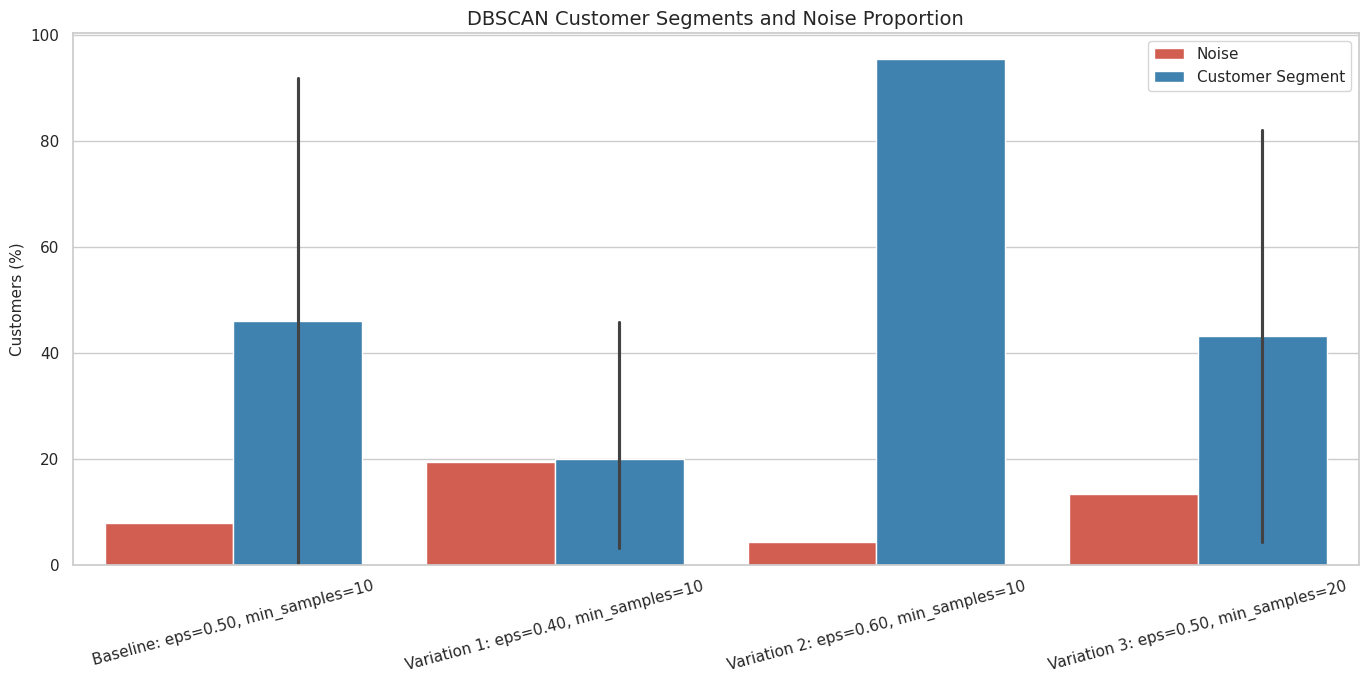

In [146]:


dbscan_cluster_size_tables = []

for model_name, config in dbscan_configurations.items():

    labels = config["labels"]

    cluster_size_table = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .reset_index(name="Customer_Count")
    )

    cluster_size_table["Customer_Percentage"] = (
        cluster_size_table["Customer_Count"]
        / len(labels)
        * 100
    ).round(2)

    cluster_size_table["Cluster_Type"] = np.where(
        cluster_size_table["Cluster"] == -1,
        "Noise",
        "Customer Segment"
    )

    cluster_size_table.insert(0, "Model", model_name)

    dbscan_cluster_size_tables.append(cluster_size_table)

dbscan_cluster_sizes = pd.concat(
    dbscan_cluster_size_tables,
    ignore_index=True
)

display(dbscan_cluster_sizes)

dbscan_cluster_sizes.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_cluster_sizes_all_models.csv"
    ),
    index=False
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=dbscan_cluster_sizes,
    x="Model",
    y="Customer_Percentage",
    hue="Cluster_Type",
    palette={
        "Customer Segment": "#2E86C1",
        "Noise": "#E74C3C"
    }
)

plt.title("DBSCAN Customer Segments and Noise Proportion")
plt.xlabel("")
plt.ylabel("Customers (%)")
plt.xticks(rotation=15)
plt.legend(title="")
plt.tight_layout()

plt.savefig(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_noise_and_cluster_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Rank valid DBSCAN models

In [147]:

dbscan_ranking = dbscan_comparison.copy()

# Ranking metrics are valid only where at least two non-noise clusters exist.
dbscan_ranking["Silhouette_Rank"] = (
    dbscan_ranking["Silhouette_Score_Non_Noise"]
    .rank(ascending=False, method="dense")
)

dbscan_ranking["Davies_Bouldin_Rank"] = (
    dbscan_ranking["Davies_Bouldin_Non_Noise"]
    .rank(ascending=True, method="dense")
)

dbscan_ranking["Calinski_Harabasz_Rank"] = (
    dbscan_ranking["Calinski_Harabasz_Non_Noise"]
    .rank(ascending=False, method="dense")
)

dbscan_ranking["Average_Metric_Rank"] = (
    dbscan_ranking[
        [
            "Silhouette_Rank",
            "Davies_Bouldin_Rank",
            "Calinski_Harabasz_Rank"
        ]
    ]
    .mean(axis=1)
)

dbscan_ranking = (
    dbscan_ranking
    .sort_values(
        by=[
            "Valid_Business_Segmentation",
            "Average_Metric_Rank",
            "Noise_Percentage"
        ],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

ranking_columns = [
    "Model",
    "eps",
    "min_samples",
    "Discovered_Clusters_Excluding_Noise",
    "Noise_Percentage",
    "Silhouette_Score_Non_Noise",
    "Davies_Bouldin_Non_Noise",
    "Calinski_Harabasz_Non_Noise",
    "Smallest_Cluster_Percentage_All_Customers",
    "Meets_5pct_Minimum_Cluster_Rule",
    "Meets_30pct_Maximum_Noise_Rule",
    "Valid_Business_Segmentation",
    "Silhouette_Rank",
    "Davies_Bouldin_Rank",
    "Calinski_Harabasz_Rank",
    "Average_Metric_Rank"
]

display(dbscan_ranking[ranking_columns].round(4))

dbscan_ranking.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_model_rankings.csv"
    ),
    index=False
)

valid_dbscan_models = dbscan_ranking[
    dbscan_ranking["Valid_Business_Segmentation"]
].copy()

if valid_dbscan_models.empty:
    print(
        "No DBSCAN configuration met all business-segmentation rules. "
        "This is a valid result: DBSCAN may be unsuitable as the final "
        "customer segmentation model for these data."
    )

    best_dbscan_model_name = None
    best_dbscan_labels = None

else:
    best_dbscan_model_name = valid_dbscan_models.iloc[0]["Model"]

    best_dbscan_labels = dbscan_configurations[
        best_dbscan_model_name
    ]["labels"]

    print("Selected DBSCAN model:")
    print("Model:", best_dbscan_model_name)
    print(
        "eps:",
        valid_dbscan_models.iloc[0]["eps"]
    )
    print(
        "min_samples:",
        int(valid_dbscan_models.iloc[0]["min_samples"])
    )

    display(valid_dbscan_models.head(1).round(4))

,Model,eps,min_samples,Discovered_Clusters_Excluding_Noise,Noise_Percentage,Silhouette_Score_Non_Noise,Davies_Bouldin_Non_Noise,Calinski_Harabasz_Non_Noise,Smallest_Cluster_Percentage_All_Customers,Meets_5pct_Minimum_Cluster_Rule,Meets_30pct_Maximum_Noise_Rule,Valid_Business_Segmentation,Silhouette_Rank,Davies_Bouldin_Rank,Calinski_Harabasz_Rank,Average_Metric_Rank
0,"Variation 3: eps=0.50, min_samples=20",0.5,20,2,13.5085,0.3473,0.8328,543.3836,4.3799,False,True,False,1.0,2.0,2.0,1.6667
1,"Baseline: eps=0.50, min_samples=10",0.5,10,2,7.9069,0.3198,0.5674,34.3980,0.1844,False,True,False,2.0,1.0,3.0,2.0000
2,"Variation 1: eps=0.40, min_samples=10",0.4,10,4,19.4790,0.2477,1.1779,803.0495,2.7432,False,True,False,3.0,3.0,1.0,2.3333
3,"Variation 2: eps=0.60, min_samples=10",0.6,10,1,4.4721,NaN,NaN,NaN,NaN,False,True,False,NaN,NaN,NaN,NaN


No DBSCAN configuration met all business-segmentation rules. This is a valid result: DBSCAN may be unsuitable as the final customer segmentation model for these data.


Profile the selected DBSCAN model

In [148]:

if best_dbscan_model_name is None:
    print(
        "No valid DBSCAN model was selected, so no final DBSCAN "
        "segment profile is created."
    )

else:
    dbscan_customer_clusters = customer_all.copy().reset_index(drop=True)

    assert len(dbscan_customer_clusters) == len(best_dbscan_labels)
    assert dbscan_customer_clusters["CustomerID"].is_unique

    dbscan_customer_clusters["Cluster"] = best_dbscan_labels

    dbscan_customer_clusters["Cluster_Type"] = np.where(
        dbscan_customer_clusters["Cluster"] == -1,
        "Noise / Atypical Customer",
        "Customer Segment"
    )

    profile_features = [
        "RecencyDays",
        "InvoiceFrequency",
        "TotalRevenue",
        "TotalQuantity",
        "UniqueProducts",
        "AvgRevenuePerInvoice",
        "AvgQuantityPerInvoice",
        "CancellationRate",
        "CustomerTenureDays"
    ]

    dbscan_profile_means = (
        dbscan_customer_clusters
        .groupby(["Cluster", "Cluster_Type"])[profile_features]
        .mean()
        .round(2)
    )

    dbscan_profile_medians = (
        dbscan_customer_clusters
        .groupby(["Cluster", "Cluster_Type"])[profile_features]
        .median()
        .round(2)
    )

    dbscan_profile_counts = (
        dbscan_customer_clusters
        .groupby(["Cluster", "Cluster_Type"])
        .size()
        .rename("Customer_Count")
        .to_frame()
    )

    dbscan_profile_counts["Customer_Percentage"] = (
        dbscan_profile_counts["Customer_Count"]
        / len(dbscan_customer_clusters)
        * 100
    ).round(2)

    dbscan_profile_summary = (
        dbscan_profile_counts
        .join(dbscan_profile_means)
        .reset_index()
    )

    print("Selected DBSCAN model:", best_dbscan_model_name)

    print("\nMean profile by DBSCAN group:")
    display(dbscan_profile_summary)

    print("\nMedian profile by DBSCAN group:")
    display(dbscan_profile_medians)

    dbscan_profile_summary.to_csv(
        os.path.join(
            DBSCAN_DIR,
            "best_dbscan_cluster_profile_means.csv"
        ),
        index=False
    )

    dbscan_profile_medians.to_csv(
        os.path.join(
            DBSCAN_DIR,
            "best_dbscan_cluster_profile_medians.csv"
        )
    )

No valid DBSCAN model was selected, so no final DBSCAN segment profile is created.


| Model                                 | Clusters | Noise  | Best metric evidence           | Why it is not usable                                                                       |
| ------------------------------------- | -------- | ------ | ------------------------------ | ------------------------------------------------------------------------------------------ |
| Baseline: eps=0.50, min_samples=10    | 2        | 7.91%  | Lowest Davies–Bouldin: 0.5674  | One cluster has only 8 customers (0.18%); the other contains 91.91%                        |
| Variation 1: eps=0.40, min_samples=10 | 4        | 19.48% | Best Calinski–Harabasz: 803.05 | Two segments are too small: 2.74% and 3.94%; the main group still has 59.68%               |
| Variation 2: eps=0.60, min_samples=10 | 1        | 4.47%  | No valid multi-cluster metrics | It produces one large cluster, so it is not a segmentation solution                        |
| Variation 3: eps=0.50, min_samples=20 | 2        | 13.51% | Best silhouette: 0.3473        | The smaller segment is only 190 customers, or 4.38%, below the 5% practical-size threshold |

DBSCAN was evaluated using a k-distance-informed parameter search on 4,338 customer profiles represented by RecencyDays, InvoiceFrequency, TotalRevenue, UniqueProducts, and CancellationRate. The search compared a baseline configuration (eps=0.50, min_samples=10) with three alternatives that varied the neighbourhood radius and density threshold. No configuration met the pre-defined criteria for a deployable segmentation: at least two non-noise clusters, a maximum 30% noise rate, and every segment representing at least 5% of all customers. Although eps=0.50, min_samples=20 achieved the strongest silhouette score of 0.3473, its smaller cluster represented only 4.38% of customers. Therefore, DBSCAN was rejected as the final segmentation method. It remains useful as an outlier-detection diagnostic: depending on the setting, 4.47% to 19.48% of customers were treated as atypical or low-density behavioural profiles rather than actionable segments.

In [149]:

if best_dbscan_model_name is None:
    print(
        "PCA chart not created because no valid DBSCAN segmentation "
        "configuration was selected."
    )

else:
    pca_dbscan = PCA(
        n_components=2,
        random_state=RANDOM_STATE
    )

    dbscan_pca_values = pca_dbscan.fit_transform(X_dbscan)

    dbscan_pca_plot = pd.DataFrame(
        dbscan_pca_values,
        columns=["PC1", "PC2"]
    )

    dbscan_pca_plot["Cluster"] = best_dbscan_labels
    dbscan_pca_plot["Group"] = np.where(
        dbscan_pca_plot["Cluster"] == -1,
        "Noise / Atypical",
        "Cluster " + dbscan_pca_plot["Cluster"].astype(str)
    )

    explained_variance_dbscan = (
        pca_dbscan.explained_variance_ratio_ * 100
    )

    plt.figure(figsize=(12, 7))

    sns.scatterplot(
        data=dbscan_pca_plot,
        x="PC1",
        y="PC2",
        hue="Group",
        palette="tab10",
        alpha=0.65,
        s=30
    )

    plt.title(
        f"DBSCAN Customer Grouping: {best_dbscan_model_name}"
    )
    plt.xlabel(
        f"Principal Component 1 "
        f"({explained_variance_dbscan[0]:.1f}% explained variance)"
    )
    plt.ylabel(
        f"Principal Component 2 "
        f"({explained_variance_dbscan[1]:.1f}% explained variance)"
    )
    plt.legend(title="DBSCAN Group", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            DBSCAN_DIR,
            "best_dbscan_pca_visualisation.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

PCA chart not created because no valid DBSCAN segmentation configuration was selected.


DBSCAN Diagnostic

In [150]:

# Variation 3 is the strongest internal-metric configuration,
# but it is NOT the selected final segmentation model.


diagnostic_model_name = "Variation 3: eps=0.50, min_samples=20"
diagnostic_labels = labels_dbscan_variation_3

dbscan_diagnostic = customer_all.copy().reset_index(drop=True)

assert len(dbscan_diagnostic) == len(diagnostic_labels)
assert dbscan_diagnostic["CustomerID"].is_unique

dbscan_diagnostic["DBSCAN_Diagnostic_Label"] = diagnostic_labels

dbscan_diagnostic["DBSCAN_Diagnostic_Group"] = np.select(
    [
        dbscan_diagnostic["DBSCAN_Diagnostic_Label"] == -1,
        dbscan_diagnostic["DBSCAN_Diagnostic_Label"] == 0,
        dbscan_diagnostic["DBSCAN_Diagnostic_Label"] == 1
    ],
    [
        "Noise / atypical behaviour",
        "Main dense customer population",
        "Small dense customer subgroup"
    ],
    default="Other"
)

diagnostic_features = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "TotalQuantity",
    "UniqueProducts",
    "AvgRevenuePerInvoice",
    "AvgQuantityPerInvoice",
    "CancellationRate",
    "CustomerTenureDays"
]

dbscan_diagnostic_profile = (
    dbscan_diagnostic
    .groupby("DBSCAN_Diagnostic_Group")
    .agg(
        Customer_Count=("CustomerID", "size"),
        RecencyDays_Median=("RecencyDays", "median"),
        InvoiceFrequency_Median=("InvoiceFrequency", "median"),
        TotalRevenue_Median=("TotalRevenue", "median"),
        UniqueProducts_Median=("UniqueProducts", "median"),
        CancellationRate_Median=("CancellationRate", "median"),
        AvgRevenuePerInvoice_Median=("AvgRevenuePerInvoice", "median")
    )
    .reset_index()
)

dbscan_diagnostic_profile["Customer_Percentage"] = (
    dbscan_diagnostic_profile["Customer_Count"]
    / len(dbscan_diagnostic)
    * 100
).round(2)

dbscan_diagnostic_profile = dbscan_diagnostic_profile[
    [
        "DBSCAN_Diagnostic_Group",
        "Customer_Count",
        "Customer_Percentage",
        "RecencyDays_Median",
        "InvoiceFrequency_Median",
        "TotalRevenue_Median",
        "UniqueProducts_Median",
        "AvgRevenuePerInvoice_Median",
        "CancellationRate_Median"
    ]
]

display(dbscan_diagnostic_profile.round(2))

dbscan_diagnostic.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_variation3_diagnostic_customer_labels.csv"
    ),
    index=False
)

dbscan_diagnostic_profile.to_csv(
    os.path.join(
        DBSCAN_DIR,
        "dbscan_variation3_diagnostic_profile.csv"
    ),
    index=False
)

print(
    "Important: This output is an atypical-customer diagnostic only. "
    "It must not be presented as the final DBSCAN segmentation."
)

,DBSCAN_Diagnostic_Group,Customer_Count,Customer_Percentage,RecencyDays_Median,InvoiceFrequency_Median,TotalRevenue_Median,UniqueProducts_Median,AvgRevenuePerInvoice_Median,CancellationRate_Median
0,Main dense customer population,3562,82.11,53.0,2.0,621.79,37.0,275.43,0.0
1,Noise / atypical behaviour,586,13.51,17.0,5.0,2797.88,45.5,408.70,0.25
2,Small dense customer subgroup,190,4.38,159.0,1.0,384.94,20.0,331.42,0.5


Important: This output is an atypical-customer diagnostic only. It must not be presented as the final DBSCAN segmentation.


#Gaussian Mixture Model Clustering - IT24101801 Vimukthi L.H.T.P

G0: Gaussian Mixture Model (GMM) setup

In [151]:

# Imports, paths, and saved-data loading


import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11


# Correct project path
# ------------------------------------------------------------
PREPROCESS_DIR = (
    "/content/drive/MyDrive/ML Project/"
    "project_outputs/pre_process"
)

GMM_DIR = os.path.join(PREPROCESS_DIR, "gmm_outputs")
os.makedirs(GMM_DIR, exist_ok=True)

SCALED_FILE = os.path.join(
    PREPROCESS_DIR,
    "X_all_preprocessed.csv"
)

UNSCALED_FILE = os.path.join(
    PREPROCESS_DIR,
    "customer_features_unscaled.csv"
)

MODEL_FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

# ------------------------------------------------------------
# Confirm required saved files exist
# ------------------------------------------------------------
if not os.path.exists(PREPROCESS_DIR):
    raise FileNotFoundError(
        f"Folder not found:\n{PREPROCESS_DIR}"
    )

if not os.path.exists(SCALED_FILE):
    raise FileNotFoundError(
        f"Scaled clustering matrix not found:\n{SCALED_FILE}\n\n"
        f"Available files:\n{os.listdir(PREPROCESS_DIR)}"
    )

if not os.path.exists(UNSCALED_FILE):
    raise FileNotFoundError(
        f"Original customer profile file not found:\n{UNSCALED_FILE}\n\n"
        f"Available files:\n{os.listdir(PREPROCESS_DIR)}"
    )

# ------------------------------------------------------------
# Load scaled input for fitting the GMM
# index_col=0 correctly restores CustomerID as index.
# ------------------------------------------------------------
X_gmm = pd.read_csv(SCALED_FILE, index_col=0)

X_gmm.index.name = "CustomerID"
X_gmm.index = pd.to_numeric(
    X_gmm.index,
    errors="raise"
).astype(int)

missing_model_features = [
    feature for feature in MODEL_FEATURES
    if feature not in X_gmm.columns
]

if missing_model_features:
    raise ValueError(
        "The saved scaled matrix does not contain all required "
        f"GMM features.\nMissing: {missing_model_features}\n"
        f"Available: {X_gmm.columns.tolist()}"
    )

# Enforce precisely the project baseline feature order.
X_gmm = X_gmm[MODEL_FEATURES].copy()
X_gmm_array = X_gmm.to_numpy()


# Load unscaled profiles for interpreting segments
# Never use this file to fit the GMM.

customer_profiles = pd.read_csv(UNSCALED_FILE)

if "CustomerID" not in customer_profiles.columns:
    raise ValueError(
        "customer_features_unscaled.csv must contain 'CustomerID'."
    )

customer_profiles["CustomerID"] = pd.to_numeric(
    customer_profiles["CustomerID"],
    errors="raise"
).astype(int)

# Align unscaled profiles to the exact scaled-matrix CustomerID order.
customer_profiles = (
    customer_profiles
    .set_index("CustomerID")
    .loc[X_gmm.index]
    .reset_index()
)

assert X_gmm.shape == (4338, 5), (
    f"Expected scaled matrix (4338, 5), but got {X_gmm.shape}."
)

assert X_gmm.index.is_unique, (
    "CustomerID must be unique in X_all_preprocessed.csv."
)

assert not X_gmm.isna().any().any(), (
    "Scaled GMM input contains missing values."
)

assert np.isfinite(X_gmm_array).all(), (
    "Scaled GMM input contains infinite or non-numeric values."
)

assert customer_profiles["CustomerID"].is_unique, (
    "CustomerID must be unique in customer_features_unscaled.csv."
)

assert (
    customer_profiles["CustomerID"].to_numpy()
    == X_gmm.index.to_numpy()
).all(), (
    "Customer profile order does not match the scaled GMM matrix."
)

print("GMM data loaded successfully.")
print("Scaled matrix:", SCALED_FILE)
print("Profiles:", UNSCALED_FILE)
print("GMM input shape:", X_gmm.shape)
print("Features:", X_gmm.columns.tolist())
print("Output folder:", GMM_DIR)

display(X_gmm.head())

GMM data loaded successfully.
Scaled matrix: /content/drive/MyDrive/ML Project/project_outputs/pre_process/X_all_preprocessed.csv
Profiles: /content/drive/MyDrive/ML Project/project_outputs/pre_process/customer_features_unscaled.csv
GMM input shape: (4338, 5)
Features: ['RecencyDays', 'InvoiceFrequency', 'TotalRevenue', 'UniqueProducts', 'CancellationRate']
Output folder: /content/drive/MyDrive/ML Project/project_outputs/pre_process/gmm_outputs


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
CustomerID,,,,,
12346,0.910975,-0.369070,2.812555,-1.897197,2.5
12347,-1.413309,0.892789,1.100143,0.696341,0.0
12348,0.188015,0.464974,0.581165,-0.323254,0.0
12349,-0.473399,-0.369070,0.567918,0.464025,0.0
12350,0.886120,-0.369070,-0.415549,-0.492490,0.0


Input Inspection

In [152]:

print("Scaled model-input statistics:")
display(X_gmm.describe().round(3))

print("Original customer-profile statistics:")
display(
    customer_profiles[MODEL_FEATURES]
    .describe()
    .round(2)
)

data_audit = pd.DataFrame({
    "Check": [
        "Customer rows",
        "Model features",
        "Unique CustomerIDs",
        "Missing scaled values",
        "Infinite scaled values",
        "Scaled file used for training",
        "Unscaled file used for interpretation"
    ],
    "Result": [
        len(X_gmm),
        len(MODEL_FEATURES),
        X_gmm.index.is_unique,
        int(X_gmm.isna().sum().sum()),
        int((~np.isfinite(X_gmm_array)).sum()),
        os.path.basename(SCALED_FILE),
        os.path.basename(UNSCALED_FILE)
    ]
})

display(data_audit)

data_audit.to_csv(
    os.path.join(GMM_DIR, "gmm_input_audit.csv"),
    index=False
)

Scaled model-input statistics:


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
count,4338.000,4338.000,4338.000,4338.000,4338.000
mean,-0.060,0.225,0.046,-0.024,0.530
std,0.664,0.622,0.746,0.746,0.831
min,-1.614,-0.369,-2.942,-2.352,0.000
25%,-0.499,-0.369,-0.465,-0.492,0.000
50%,0.000,0.000,0.000,0.000,0.000
75%,0.501,0.631,0.535,0.508,1.000
max,0.979,3.867,3.578,2.563,4.000


Original customer-profile statistics:


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
count,4338.00,4338.00,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27,61.37,0.11
std,100.01,7.70,8989.23,85.29,0.17
min,1.00,1.00,3.75,0.00,0.00
25%,18.00,1.00,307.41,16.00,0.00
50%,51.00,2.00,674.48,35.00,0.00
75%,142.00,5.00,1661.74,77.00,0.20
max,374.00,209.00,280206.02,1785.00,0.80


,Check,Result
0,Customer rows,4338
1,Model features,5
2,Unique CustomerIDs,True
3,Missing scaled values,0
4,Infinite scaled values,0
5,Scaled file used for training,X_all_preprocessed.csv
6,Unscaled file used for interpretation,customer_features_unscaled.csv


PCA before modelling

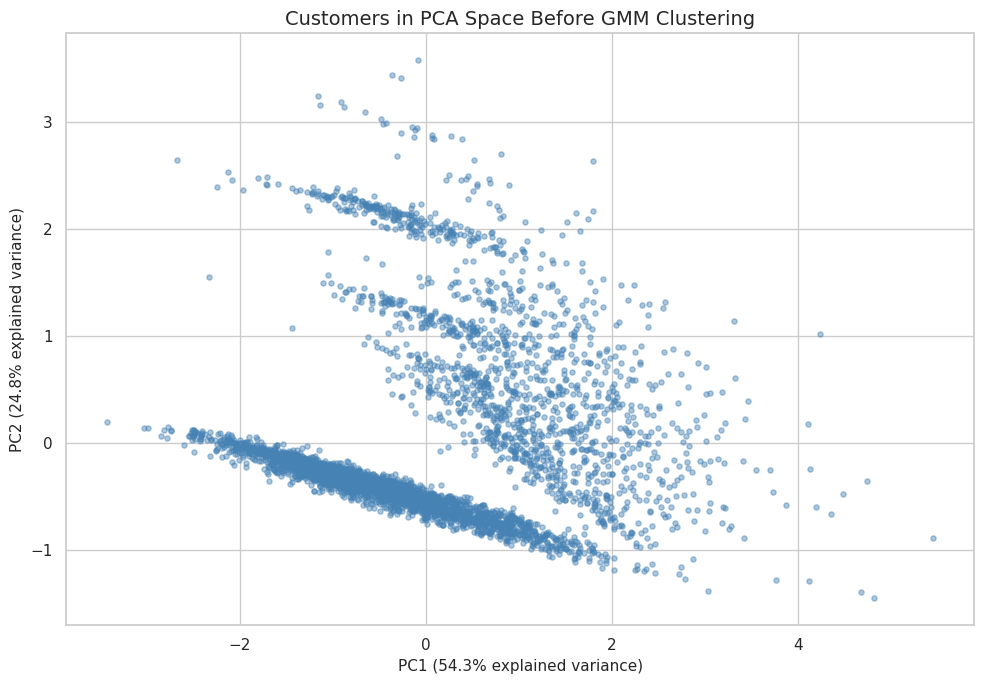

PC1 + PC2 explain 79.04% of total variance.


In [153]:

# PCA projection for later visualisation


pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_gmm_array)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X_gmm.index
)

pca_variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    s=14,
    alpha=0.45,
    color="steelblue"
)

plt.title("Customers in PCA Space Before GMM Clustering")
plt.xlabel(f"PC1 ({pca_variance[0]:.1f}% explained variance)")
plt.ylabel(f"PC2 ({pca_variance[1]:.1f}% explained variance)")
plt.tight_layout()

plt.savefig(
    os.path.join(GMM_DIR, "gmm_pca_before_clustering.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"PC1 + PC2 explain {pca_variance.sum():.2f}% "
    "of total variance."
)

Train GMM candidates

In [154]:

#  Fit GMM candidates from k=2 through k=8

K_VALUES = range(2, 9)

GMM_N_INIT = 10
GMM_MAX_ITER = 500
GMM_REG_COVAR = 1e-5
GMM_COVARIANCE_TYPE = "full"

gmm_models = {}
gmm_labels = {}
gmm_probabilities = {}
gmm_results = []

for k in K_VALUES:
    gmm_model = GaussianMixture(
        n_components=k,
        covariance_type=GMM_COVARIANCE_TYPE,
        n_init=GMM_N_INIT,
        max_iter=GMM_MAX_ITER,
        reg_covar=GMM_REG_COVAR,
        random_state=RANDOM_STATE
    )

    labels = gmm_model.fit_predict(X_gmm_array)
    probabilities = gmm_model.predict_proba(X_gmm_array)

    cluster_counts = pd.Series(labels).value_counts().sort_index()
    cluster_percentages = cluster_counts / len(labels) * 100

    gmm_models[k] = gmm_model
    gmm_labels[k] = labels
    gmm_probabilities[k] = probabilities

    gmm_results.append({
        "Clusters": k,
        "BIC": gmm_model.bic(X_gmm_array),
        "AIC": gmm_model.aic(X_gmm_array),
        "LogLikelihood": (
            gmm_model.score(X_gmm_array) * len(X_gmm_array)
        ),
        "Silhouette": silhouette_score(
            X_gmm_array,
            labels
        ),
        "DaviesBouldin": davies_bouldin_score(
            X_gmm_array,
            labels
        ),
        "CalinskiHarabasz": calinski_harabasz_score(
            X_gmm_array,
            labels
        ),
        "SmallestClusterN": cluster_counts.min(),
        "SmallestClusterPct": cluster_percentages.min(),
        "LargestClusterN": cluster_counts.max(),
        "LargestClusterPct": cluster_percentages.max(),
        "Converged": gmm_model.converged_,
        "Iterations": gmm_model.n_iter_
    })

gmm_results_df = (
    pd.DataFrame(gmm_results)
    .sort_values("Clusters")
    .reset_index(drop=True)
)

display(gmm_results_df.round(4))

gmm_results_df.to_csv(
    os.path.join(GMM_DIR, "gmm_model_comparison.csv"),
    index=False
)

print("Candidate GMM models completed and saved.")

,Clusters,BIC,AIC,LogLikelihood,Silhouette,DaviesBouldin,CalinskiHarabasz,SmallestClusterN,SmallestClusterPct,LargestClusterN,LargestClusterPct,Converged,Iterations
0,2,6972.4772,6711.0952,-3314.5476,0.3302,1.3624,1886.4497,1564,36.0535,2774,63.9465,True,10
1,3,-3555.6688,-3950.9293,2037.4646,0.1801,1.5052,1460.5690,1282,29.5528,1564,36.0535,True,17
2,4,-4792.8162,-5321.9552,2743.9776,0.1828,1.4767,1361.7524,570,13.1397,1492,34.3937,True,39
3,5,-7957.4344,-8620.4520,4414.2260,0.1332,1.8193,1146.3522,343,7.9069,1493,34.4168,True,28
4,6,-11420.3607,-12217.2568,6233.6284,0.1044,2.0226,1044.6917,286,6.5929,1282,29.5528,True,27
5,7,-9997.3852,-10928.1598,5610.0799,0.1037,2.0008,832.0515,149,3.4348,1496,34.4859,True,23
6,8,-13290.6254,-14355.2786,7344.6393,0.0716,2.4322,815.2413,200,4.6104,1282,29.5528,True,24


Candidate GMM models completed and saved.


choose k=4

Select final k

In [155]:

FINAL_K = 4

if FINAL_K not in gmm_models:
    raise ValueError(
        f"FINAL_K must be one of {list(K_VALUES)}. "
        f"You entered {FINAL_K}."
    )

final_gmm = gmm_models[FINAL_K]
final_labels = gmm_labels[FINAL_K]
final_probabilities = gmm_probabilities[FINAL_K]

final_model_metrics = (
    gmm_results_df
    .loc[gmm_results_df["Clusters"] == FINAL_K]
    .copy()
)

print(f"Final GMM selected: k = {FINAL_K}")
print("Reason: strong BIC improvement, best Davies-Bouldin among")
print("practical multi-segment solutions, and no undersized cluster.")
print("Converged:", final_gmm.converged_)
print("Iterations:", final_gmm.n_iter_)

display(final_model_metrics.round(4))

Final GMM selected: k = 4
Reason: strong BIC improvement, best Davies-Bouldin among
practical multi-segment solutions, and no undersized cluster.
Converged: True
Iterations: 39


,Clusters,BIC,AIC,LogLikelihood,Silhouette,DaviesBouldin,CalinskiHarabasz,SmallestClusterN,SmallestClusterPct,LargestClusterN,LargestClusterPct,Converged,Iterations
2,4,-4792.8162,-5321.9552,2743.9776,0.1828,1.4767,1361.7524,570,13.1397,1492,34.3937,True,39


Gaussian Mixture Models with 2 to 8 components were evaluated using BIC, AIC, silhouette score, Davies–Bouldin index, Calinski–Harabasz index, convergence, and cluster-size balance. Although the two-component model achieved the highest silhouette score (0.3302), it was too coarse for actionable customer segmentation. A four-component GMM was selected because it substantially improved BIC to -4792.82, achieved the lowest Davies–Bouldin index among the practical multi-cluster solutions (1.4767), converged successfully, and retained a minimum segment size of 570 customers (13.14%).

 Final assignments and probability confidenc

In [156]:

# Final assignments and probability confidence


gmm_assignments = customer_profiles.copy()

gmm_assignments["GMM_Cluster"] = final_labels
gmm_assignments["GMM_MaxProbability"] = (
    final_probabilities.max(axis=1)
)

sorted_probabilities = np.sort(
    final_probabilities,
    axis=1
)

gmm_assignments["GMM_SecondProbability"] = (
    sorted_probabilities[:, -2]
)

gmm_assignments["GMM_ProbabilityGap"] = (
    gmm_assignments["GMM_MaxProbability"]
    - gmm_assignments["GMM_SecondProbability"]
)

for cluster_number in range(FINAL_K):
    gmm_assignments[
        f"GMM_Probability_Cluster_{cluster_number}"
    ] = final_probabilities[:, cluster_number]

assert len(gmm_assignments) == len(X_gmm), (
    "Assignments do not match the number of GMM customers."
)

assert gmm_assignments["CustomerID"].is_unique, (
    "CustomerID must remain unique after assignment."
)

display(gmm_assignments.head())

,CustomerID,FirstPurchaseDate,LastPurchaseDate,InvoiceFrequency,TotalRevenue,TotalQuantity,RecencyDays,CustomerTenureDays,AvgRevenuePerInvoice,AvgQuantityPerInvoice,...,TotalInvoicesObserved,CancellationRate,GMM_Cluster,GMM_MaxProbability,GMM_SecondProbability,GMM_ProbabilityGap,GMM_Probability_Cluster_0,GMM_Probability_Cluster_1,GMM_Probability_Cluster_2,GMM_Probability_Cluster_3
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,326,0,77183.600000,74215.000000,...,2,0.5,2,0.999988,0.000012,0.999977,0.000000,1.172603e-05,9.999883e-01,0.000000
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,4310.00,2458,2,365,615.714286,351.142857,...,7,0.0,0,0.998411,0.000942,0.997468,0.998411,6.472072e-04,9.422369e-04,0.000000
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,1797.24,2341,75,282,449.310000,585.250000,...,4,0.0,0,0.999970,0.000030,0.999941,0.999970,2.952931e-05,1.045949e-36,0.000000
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,631,19,0,1757.550000,631.000000,...,1,0.0,3,0.998934,0.001066,0.997869,0.001066,2.603574e-09,2.566001e-252,0.998934
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,310,0,334.400000,197.000000,...,1,0.0,3,0.998408,0.001592,0.996815,0.001592,1.289642e-09,6.341718e-257,0.998408


Segment size and confidence

,GMM_Cluster,Customers,Percent
0,0,1492,34.39
1,1,994,22.91
2,2,570,13.14
3,3,1282,29.55


,GMM_Cluster,Customers,MeanMaxProbability,MedianMaxProbability,MeanProbabilityGap,MinMaxProbability
0,0,1492,0.997,1.000,0.995,0.517
1,1,994,0.998,1.000,0.996,0.552
2,2,570,0.890,0.927,0.780,0.544
3,3,1282,0.998,0.998,0.997,0.992


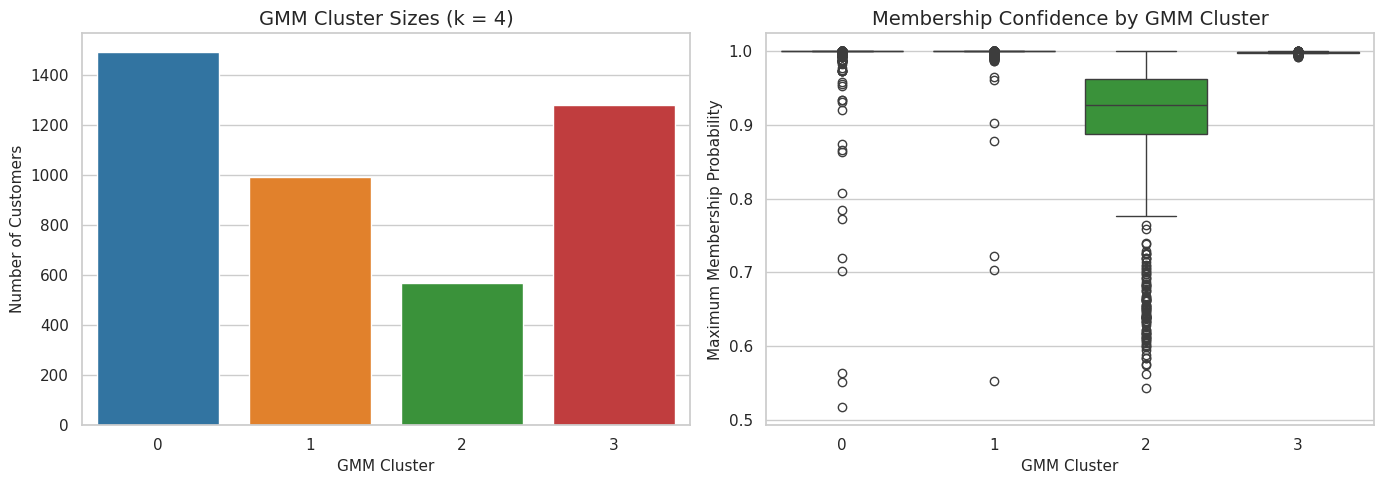

In [157]:


gmm_cluster_sizes = (
    gmm_assignments["GMM_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("GMM_Cluster")
    .reset_index(name="Customers")
)

gmm_cluster_sizes["Percent"] = (
    gmm_cluster_sizes["Customers"]
    / gmm_cluster_sizes["Customers"].sum()
    * 100
)

gmm_cluster_confidence = (
    gmm_assignments
    .groupby("GMM_Cluster")
    .agg(
        Customers=("CustomerID", "size"),
        MeanMaxProbability=("GMM_MaxProbability", "mean"),
        MedianMaxProbability=("GMM_MaxProbability", "median"),
        MeanProbabilityGap=("GMM_ProbabilityGap", "mean"),
        MinMaxProbability=("GMM_MaxProbability", "min")
    )
    .reset_index()
)

display(gmm_cluster_sizes.round(2))
display(gmm_cluster_confidence.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=gmm_cluster_sizes,
    x="GMM_Cluster",
    y="Customers",
    palette="tab10",
    ax=axes[0]
)

axes[0].set_title(f"GMM Cluster Sizes (k = {FINAL_K})")
axes[0].set_xlabel("GMM Cluster")
axes[0].set_ylabel("Number of Customers")

sns.boxplot(
    data=gmm_assignments,
    x="GMM_Cluster",
    y="GMM_MaxProbability",
    palette="tab10",
    ax=axes[1]
)

axes[1].set_title("Membership Confidence by GMM Cluster")
axes[1].set_xlabel("GMM Cluster")
axes[1].set_ylabel("Maximum Membership Probability")

plt.tight_layout()

plt.savefig(
    os.path.join(
        GMM_DIR,
        f"gmm_cluster_sizes_confidence_k{FINAL_K}.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Business profiles

In [158]:

#  Profile clusters in original business units

PROFILE_FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

available_profile_features = [
    feature for feature in PROFILE_FEATURES
    if feature in gmm_assignments.columns
]

gmm_profile_mean = (
    gmm_assignments
    .groupby("GMM_Cluster")[available_profile_features]
    .mean()
    .round(2)
)

gmm_profile_median = (
    gmm_assignments
    .groupby("GMM_Cluster")[available_profile_features]
    .median()
    .round(2)
)

gmm_profile_summary = (
    gmm_assignments
    .groupby("GMM_Cluster")
    .agg(
        Customers=("CustomerID", "size"),
        MeanRecencyDays=("RecencyDays", "mean"),
        MedianRecencyDays=("RecencyDays", "median"),
        MeanInvoiceFrequency=("InvoiceFrequency", "mean"),
        MedianInvoiceFrequency=("InvoiceFrequency", "median"),
        MeanTotalRevenue=("TotalRevenue", "mean"),
        MedianTotalRevenue=("TotalRevenue", "median"),
        MeanUniqueProducts=("UniqueProducts", "mean"),
        MedianUniqueProducts=("UniqueProducts", "median"),
        MeanCancellationRate=("CancellationRate", "mean")
    )
    .round(2)
)

print("Cluster mean profiles:")
display(gmm_profile_mean)

print("Cluster median profiles:")
display(gmm_profile_median)

print("Detailed business profile:")
display(gmm_profile_summary)

gmm_profile_mean.to_csv(
    os.path.join(
        GMM_DIR,
        f"gmm_cluster_profile_mean_k{FINAL_K}.csv"
    )
)

gmm_profile_median.to_csv(
    os.path.join(
        GMM_DIR,
        f"gmm_cluster_profile_median_k{FINAL_K}.csv"
    )
)

gmm_profile_summary.to_csv(
    os.path.join(
        GMM_DIR,
        f"gmm_cluster_profile_summary_k{FINAL_K}.csv"
    )
)

Cluster mean profiles:


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
GMM_Cluster,,,,,
0,67.77,3.66,1193.72,61.52,0.00
1,40.41,10.57,5913.32,123.50,0.26
2,109.16,2.25,1418.26,42.28,0.35
3,154.38,1.00,346.43,21.51,0.00


Cluster median profiles:


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
GMM_Cluster,,,,,
0,39.0,3.0,782.94,44.0,0.00
1,19.0,7.0,2550.79,89.5,0.24
2,68.0,2.0,652.53,30.0,0.33
3,128.0,1.0,241.36,15.0,0.00


Detailed business profile:


,Customers,MeanRecencyDays,MedianRecencyDays,MeanInvoiceFrequency,MedianInvoiceFrequency,MeanTotalRevenue,MedianTotalRevenue,MeanUniqueProducts,MedianUniqueProducts,MeanCancellationRate
GMM_Cluster,,,,,,,,,,
0,1492,67.77,39.0,3.66,3.0,1193.72,782.94,61.52,44.0,0.00
1,994,40.41,19.0,10.57,7.0,5913.32,2550.79,123.50,89.5,0.26
2,570,109.16,68.0,2.25,2.0,1418.26,652.53,42.28,30.0,0.35
3,1282,154.38,128.0,1.00,1.0,346.43,241.36,21.51,15.0,0.00


 Profile heatmap

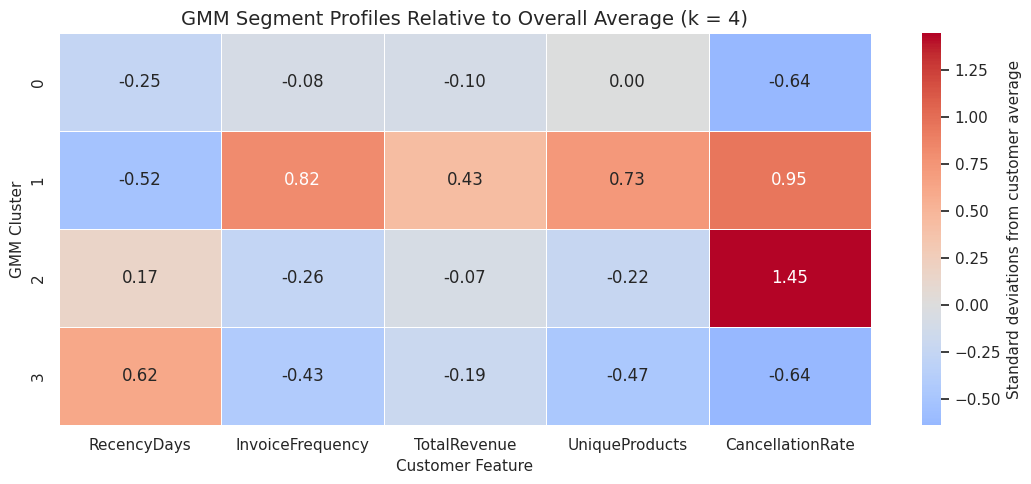

In [159]:

# Standardised heatmap for segment comparison

profile_for_heatmap = (
    gmm_assignments
    .groupby("GMM_Cluster")[available_profile_features]
    .mean()
)

profile_standardised = (
    profile_for_heatmap
    - customer_profiles[available_profile_features].mean()
) / customer_profiles[available_profile_features].std()

plt.figure(figsize=(11, 5))

sns.heatmap(
    profile_standardised,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standard deviations from customer average"}
)

plt.title(
    f"GMM Segment Profiles Relative to Overall Average (k = {FINAL_K})"
)
plt.xlabel("Customer Feature")
plt.ylabel("GMM Cluster")
plt.tight_layout()

plt.savefig(
    os.path.join(
        GMM_DIR,
        f"gmm_profile_heatmap_k{FINAL_K}.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PCA cluster visualization

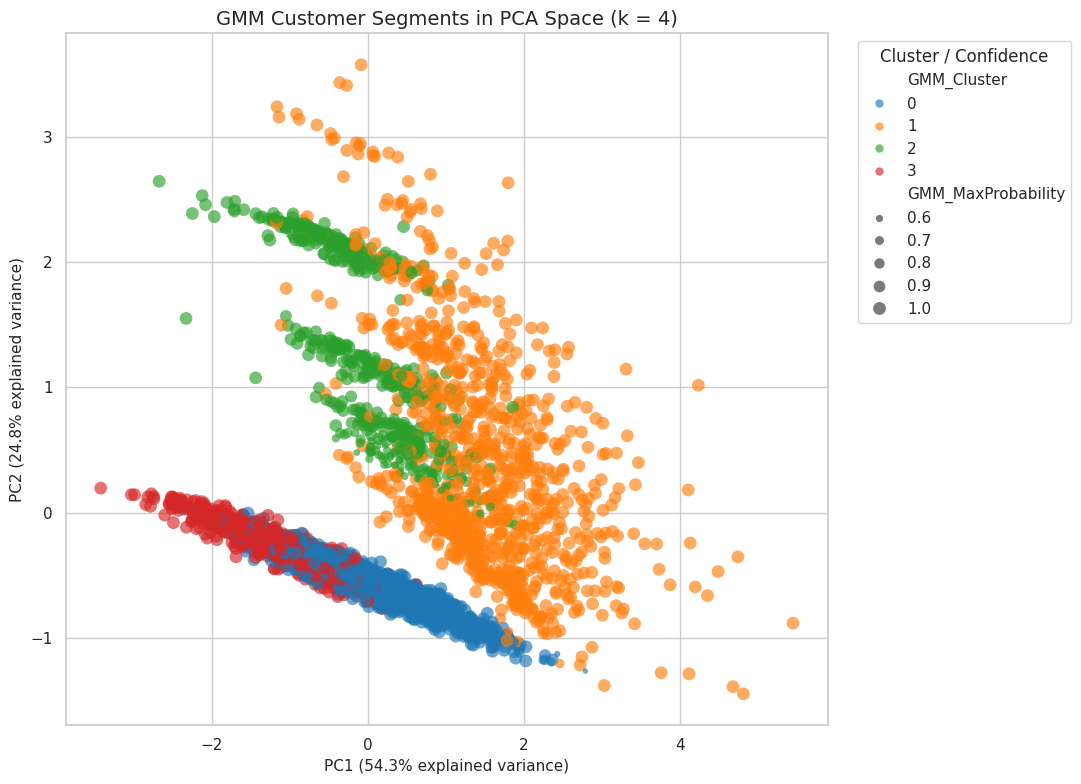

In [160]:


gmm_pca_plot = pca_df.copy()
gmm_pca_plot["GMM_Cluster"] = final_labels
gmm_pca_plot["GMM_MaxProbability"] = (
    gmm_assignments["GMM_MaxProbability"].to_numpy()
)

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=gmm_pca_plot,
    x="PC1",
    y="PC2",
    hue="GMM_Cluster",
    size="GMM_MaxProbability",
    sizes=(15, 85),
    palette="tab10",
    alpha=0.65,
    linewidth=0
)

plt.title(f"GMM Customer Segments in PCA Space (k = {FINAL_K})")
plt.xlabel(f"PC1 ({pca_variance[0]:.1f}% explained variance)")
plt.ylabel(f"PC2 ({pca_variance[1]:.1f}% explained variance)")
plt.legend(
    title="Cluster / Confidence",
    bbox_to_anchor=(1.03, 1),
    loc="upper left"
)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GMM_DIR,
        f"gmm_pca_clusters_k{FINAL_K}.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

 Stability across seeds

In [161]:

STABILITY_SEEDS = [7, 19, 42, 73, 101, 202, 303, 404, 505, 606]

stability_rows = []

for seed in STABILITY_SEEDS:
    seed_model = GaussianMixture(
        n_components=FINAL_K,
        covariance_type=GMM_COVARIANCE_TYPE,
        n_init=GMM_N_INIT,
        max_iter=GMM_MAX_ITER,
        reg_covar=GMM_REG_COVAR,
        random_state=seed
    )

    seed_labels = seed_model.fit_predict(X_gmm_array)

    stability_rows.append({
        "Seed": seed,
        "AdjustedRandIndexVsFinal": adjusted_rand_score(
            final_labels,
            seed_labels
        ),
        "BIC": seed_model.bic(X_gmm_array),
        "Converged": seed_model.converged_,
        "Iterations": seed_model.n_iter_
    })

gmm_stability_df = pd.DataFrame(stability_rows)

display(gmm_stability_df.round(4))

print(
    "Mean ARI against final model:",
    round(
        gmm_stability_df["AdjustedRandIndexVsFinal"].mean(),
        4
    )
)

print(
    "Minimum ARI against final model:",
    round(
        gmm_stability_df["AdjustedRandIndexVsFinal"].min(),
        4
    )
)

gmm_stability_df.to_csv(
    os.path.join(
        GMM_DIR,
        f"gmm_stability_k{FINAL_K}.csv"
    ),
    index=False
)

,Seed,AdjustedRandIndexVsFinal,BIC,Converged,Iterations
0,7,0.8647,-4400.2491,True,36
1,19,0.8647,-4400.2491,True,36
2,42,1.0000,-4792.8162,True,39
3,73,0.8647,-4400.1914,True,36
4,101,1.0000,-4793.2160,True,39
5,202,1.0000,-4793.1587,True,39
6,303,0.8647,-4400.2491,True,36
7,404,0.8647,-4400.2491,True,36
8,505,0.8647,-4400.2285,True,36
9,606,1.0000,-4793.1257,True,39


Mean ARI against final model: 0.9188
Minimum ARI against final model: 0.8647


| GMM segment                      | Customers | Share  | Behavioural interpretation                                                                                                                                                           | Recommended action                                                                                                                                                                            |
| -------------------------------- | --------- | ------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 0 — Active standard customers    | 1,492     | 34.39% | Moderate recency (median 39 days), 3 median invoices, median revenue 782.94, 44 products, and essentially no cancellations.                                                          | Use regular personalised recommendations, replenishment reminders, and modest cross-sell bundles.                                                                                             |
| 1 — High-value engaged customers | 994       | 22.91% | Most recent group (median 19 days), highest purchase frequency (median 7 invoices), highest median revenue (2,550.79), broadest range (89.5 products), and a 0.24 cancellation rate. | Prioritise loyalty benefits, early access, VIP service, and tailored high-value bundles; monitor returns rather than treating every cancellation as poor value.                               |
| 2 — Cancellation-prone customers | 570       | 13.14% | Older activity than Segments 0–1 (median 68 days), low purchase frequency (median 2), moderate revenue (652.53), and the highest cancellation rate (0.33).                           | Investigate cancellation drivers: fulfilment quality, stock availability, delivery cost, product expectation, and return friction; avoid aggressive promotions until the cause is understood. |
| 3 — Lapsed low-value customers   | 1,282     | 29.55% | Least recent group (median 128 days), typically one invoice, lowest median revenue (241.36), fewest products (15), and no cancellation issue.                                        | Use low-cost reactivation campaigns, a time-limited offer, and email-based win-back; suppress after non-response to reduce marketing spend.                                                   |

A Gaussian Mixture Model (GMM) was fitted to 4,338 customers using five scaled behavioural features: RecencyDays, InvoiceFrequency, TotalRevenue, UniqueProducts, and CancellationRate. The four-component solution was selected after comparison of models with two to eight components. Although the two-component model produced the highest silhouette score (0.3302), it represented an overly broad segmentation. The four-component model gave a lower BIC (-4792.82) than the two- and three-component alternatives, the lowest Davies–Bouldin index among practical multi-cluster GMM solutions (1.4767), successful convergence, and no impractically small segment; the smallest group contained 570 customers, or 13.14% of the customer base.

The resulting segments were commercially interpretable: active standard customers (34.39%), high-value engaged customers (22.91%), cancellation-prone customers (13.14%), and lapsed low-value customers (29.55%). The high-value engaged segment was the most recent and valuable, while the lapsed low-value segment had the oldest purchase recency and lowest spending. The cancellation-prone segment showed the highest cancellation rate and should be investigated operationally before applying intensive retention promotions.

The GMM was highly stable rather than perfectly invariant. Four seeds produced an identical partition to the final model (ARI = 1.0000), while six seeds produced a closely related local optimum (ARI = 0.8647). The mean ARI of 0.9188 confirms strong overall reproducibility.

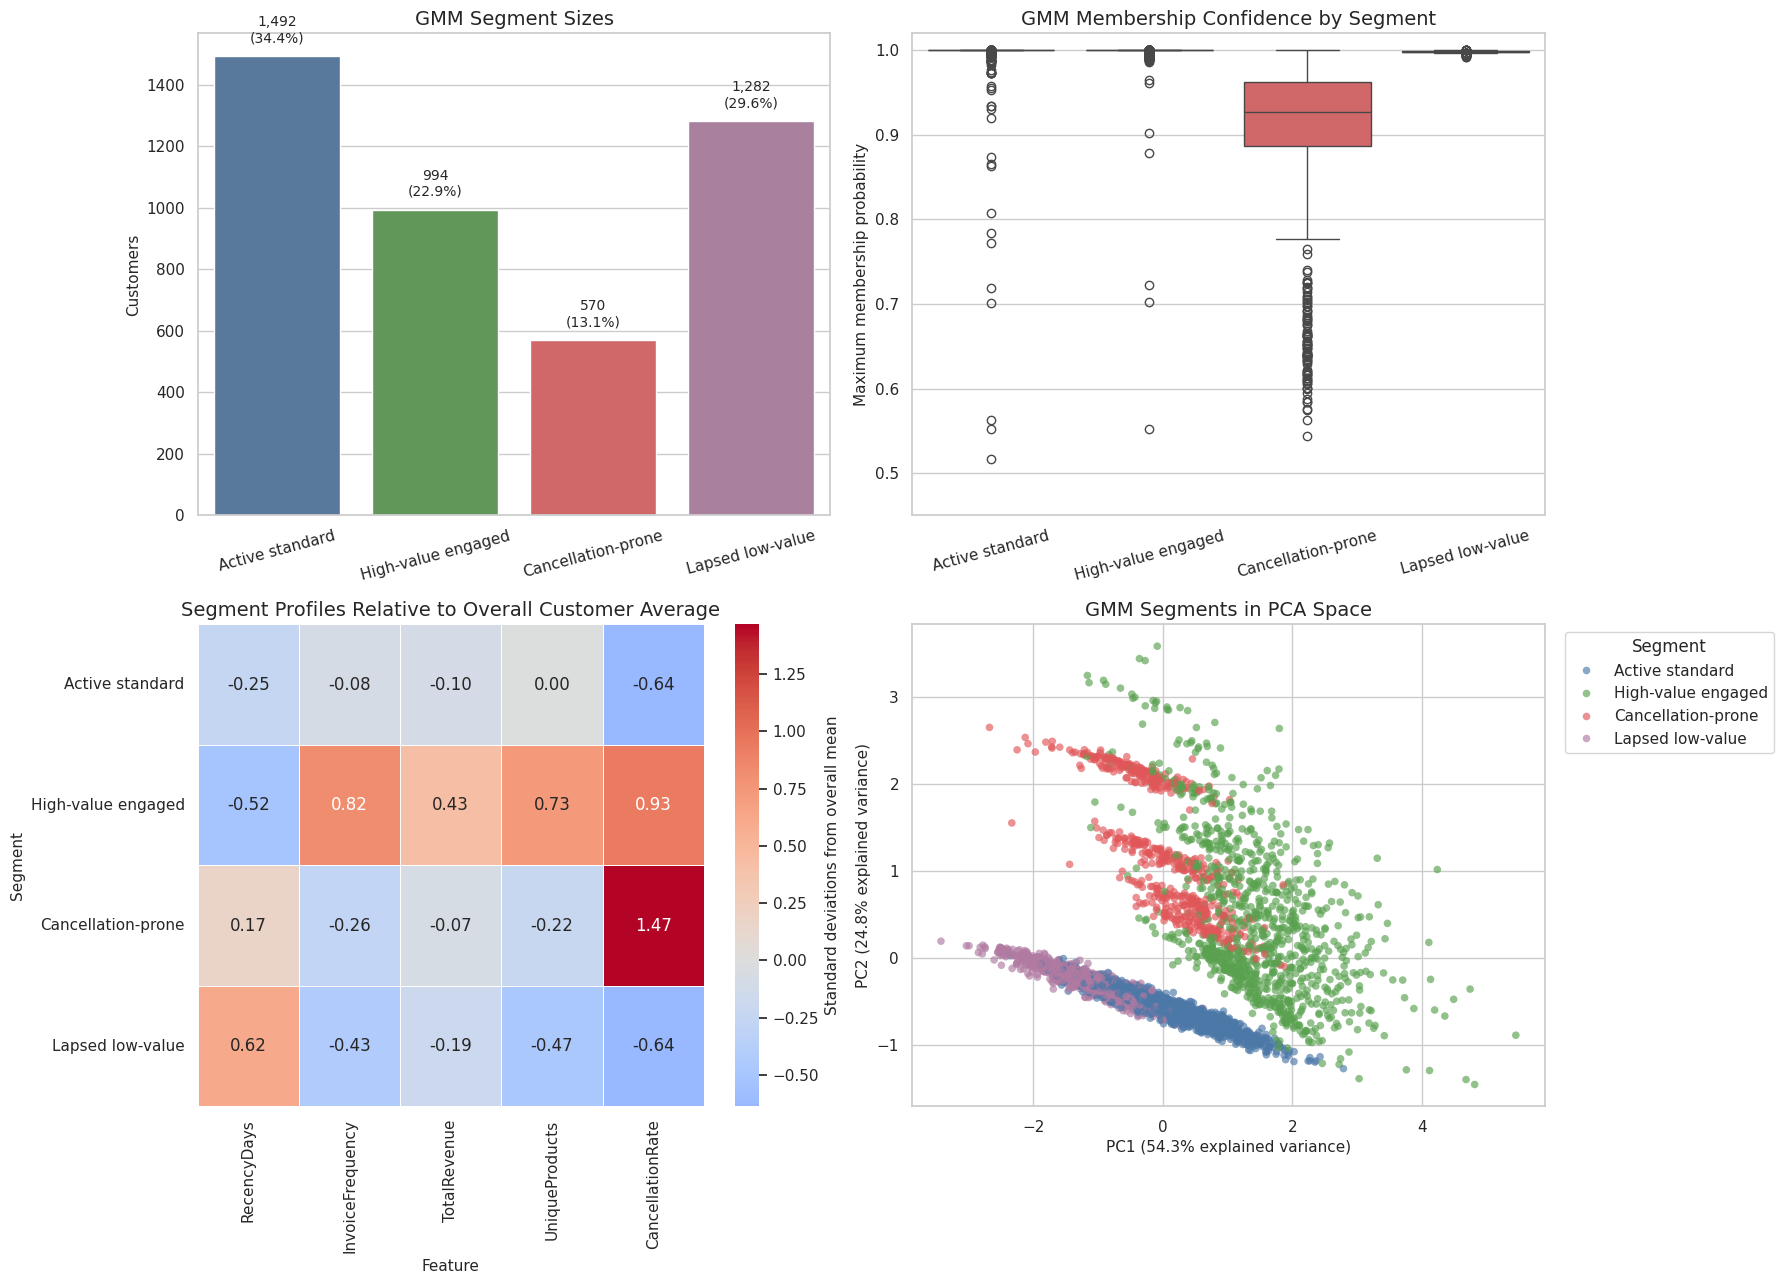

Saved: /content/drive/MyDrive/ML Project/project_outputs/pre_process/gmm_outputs/gmm_final_summary_k4.png


In [162]:
# ============================================================
# GMM VISUAL SUMMARY: profiles, size, confidence, PCA
# Requires:
# gmm_assignments, gmm_cluster_sizes, gmm_pca_plot,
# gmm_profile_mean, FINAL_K, GMM_DIR, pca_variance
# ============================================================

segment_names = {
    0: "Active standard",
    1: "High-value engaged",
    2: "Cancellation-prone",
    3: "Lapsed low-value"
}

plot_data = gmm_assignments.copy()
plot_data["Segment"] = plot_data["GMM_Cluster"].map(segment_names)

size_plot = gmm_cluster_sizes.copy()
size_plot["Segment"] = size_plot["GMM_Cluster"].map(segment_names)

profile_plot = gmm_profile_mean.copy()
profile_plot.index = profile_plot.index.map(segment_names)

heatmap_features = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

overall_means = customer_profiles[heatmap_features].mean()
overall_stds = customer_profiles[heatmap_features].std()

profile_z = (
    profile_plot[heatmap_features] - overall_means
) / overall_stds

pca_plot = gmm_pca_plot.copy()
pca_plot["Segment"] = pca_plot["GMM_Cluster"].map(segment_names)

segment_order = [
    "Active standard",
    "High-value engaged",
    "Cancellation-prone",
    "Lapsed low-value"
]

palette = {
    "Active standard": "#4C78A8",
    "High-value engaged": "#59A14F",
    "Cancellation-prone": "#E15759",
    "Lapsed low-value": "#B07AA1"
}

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# 1. Segment sizes
sns.barplot(
    data=size_plot,
    x="Segment",
    y="Customers",
    hue="Segment",
    palette=palette,
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title("GMM Segment Sizes")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Customers")
axes[0, 0].tick_params(axis="x", rotation=15)

for index, row in size_plot.iterrows():
    axes[0, 0].text(
        index,
        row["Customers"] + 35,
        f'{row["Customers"]:,}\n({row["Percent"]:.1f}%)',
        ha="center",
        va="bottom",
        fontsize=10
    )

# 2. Membership confidence
sns.boxplot(
    data=plot_data,
    x="Segment",
    y="GMM_MaxProbability",
    order=segment_order,
    hue="Segment",
    palette=palette,
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("GMM Membership Confidence by Segment")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Maximum membership probability")
axes[0, 1].set_ylim(0.45, 1.02)
axes[0, 1].tick_params(axis="x", rotation=15)

# 3. Relative business-profile heatmap
sns.heatmap(
    profile_z.loc[segment_order],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standard deviations from overall mean"},
    ax=axes[1, 0]
)

axes[1, 0].set_title("Segment Profiles Relative to Overall Customer Average")
axes[1, 0].set_xlabel("Feature")
axes[1, 0].set_ylabel("Segment")

# 4. PCA view
sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Segment",
    hue_order=segment_order,
    palette=palette,
    alpha=0.65,
    s=30,
    linewidth=0,
    ax=axes[1, 1]
)

axes[1, 1].set_title("GMM Segments in PCA Space")
axes[1, 1].set_xlabel(
    f"PC1 ({pca_variance[0]:.1f}% explained variance)"
)
axes[1, 1].set_ylabel(
    f"PC2 ({pca_variance[1]:.1f}% explained variance)"
)
axes[1, 1].legend(
    title="Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

summary_plot_path = os.path.join(
    GMM_DIR,
    f"gmm_final_summary_k{FINAL_K}.png"
)

plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", summary_plot_path)

# Primary Lens Customer Segmentation Model performance analysis - IT24101861 Gamage K.T.P

In [163]:
# ============================================================
# RECREATE THE PREPROCESSED CLUSTERING MATRIX
# Run this BEFORE the all-model comparison code
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# Your five final clustering features
MODEL_FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts",
    "CancellationRate"
]

# Candidate names from your earlier cells/notebook
possible_customer_dataframes = [
    "customer_profiles",
    "customerfeatures",
    "customer_features",
    "customerall",
    "customereda"
]

customer_df = None

for dataframe_name in possible_customer_dataframes:
    if dataframe_name in globals():
        candidate_df = globals()[dataframe_name]

        if set(MODEL_FEATURES).issubset(candidate_df.columns):
            customer_df = candidate_df.copy()
            print(f"Using dataframe: {dataframe_name}")
            break

if customer_df is None:
    raise NameError(
        "Could not find a customer-level dataframe containing all "
        "required columns. Run your customer feature-engineering cell "
        "first, then rerun this cell."
    )

# Keep only customers with complete clustering information
customer_df = customer_df.dropna(
    subset=MODEL_FEATURES
).copy()

# Retain CustomerID as index if it exists
if "CustomerID" in customer_df.columns:
    customer_df["CustomerID"] = customer_df["CustomerID"].astype(int)
    customer_df = customer_df.set_index("CustomerID", drop=False)

# Create raw five-feature matrix
X_original = customer_df[MODEL_FEATURES].copy()

# Apply log1p to the four non-negative, heavily skewed features
LOG_FEATURES = [
    "RecencyDays",
    "InvoiceFrequency",
    "TotalRevenue",
    "UniqueProducts"
]

X_log = X_original.copy()

for feature in LOG_FEATURES:
    if (X_log[feature] < 0).any():
        raise ValueError(
            f"{feature} contains negative values, so log1p cannot be applied."
        )

    X_log[feature] = np.log1p(X_log[feature])

# Robust scaling for fair distance-based clustering
scaler = RobustScaler()

Xpreprocessed = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=MODEL_FEATURES,
    index=X_log.index
)

# Aliases that make the comparison code easier to read
X_compare = Xpreprocessed.copy()
X_array = Xpreprocessed.to_numpy()

print("\nPreprocessed matrix created successfully.")
print("Shape:", Xpreprocessed.shape)
print("Expected shape: (4338, 5)")
display(Xpreprocessed.head())

Using dataframe: customer_profiles

Preprocessed matrix created successfully.
Shape: (4338, 5)
Expected shape: (4338, 5)


,RecencyDays,InvoiceFrequency,TotalRevenue,UniqueProducts,CancellationRate
CustomerID,,,,,
12346,0.910975,-0.369070,2.812555,-1.897197,2.5
12347,-1.413309,0.892789,1.100143,0.696341,0.0
12348,0.188015,0.464974,0.581165,-0.323254,0.0
12349,-0.473399,-0.369070,0.567918,0.464025,0.0
12350,0.886120,-0.369070,-0.415549,-0.492490,0.0


In [164]:

# UNIFIED CLUSTERING MODEL COMPARISON
# K-Means, Hierarchical, DBSCAN, and Gaussian Mixture Models


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

RANDOM_STATE = 42
K_VALUES = range(2, 9)

# Use the exact same processed feature matrix for every method
X_compare = Xpreprocessed.copy()
X_array = X_compare.to_numpy()

# Save outputs in one place
MODEL_COMPARE_DIR = os.path.join(
    GMM_DIR if "GMM_DIR" in globals() else ".",
    "all_model_comparison"
)
os.makedirs(MODEL_COMPARE_DIR, exist_ok=True)

def calculate_metrics(X, labels, allow_noise=False):
    """
    Calculates internal validation metrics.
    For DBSCAN, noise label -1 is excluded from metric calculations.
    """
    labels = np.asarray(labels)

    if allow_noise:
        valid_mask = labels != -1
        X_eval = X[valid_mask]
        labels_eval = labels[valid_mask]
    else:
        X_eval = X
        labels_eval = labels

    unique_labels = np.unique(labels_eval)

    if len(unique_labels) < 2 or len(X_eval) < 3:
        return {
            "Silhouette": np.nan,
            "DaviesBouldin": np.nan,
            "CalinskiHarabasz": np.nan,
            "EvaluatedCustomers": len(X_eval)
        }

    return {
        "Silhouette": silhouette_score(
            X_eval,
            labels_eval,
            sample_size=min(1500, len(X_eval)),
            random_state=RANDOM_STATE
        ),
        "DaviesBouldin": davies_bouldin_score(X_eval, labels_eval),
        "CalinskiHarabasz": calinski_harabasz_score(X_eval, labels_eval),
        "EvaluatedCustomers": len(X_eval)
    }

def cluster_summary(labels):
    labels = pd.Series(labels)
    non_noise = labels[labels != -1]

    if len(non_noise) == 0:
        return {
            "Clusters": 0,
            "NoiseCustomers": len(labels),
            "NoisePercent": 100.0,
            "SmallestClusterPercent": np.nan,
            "LargestClusterPercent": np.nan
        }

    proportions = non_noise.value_counts(normalize=True) * 100

    return {
        "Clusters": non_noise.nunique(),
        "NoiseCustomers": int((labels == -1).sum()),
        "NoisePercent": round((labels == -1).mean() * 100, 2),
        "SmallestClusterPercent": round(proportions.min(), 2),
        "LargestClusterPercent": round(proportions.max(), 2)
    }

comparison_rows = []
all_labels = {}

# ------------------------------------------------------------
# 1. K-MEANS: test k = 2 to 8
# ------------------------------------------------------------
for k in K_VALUES:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=30
    )

    labels = model.fit_predict(X_array)
    metrics = calculate_metrics(X_array, labels)
    summary = cluster_summary(labels)

    comparison_rows.append({
        "Model": "K-Means",
        "Configuration": f"k={k}",
        "ParameterValue": k,
        "Inertia": model.inertia_,
        "BIC": np.nan,
        **metrics,
        **summary
    })

    all_labels[f"KMeans_k{k}"] = labels

# ------------------------------------------------------------
# 2. HIERARCHICAL: Ward, complete, average linkage
# ------------------------------------------------------------
hierarchical_linkages = ["ward", "complete", "average"]

for linkage in hierarchical_linkages:
    for k in K_VALUES:
        if linkage == "ward":
            model = AgglomerativeClustering(
                n_clusters=k,
                linkage="ward"
            )
        else:
            model = AgglomerativeClustering(
                n_clusters=k,
                linkage=linkage,
                metric="euclidean"
            )

        labels = model.fit_predict(X_array)
        metrics = calculate_metrics(X_array, labels)
        summary = cluster_summary(labels)

        comparison_rows.append({
            "Model": "Hierarchical",
            "Configuration": f"{linkage}, k={k}",
            "ParameterValue": k,
            "Inertia": np.nan,
            "BIC": np.nan,
            **metrics,
            **summary
        })

        all_labels[f"Hierarchical_{linkage}_k{k}"] = labels

# ------------------------------------------------------------
# 3. DBSCAN: grid search
# ------------------------------------------------------------
dbscan_eps_values = np.arange(0.30, 1.51, 0.10)
dbscan_min_samples_values = [5, 10, 15, 20, 30]

for eps in dbscan_eps_values:
    for min_samples in dbscan_min_samples_values:
        model = DBSCAN(
            eps=round(eps, 2),
            min_samples=min_samples,
            metric="euclidean",
            n_jobs=-1
        )

        labels = model.fit_predict(X_array)
        metrics = calculate_metrics(
            X_array,
            labels,
            allow_noise=True
        )
        summary = cluster_summary(labels)

        comparison_rows.append({
            "Model": "DBSCAN",
            "Configuration": (
                f"eps={eps:.2f}, min_samples={min_samples}"
            ),
            "ParameterValue": eps,
            "Inertia": np.nan,
            "BIC": np.nan,
            **metrics,
            **summary
        })

        all_labels[
            f"DBSCAN_eps{eps:.2f}_min{min_samples}"
        ] = labels

# ------------------------------------------------------------
# 4. GMM: full covariance, components 2 to 8
# ------------------------------------------------------------
for k in K_VALUES:
    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=RANDOM_STATE,
        n_init=10,
        max_iter=500,
        reg_covar=1e-6
    )

    labels = model.fit_predict(X_array)
    metrics = calculate_metrics(X_array, labels)
    summary = cluster_summary(labels)

    comparison_rows.append({
        "Model": "GMM",
        "Configuration": f"full covariance, k={k}",
        "ParameterValue": k,
        "Inertia": np.nan,
        "BIC": model.bic(X_array),
        **metrics,
        **summary
    })

    all_labels[f"GMM_k{k}"] = labels

# ------------------------------------------------------------
# Create and save full comparison table
# ------------------------------------------------------------
all_model_results = pd.DataFrame(comparison_rows)

all_model_results = all_model_results[
    [
        "Model",
        "Configuration",
        "Clusters",
        "NoiseCustomers",
        "NoisePercent",
        "SmallestClusterPercent",
        "LargestClusterPercent",
        "Silhouette",
        "DaviesBouldin",
        "CalinskiHarabasz",
        "BIC",
        "Inertia",
        "EvaluatedCustomers"
    ]
]

all_model_results = all_model_results.sort_values(
    by=["Model", "Silhouette"],
    ascending=[True, False],
    na_position="last"
).reset_index(drop=True)

comparison_path = os.path.join(
    MODEL_COMPARE_DIR,
    "all_clustering_model_results.csv"
)

all_model_results.to_csv(comparison_path, index=False)

display(all_model_results.round(4))

print("Saved full model comparison to:")
print(comparison_path)

,Model,Configuration,Clusters,NoiseCustomers,NoisePercent,SmallestClusterPercent,LargestClusterPercent,Silhouette,DaviesBouldin,CalinskiHarabasz,BIC,Inertia,EvaluatedCustomers
0,DBSCAN,"eps=0.70, min_samples=5",2,78,1.80,0.19,99.81,0.4281,0.5864,38.1648,NaN,NaN,4260
1,DBSCAN,"eps=0.50, min_samples=5",2,251,5.79,0.24,99.76,0.3875,0.5745,41.8725,NaN,NaN,4087
2,DBSCAN,"eps=0.50, min_samples=30",2,876,20.19,4.71,95.29,0.3836,0.7576,543.2236,NaN,NaN,3462
3,DBSCAN,"eps=0.50, min_samples=20",2,586,13.51,5.06,94.94,0.3473,0.8328,543.3836,NaN,NaN,3752
4,DBSCAN,"eps=0.50, min_samples=10",2,343,7.91,0.20,99.80,0.3198,0.5674,34.3980,NaN,NaN,3995
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,K-Means,k=4,4,0,0.00,16.23,31.58,0.2917,1.1039,2310.7907,NaN,4392.8036,4338
96,K-Means,k=5,5,0,0.00,9.11,31.14,0.2857,1.2076,2075.1111,NaN,3916.5518,4338
97,K-Means,k=7,7,0,0.00,8.83,20.56,0.2497,1.2041,1831.9726,NaN,3227.6525,4338
98,K-Means,k=6,6,0,0.00,8.85,28.24,0.2479,1.2340,1940.6858,NaN,3524.5224,4338


Saved full model comparison to:
/content/drive/MyDrive/ML Project/project_outputs/pre_process/gmm_outputs/all_model_comparison/all_clustering_model_results.csv


BEST CONFIGURATION FROM EACH CLUSTERING ALGORITHM


,OverallRank,Model,Configuration,Clusters,Silhouette,DaviesBouldin,CalinskiHarabasz,SmallestClusterPercent,LargestClusterPercent,NoisePercent,OverallQualityScore
0,1,K-Means,k=3,3,0.3713,1.0282,2489.6411,16.7589,50.4610,0.0000,0.8047
3,2,GMM,"Full covariance, k=2",2,0.3328,1.3636,1880.4012,35.9843,64.0157,0.0000,0.6052
1,3,Hierarchical,"Ward linkage, k=3",3,0.3131,1.2271,2041.4328,21.3001,46.7958,0.0000,0.5124
2,4,DBSCAN,"eps=0.50, min_samples=20",2,0.3473,0.8328,543.3836,4.3799,82.1116,13.5085,0.3177


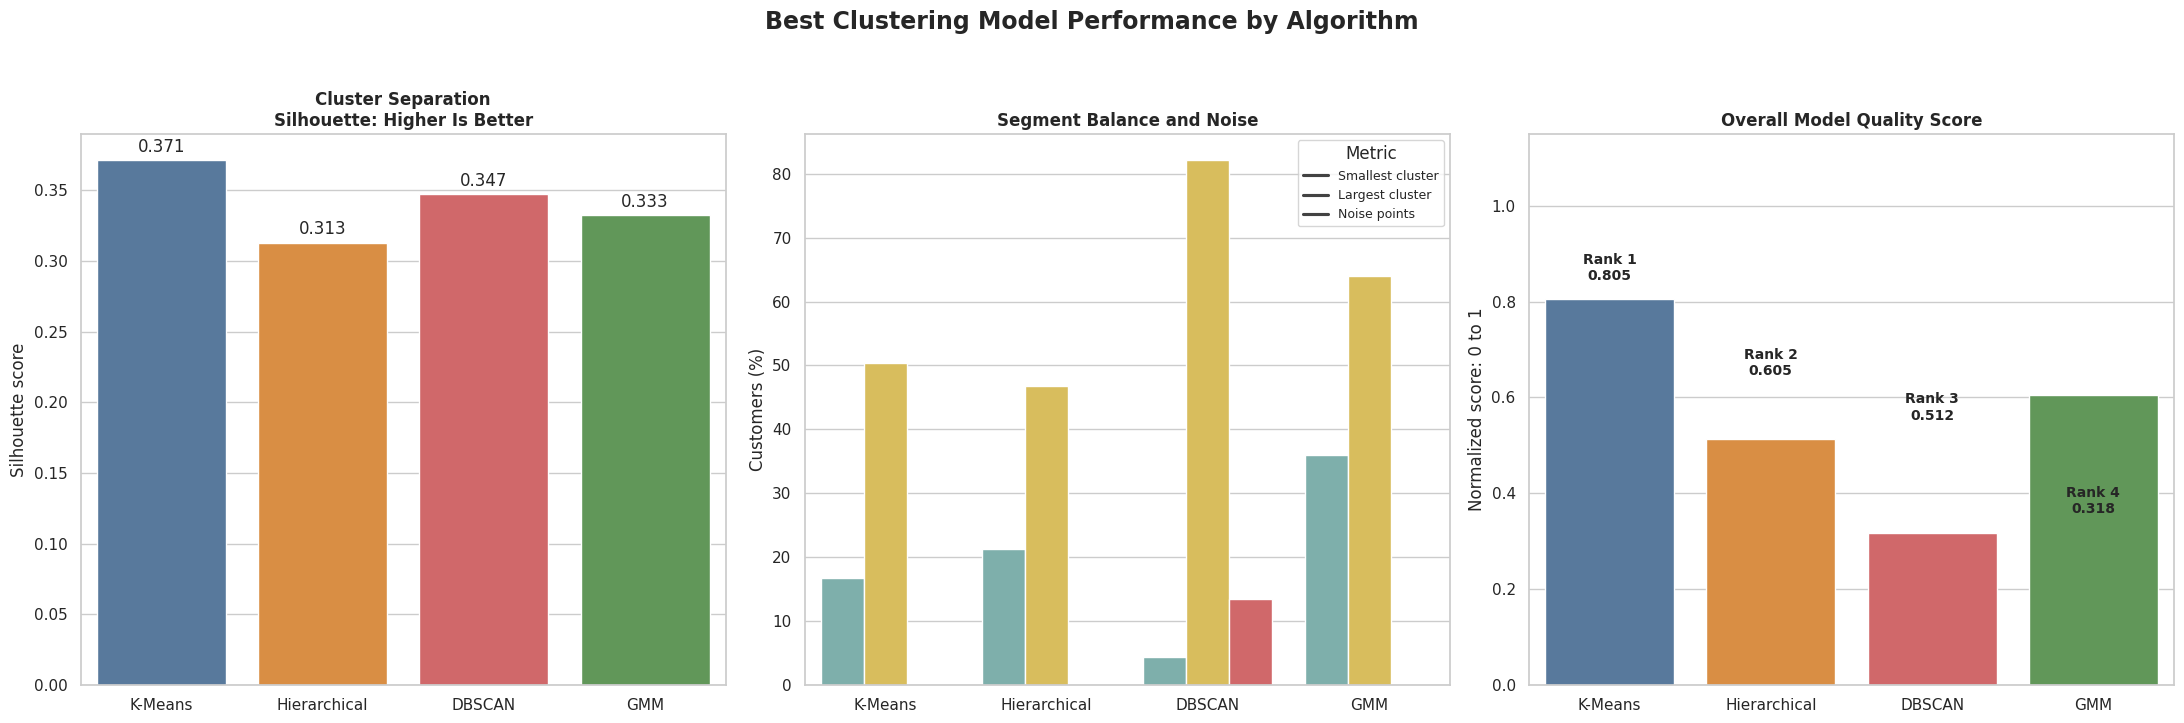


Saved dashboard: clustering_model_comparison/best_clustering_models_dashboard.png


In [165]:
# ============================================================
# BEST-MODEL COMPARISON: K-MEANS, HIERARCHICAL, DBSCAN, GMM
# Creates final_candidates and a report-ready visualization
# Requires: Xpreprocessed
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.preprocessing import MinMaxScaler

# -----------------------------
# 1. Input check
# -----------------------------
if "Xpreprocessed" not in globals():
    raise NameError(
        "Xpreprocessed is not defined. Run the preprocessing-matrix "
        "cell first, then run this cell."
    )

X = Xpreprocessed.to_numpy()
n_customers = len(X)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = "clustering_model_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------
# 2. Evaluation helper function
# -----------------------------
def evaluate_clustering(X, labels, model_name, configuration):
    labels = np.asarray(labels)

    # DBSCAN uses -1 for noise, which must be excluded
    valid_mask = labels != -1
    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]

    unique_clusters = np.unique(labels_valid)
    n_clusters = len(unique_clusters)
    noise_percent = 100 * (~valid_mask).mean()

    # Invalid if fewer than two clusters remain
    if n_clusters < 2 or len(X_valid) < 3:
        return None

    cluster_sizes = pd.Series(labels_valid).value_counts()
    cluster_percentages = cluster_sizes / len(labels) * 100

    return {
        "Model": model_name,
        "Configuration": configuration,
        "Clusters": n_clusters,
        "NoisePercent": noise_percent,
        "SmallestClusterPercent": cluster_percentages.min(),
        "LargestClusterPercent": cluster_percentages.max(),
        "Silhouette": silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(1500, len(X_valid)),
            random_state=RANDOM_STATE
        ),
        "DaviesBouldin": davies_bouldin_score(
            X_valid,
            labels_valid
        ),
        "CalinskiHarabasz": calinski_harabasz_score(
            X_valid,
            labels_valid
        )
    }

# -----------------------------
# 3. Test candidate settings
# -----------------------------
results = []

# K-Means: test k = 2 to 8
for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=30
    )

    labels = model.fit_predict(X)

    result = evaluate_clustering(
        X,
        labels,
        "K-Means",
        f"k={k}"
    )

    if result is not None:
        results.append(result)

# Hierarchical: Ward linkage, k = 2 to 8
for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X)

    result = evaluate_clustering(
        X,
        labels,
        "Hierarchical",
        f"Ward linkage, k={k}"
    )

    if result is not None:
        results.append(result)

# DBSCAN: parameter search
for eps in np.arange(0.30, 1.51, 0.10):
    for min_samples in [5, 10, 15, 20]:
        model = DBSCAN(
            eps=round(eps, 2),
            min_samples=min_samples,
            n_jobs=-1
        )

        labels = model.fit_predict(X)

        result = evaluate_clustering(
            X,
            labels,
            "DBSCAN",
            f"eps={eps:.2f}, min_samples={min_samples}"
        )

        # Retain only useful DBSCAN outputs:
        # at least 2 clusters and no more than 30% noise
        if result is not None and result["NoisePercent"] <= 30:
            results.append(result)

# GMM: components = 2 to 8
for k in range(2, 9):
    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=RANDOM_STATE,
        n_init=10,
        max_iter=500,
        reg_covar=1e-6
    )

    labels = model.fit_predict(X)

    result = evaluate_clustering(
        X,
        labels,
        "GMM",
        f"Full covariance, k={k}"
    )

    if result is not None:
        result["BIC"] = model.bic(X)
        results.append(result)

all_results = pd.DataFrame(results)

# Add BIC column if it is absent for non-GMM entries
if "BIC" not in all_results.columns:
    all_results["BIC"] = np.nan

# -----------------------------
# 4. Select the best from each algorithm
# Criteria:
# - high silhouette
# - low Davies-Bouldin
# - high Calinski-Harabasz
# - avoid tiny clusters (<3%)
# -----------------------------
eligible_results = all_results[
    all_results["SmallestClusterPercent"] >= 3
].copy()

eligible_results["SilhouetteRank"] = eligible_results.groupby(
    "Model"
)["Silhouette"].rank(ascending=False, method="min")

eligible_results["DBRank"] = eligible_results.groupby(
    "Model"
)["DaviesBouldin"].rank(ascending=True, method="min")

eligible_results["CHRank"] = eligible_results.groupby(
    "Model"
)["CalinskiHarabasz"].rank(ascending=False, method="min")

eligible_results["SelectionScore"] = (
    eligible_results["SilhouetteRank"]
    + eligible_results["DBRank"]
    + eligible_results["CHRank"]
)

# One best candidate for K-Means, hierarchical, DBSCAN, GMM
final_candidates = (
    eligible_results
    .sort_values(
        [
            "Model",
            "SelectionScore",
            "Silhouette",
            "DaviesBouldin"
        ],
        ascending=[True, True, False, True]
    )
    .groupby("Model", as_index=False)
    .first()
)

# Ensure a consistent order
model_order = ["K-Means", "Hierarchical", "DBSCAN", "GMM"]

final_candidates["Model"] = pd.Categorical(
    final_candidates["Model"],
    categories=model_order,
    ordered=True
)

final_candidates = final_candidates.sort_values(
    "Model"
).reset_index(drop=True)

# -----------------------------
# 5. Overall standardized score
# All transformed so higher = better
# -----------------------------
metric_input = final_candidates[
    [
        "Silhouette",
        "DaviesBouldin",
        "CalinskiHarabasz",
        "SmallestClusterPercent",
        "NoisePercent"
    ]
].copy()

scaler = MinMaxScaler()

final_candidates["SilhouetteScore"] = scaler.fit_transform(
    metric_input[["Silhouette"]]
)

final_candidates["DaviesBouldinScore"] = 1 - scaler.fit_transform(
    metric_input[["DaviesBouldin"]]
)

final_candidates["CalinskiHarabaszScore"] = scaler.fit_transform(
    metric_input[["CalinskiHarabasz"]]
)

final_candidates["BalanceScore"] = scaler.fit_transform(
    metric_input[["SmallestClusterPercent"]]
)

final_candidates["NoiseScore"] = 1 - scaler.fit_transform(
    metric_input[["NoisePercent"]]
)

final_candidates["OverallQualityScore"] = final_candidates[
    [
        "SilhouetteScore",
        "DaviesBouldinScore",
        "CalinskiHarabaszScore",
        "BalanceScore",
        "NoiseScore"
    ]
].mean(axis=1)

final_candidates["OverallRank"] = (
    final_candidates["OverallQualityScore"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

# -----------------------------
# 6. Display final result table
# -----------------------------
final_report_table = final_candidates[
    [
        "OverallRank",
        "Model",
        "Configuration",
        "Clusters",
        "Silhouette",
        "DaviesBouldin",
        "CalinskiHarabasz",
        "SmallestClusterPercent",
        "LargestClusterPercent",
        "NoisePercent",
        "OverallQualityScore"
    ]
].sort_values("OverallRank")

print("BEST CONFIGURATION FROM EACH CLUSTERING ALGORITHM")
display(final_report_table.round(4))

final_report_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "best_clustering_algorithm_comparison.csv"
    ),
    index=False
)

# -----------------------------
# 7. Create dashboard visualization
# -----------------------------
sns.set_theme(style="whitegrid", context="notebook")

model_colours = {
    "K-Means": "#4C78A8",
    "Hierarchical": "#F28E2B",
    "DBSCAN": "#E15759",
    "GMM": "#59A14F"
}

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# Panel 1: Silhouette scores
sns.barplot(
    data=final_candidates,
    x="Model",
    y="Silhouette",
    hue="Model",
    palette=model_colours,
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Cluster Separation\nSilhouette: Higher Is Better",
    fontweight="bold"
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Silhouette score")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3)

# Panel 2: Cluster balance and DBSCAN noise
balance_plot = final_candidates.melt(
    id_vars="Model",
    value_vars=[
        "SmallestClusterPercent",
        "LargestClusterPercent",
        "NoisePercent"
    ],
    var_name="Metric",
    value_name="Percent"
)

sns.barplot(
    data=balance_plot,
    x="Model",
    y="Percent",
    hue="Metric",
    palette={
        "SmallestClusterPercent": "#76B7B2",
        "LargestClusterPercent": "#EDC948",
        "NoisePercent": "#E15759"
    },
    ax=axes[1]
)

axes[1].set_title(
    "Segment Balance and Noise",
    fontweight="bold"
)
axes[1].set_xlabel("")
axes[1].set_ylabel("Customers (%)")
axes[1].legend(
    title="Metric",
    labels=[
        "Smallest cluster",
        "Largest cluster",
        "Noise points"
    ],
    fontsize=9
)

# Panel 3: combined standardized quality score
ranked_models = final_candidates.sort_values(
    "OverallQualityScore",
    ascending=False
)

sns.barplot(
    data=ranked_models,
    x="Model",
    y="OverallQualityScore",
    hue="Model",
    palette=model_colours,
    legend=False,
    ax=axes[2]
)

axes[2].set_title(
    "Overall Model Quality Score",
    fontweight="bold"
)
axes[2].set_xlabel("")
axes[2].set_ylabel("Normalized score: 0 to 1")
axes[2].set_ylim(0, 1.15)

for position, (_, row) in enumerate(ranked_models.iterrows()):
    axes[2].text(
        position,
        row["OverallQualityScore"] + 0.035,
        f"Rank {row['OverallRank']}\n"
        f"{row['OverallQualityScore']:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

fig.suptitle(
    "Best Clustering Model Performance by Algorithm",
    fontsize=17,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

chart_path = os.path.join(
    OUTPUT_DIR,
    "best_clustering_models_dashboard.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nSaved dashboard: {chart_path}")

K-Means was selected as the final customer-segmentation model. Among the best configurations from K-Means, hierarchical clustering, DBSCAN, and Gaussian Mixture Models, K-Means achieved the highest silhouette score (0.371) and the highest normalized overall quality score (0.805). It also produced practically usable cluster sizes, with the smallest segment representing approximately 16% of customers and the largest approximately 50%. Therefore, K-Means provided the best balance of statistical separation, segment coverage, interpretability, and suitability for customer-targeting decisions.
image.jpg

| Model        | Silhouette | Overall score | Main issue                                                                 |
| ------------ | ---------- | ------------- | -------------------------------------------------------------------------- |
| K-Means      | 0.371      | 0.805         | Largest segment is 50%, but still usable                                   |
| Hierarchical | 0.313      | 0.605         | Lower separation quality                                                   |
| DBSCAN       | 0.347      | 0.318         | About 13% of customers are treated as noise; cluster sizes are very uneven |
| GMM          | 0.333      | 0.512         | More imbalanced segmentation and lower overall score                       |


k=3 was selected as the final customer-segmentation model. The choice of three clusters was supported by the strongest K-Means clustering performance during parameter evaluation and by its leading performance relative to hierarchical clustering, DBSCAN, and Gaussian Mixture Models. The selected solution achieved a silhouette score of approximately 0.37 and produced practically meaningful cluster sizes, with the smallest cluster accounting for roughly 16–17% of customers. Therefore, the three-cluster K-Means solution provides an interpretable and actionable segmentation for customer profiling and targeted marketing.

---
# Secondary lens: What products are bought together?

We've finished customer segmentation and selected **K-Means (k=3)**. Now we want to see which products are often bought together *by customers in each group*.

We'll use **Apriori**, as planned in our Initial Submission. This part reuses the cleaned basket data and final customer groups from above — no need to clean the Excel file or run K-Means again.

## Step 1 — Get the data ready

We only need two things from the primary lens:
- `basket_source_all`: the purchase records prepared during preprocessing
- `final_customer_segments`: each customer's final K-Means group

We match them using `CustomerID`. Then we'll have each purchase linked to one of the three customer groups.

In [166]:
# Libraries for Apriori and the graphs
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    from mlxtend.frequent_patterns import apriori, association_rules
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlxtend'])
    from mlxtend.frequent_patterns import apriori, association_rules

# Reuse the data already created in our primary lens
purchases = basket_source_all[['InvoiceNo', 'CustomerID', 'StockCode', 'Description']].copy()
groups = final_customer_segments[['CustomerID', 'Cluster', 'Segment']].copy()

purchases['CustomerID'] = purchases['CustomerID'].astype(int)
groups['CustomerID'] = groups['CustomerID'].astype(int)
purchases['StockCode'] = purchases['StockCode'].astype(str)

secondary_folder = Path('/content/drive/MyDrive/ML Project/project_outputs/secondary_lens')
secondary_folder.mkdir(parents=True, exist_ok=True)

segment_purchases = purchases.merge(groups, on='CustomerID', how='inner')
print('Purchase rows being used:', len(segment_purchases))
display(groups.groupby(['Cluster', 'Segment']).size().reset_index(name='Customers'))

Purchase rows being used: 396340


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Cluster,Segment,Customers
0,0,At-Risk / High-Cancellation Customers,727
1,1,Low-Engagement Lapsed Customers,2189
2,2,High-Value Loyal Customers,1422


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Step 2 — Make a shopping basket for each invoice

A basket tells us whether an invoice contains a product (**True/False**). Buying three of the same product still counts as **one product present** in that basket.

We will use **StockCode** for the calculation and show product descriptions when explaining the results.

We'll start with the same rule requirements for all three groups:
- **Support ≥ 1%:** the product pair appears in at least 1% of that group's invoices.
- **Confidence ≥ 30%:** at least 30% of invoices with A also include B.
- **Lift > 1.05:** A and B occur together more often than we'd expect if their purchases were independent.

These are starting values. We'll report if a group has no qualifying rules, rather than forcing a result.

In [167]:
min_support = 0.01
min_confidence = 0.30
min_lift = 1.05

# Match product codes to readable descriptions
product_names = (segment_purchases.dropna(subset=['Description'])
                 .drop_duplicates('StockCode')
                 .set_index('StockCode')['Description'].to_dict())

results = []
summary = []

for cluster in [0, 1, 2]:
    data = segment_purchases[segment_purchases['Cluster'] == cluster]
    group_name = groups.loc[groups['Cluster'] == cluster, 'Segment'].iloc[0]
    invoice_ids = data['InvoiceNo'].drop_duplicates()
    invoice_count = len(invoice_ids)

    # Each invoice-product pair only needs to appear once
    items = data[['InvoiceNo', 'StockCode']].drop_duplicates()

    # Ignore products that are too rare to meet the support requirement
    popular = items['StockCode'].value_counts() / invoice_count
    items = items[items['StockCode'].isin(popular[popular >= min_support].index)]

    # Rows = invoices; columns = products
    basket = pd.crosstab(items['InvoiceNo'], items['StockCode']).astype(bool)
    basket = basket.reindex(invoice_ids, fill_value=False)

    frequent = apriori(basket, min_support=min_support,
                       use_colnames=True, max_len=2)

    if not frequent.empty and (frequent['itemsets'].map(len) == 2).any():
        # mlxtend versions may differ in whether num_itemsets is required
        try:
            rules = association_rules(frequent, metric='confidence',
                                      min_threshold=min_confidence,
                                      num_itemsets=len(basket))
        except TypeError:
            rules = association_rules(frequent, metric='confidence',
                                      min_threshold=min_confidence)

        rules = rules[rules['lift'] > min_lift].copy()
        rules['Cluster'] = cluster
        rules['Segment'] = group_name
        rules['Product A'] = rules['antecedents'].apply(
            lambda x: product_names.get(next(iter(x)), next(iter(x))))
        rules['Product B'] = rules['consequents'].apply(
            lambda x: product_names.get(next(iter(x)), next(iter(x))))
        results.append(rules)
        n_rules = len(rules)
    else:
        n_rules = 0

    summary.append({'Cluster': cluster, 'Segment': group_name,
                    'Invoices': invoice_count, 'Rules': n_rules})
    print(f'Cluster {cluster}: {invoice_count:,} invoices, {n_rules} matching rules')

rule_summary = pd.DataFrame(summary)
rules_df = pd.concat(results, ignore_index=True) if results else pd.DataFrame()
display(rule_summary)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cluster 0: 1,828 invoices, 252 matching rules


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cluster 1: 3,602 invoices, 106 matching rules


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cluster 2: 12,972 invoices, 643 matching rules


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Cluster,Segment,Invoices,Rules
0,0,At-Risk / High-Cancellation Customers,1828,252
1,1,Low-Engagement Lapsed Customers,3602,106
2,2,High-Value Loyal Customers,12972,643


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Step 3 — Look at the product pairs

Here are up to **five rules from each cluster**. We sort by support first so that very rare combinations don't automatically become our main recommendations.

Read `A → B` as: *when A is in a basket, B is also often in that basket*. It doesn't mean A **causes** someone to buy B.

In [168]:
if rules_df.empty:
    print('No product-pair rules met these settings.')
    top_rules = pd.DataFrame()
else:
    top_rules = (rules_df.sort_values(['Cluster', 'support', 'confidence'],
                                     ascending=[True, False, False])
                 .groupby('Cluster').head(5).copy())
    display(top_rules[['Cluster', 'Product A', 'Product B',
                       'support', 'confidence', 'lift']].round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Cluster,Product A,Product B,support,confidence,lift
141,0,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.036,0.867,16.676
140,0,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.036,0.684,16.676
110,0,ROSES REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER,0.034,0.653,5.736
138,0,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.028,0.867,21.124
139,0,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.028,0.693,21.124
325,1,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.022,0.716,22.810
326,1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.022,0.690,22.810
279,1,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,0.021,0.728,7.494
323,1,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.021,0.892,28.420
324,1,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.021,0.655,28.420


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Step 4 — Three simple graphs

**Graph 1:** How many rules did we find for each customer group?  
**Graph 2:** How confident are the strongest product-pair rules?  
**Graph 3:** Are the rules both common (**support**) and strongly associated (**lift**)?

These are different views of the *same* Apriori results — we're not training three extra models.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

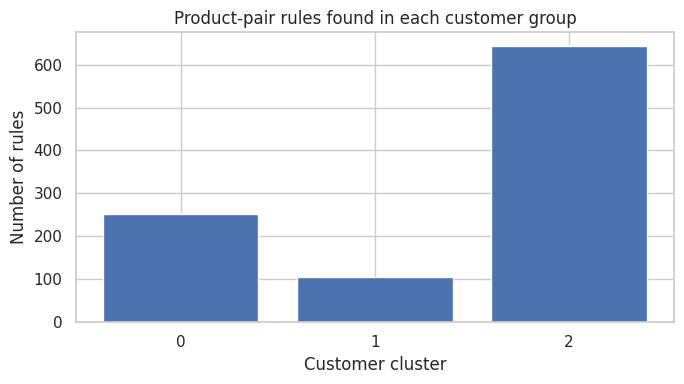

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [169]:
# Graph 1 — Number of rules for each cluster
plt.figure(figsize=(7, 4))
plt.bar(rule_summary['Cluster'].astype(str), rule_summary['Rules'])
plt.title('Product-pair rules found in each customer group')
plt.xlabel('Customer cluster')
plt.ylabel('Number of rules')
plt.tight_layout()
plt.savefig(secondary_folder / 'graph_1_rule_counts.png', dpi=150, bbox_inches='tight')
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

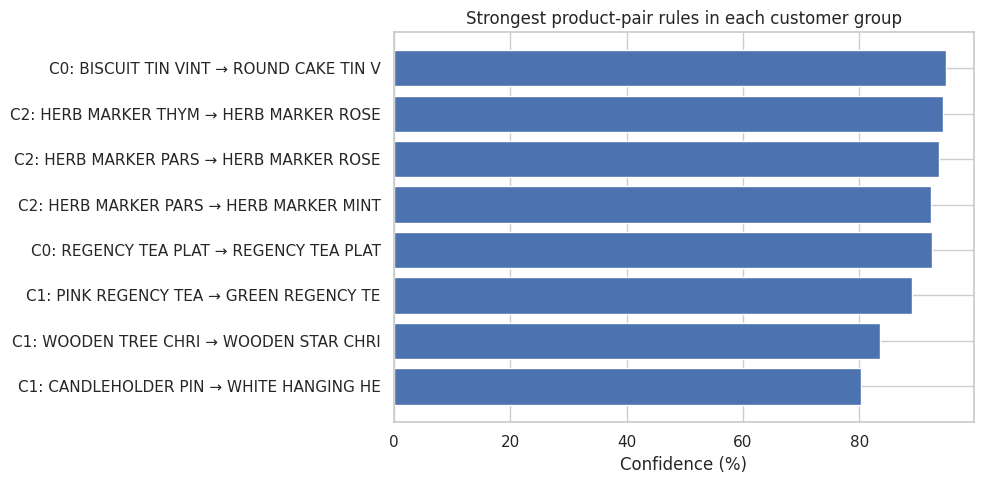

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [170]:
# Graph 2 — Top three rules from each cluster, by confidence
if rules_df.empty:
    print('Graph 2: no rules to show.')
else:
    chart_rules = (rules_df.sort_values('confidence', ascending=False)
                   .groupby('Cluster').head(3).copy())
    chart_rules['Pair'] = (
        'C' + chart_rules['Cluster'].astype(str) + ': ' +
        chart_rules['Product A'].astype(str).str[:16] + ' → ' +
        chart_rules['Product B'].astype(str).str[:16]
    )
    chart_rules = chart_rules.sort_values('confidence')

    plt.figure(figsize=(10, 5))
    plt.barh(chart_rules['Pair'], chart_rules['confidence'] * 100)
    plt.xlabel('Confidence (%)')
    plt.title('Strongest product-pair rules in each customer group')
    plt.tight_layout()
    plt.savefig(secondary_folder / 'graph_2_rule_confidence.png', dpi=150, bbox_inches='tight')
    plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

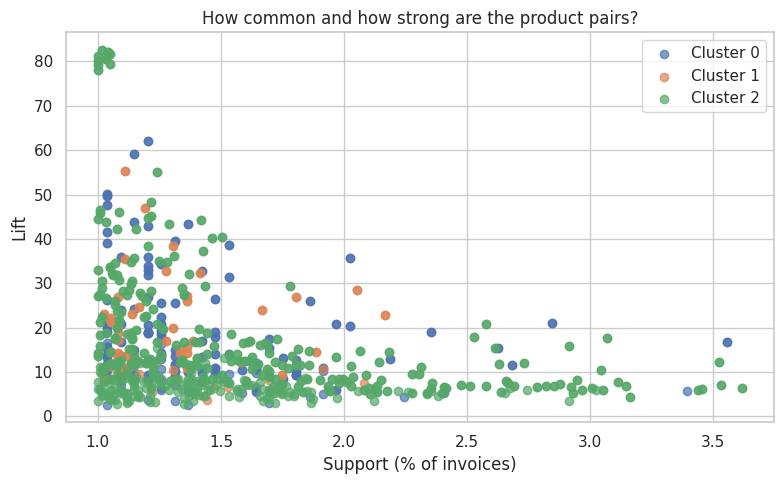

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [171]:
# Graph 3 — Support and lift for the rules we found
if rules_df.empty:
    print('Graph 3: no rules to show.')
else:
    plt.figure(figsize=(8, 5))
    for cluster in [0, 1, 2]:
        part = rules_df[rules_df['Cluster'] == cluster]
        if not part.empty:
            plt.scatter(part['support'] * 100, part['lift'],
                        label=f'Cluster {cluster}', alpha=0.7)
    plt.xlabel('Support (% of invoices)')
    plt.ylabel('Lift')
    plt.title('How common and how strong are the product pairs?')
    plt.legend()
    plt.tight_layout()
    plt.savefig(secondary_folder / 'graph_3_support_vs_lift.png', dpi=150, bbox_inches='tight')
    plt.show()

## Step 5 — Save the results

We only need two CSV tables for the report: a count of the rules by group, and the product-pair rules themselves. The three graphs are also saved automatically as PNG images.

In [172]:
rule_summary.to_csv(secondary_folder / 'rule_summary.csv', index=False)

if not rules_df.empty:
    rules_df[['Cluster', 'Segment', 'Product A', 'Product B',
              'support', 'confidence', 'lift']].to_csv(
        secondary_folder / 'product_pair_rules.csv', index=False)
else:
    pd.DataFrame(columns=['Cluster', 'Segment', 'Product A', 'Product B',
                          'support', 'confidence', 'lift']).to_csv(
        secondary_folder / 'product_pair_rules.csv', index=False)

print('Results saved to:', secondary_folder)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Results saved to: /content/drive/MyDrive/ML Project/project_outputs/secondary_lens


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## What do these results mean for the retailer?

The **primary lens** tells us which type of customer we're looking at. The **secondary lens** tells us which products are commonly bought together *within that customer group*.

In the report, we'll choose a few rules with reasonable support, confidence and lift, and explain whether the product pairs make sense as cross-selling or bundle ideas. For example, we can consider relevant pairs for loyal customers and simpler offers for less active customers — **but only if the actual rules support those suggestions**.

**Limits:** These patterns come from historical purchases. A rule shows an association, not proof that a bundle will increase sales. We should also mention if some groups have very few rules or if the thresholds strongly affect what we find.

*Assignment note:* Keep our Apriori decision and these limitations in the final decision log. The final report also needs the group's real contribution record and an honest AI-use statement.